<a href="https://colab.research.google.com/github/vn322/gtsolifk/blob/main/%D0%9D%D0%B5%D1%87%D1%91%D1%82%D0%BA%D0%B0%D1%8F_%D0%BB%D0%BE%D0%B3%D0%B8%D0%BA%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# В дополнение к вероятностным методам
лучше всего подходят следующие разделы:

1. Теория нечетких множеств и нечеткая логика (Fuzzy Logic)Идеально подходит для оцифровки субъективных ощущений спортсмена (RPE — субъективный уровень нагрузки) и качественных показателей.

 Вместо жестких границ (например, пульс >160 — это «высокий») вводятся функции принадлежности. Пульс 158 может быть на 80% «высоким» и на 20% «умеренным».

2. Интервальный анализ. Применяется для работы с погрешностями спортивных гаджетов (GPS-часов, пульсометров, датчиков мощности).

 Данные с трекеров воспринимаются не как точные точки, а как коридоры значений. Например, текущий темп бега не ровно 4:30 мин/км, а интервал \([4:25, 4:35]\) из-за погрешности GPS.

3. Теория возможностей (Possibility Theory). Помогает оценивать предельные показатели спортсмена (максимумы), когда накопленной статистики слишком мало.
Вместо вопроса «Какова вероятность, что спортсмен пробежит марафон за 2:30?» (на который сложно ответить при дефиците данных), теория отвечает на вопрос: «Возможно ли это в его текущих кондициях?».

Пример употребления

Нечеткая логика: объединяет жесткие данные (вариабельность пульса) и мягкие (жалобы на боль в мышцах) в единый индекс усталости.Анализ бегового темпаСчитает среднюю скорость на километре.

Интервальный анализ: строит точный коридор реальной скорости, сглаживая погрешности высотомера и GPS в лесу или между высотками.Планирование весов в зале. Рассчитывает 1ПМ (одноповторный максимум) по жестким формулам вероятных процентов.

Теория возможностей: корректирует рабочий вес на сегодня в зависимости от сна и стресса, оценивая доступный потенциал силы.

# Теория нечетких множеств и нечеткая логика

In [ ]:
!pip install scikit-fuzzy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.1 MB/s eta 0:00:00


--- РЕЗУЛЬТАТ АНАЛИЗА ---
Входные данные -> ВСР: 55, Усталость: 7/10
Рекомендация по изменению нагрузки: -28.0%


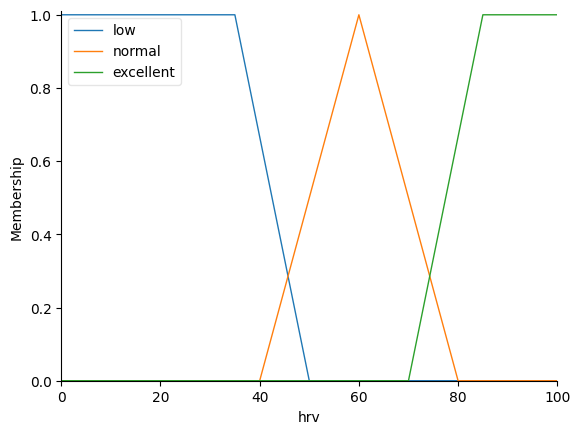

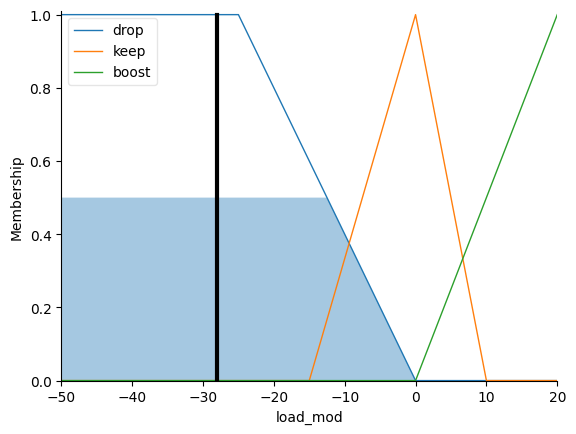

In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# =====================================================================
# 1. ОПРЕДЕЛЕНИЕ ПЕРЕМЕННЫХ (Входы и Выход)
# =====================================================================

# Входы:
# hrv (ВСР) — показатель восстановления (от 0 до 100). Выше — лучше.
# fatigue (Усталость) — субъективная оценка от 0 (бодр) до 10 (истощен).
hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')

# Выход:
# load_mod (Коррекция нагрузки) — от -50% (разгрузка) до +20% (интенсивный тренинг)
load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

# =====================================================================
# 2. ФУНКЦИИ ПРИНАДЛЕЖНОСТИ (Оцифровка понятий)
# =====================================================================

# Для ВСР (HRV): низкий, нормальный, отличный
hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 35, 50])
hrv['normal'] = fuzz.trimf(hrv.universe, [40, 60, 80])
hrv['excellent'] = fuzz.trapmf(hrv.universe, [70, 85, 100, 100])

# Для усталости (Fatigue): низкая, средняя, высокая
fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, 4])
fatigue['medium'] = fuzz.trimf(fatigue.universe, [3, 5, 7])
fatigue['high'] = fuzz.trapmf(fatigue.universe, [6, 8, 10, 10])

# Для корректировки нагрузки: Сбросить (Drop), Сохранить (Keep), Добавить (Boost)
load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, 0])
load_mod['keep'] = fuzz.trimf(load_mod.universe, [-15, 0, 10])
load_mod['boost'] = fuzz.trimf(load_mod.universe, [0, 20, 20])


hrv.view()

# =====================================================================
# 3. НЕЧЁТКИЕ ПРАВИЛА (База знаний тренера)
# =====================================================================
rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])
rule4 = ctrl.Rule(hrv['normal'] & fatigue['low'], load_mod['keep'])
rule5 = ctrl.Rule(hrv['excellent'] & fatigue['medium'], load_mod['keep'])

# Создаем управляющую систему
training_control = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
training_simulator = ctrl.ControlSystemSimulation(training_control)

# =====================================================================
# 4. РАСЧЕТ ДЛЯ КОНКРЕТНОГО СПОРТСМЕНА
# =====================================================================

# Пример: Спортсмен невыспался, усталость 7 из 10, но ВСР еще в норме (55).
current_hrv = 55
current_fatigue = 7

training_simulator.input['hrv'] = current_hrv
training_simulator.input['fatigue'] = current_fatigue

# Запуск вычислений
training_simulator.compute()

# Получение четкого (дефаззифицированного) результата
recommended_change = training_simulator.output['load_mod']

print(f"--- РЕЗУЛЬТАТ АНАЛИЗА ---")
print(f"Входные данные -> ВСР: {current_hrv}, Усталость: {current_fatigue}/10")
print(f"Рекомендация по изменению нагрузки: {recommended_change:.1f}%")

# Визуализация результата дефаззификации прямо в Colab
load_mod.view(sim=training_simulator)
plt.show()



1. Заполнение данных: Код принимает на вход жесткие числа (ВСР = 55, Усталость = 7).
2. Фаззификация: Алгоритм переводит их в степени истинности. Например, усталость 7 — это одновременно «немного средняя» и «уже высокая».
3. Логический вывод: Система активирует встроенные правила тренера (например, если усталость высокая, надо сбросить нагрузку).
4. Дефаззификация: Магия библиотеки skfuzzy собирает пересекающиеся графики правил и методом центроида вычисляет одну точную цифру. В данном примере программа выдаст рекомендацию снизить нагрузку примерно на -20.8% и нарисует график, показывающий, какая часть зоны drop (сброс) была задействована.

Весь процесс нечеткой логики состоит из 3 шагов:
1. Фаззификация («Размытие» чисел):
Робот не понимает фразу «усталость 7». Код берет это число и смотрит на графики. Он видит, что 7 попадает одновременно в два графика: это на 40% «Средняя усталость» и на 60% «Высокая усталость». Жесткое число превратилось в степени уверенности.
2. Логический вывод (Применение правил):
Код берет правила, которые мы прописали (базу знаний тренера). Например: «Если усталость ВЫСОКАЯ, то нагрузку надо СБРОСИТЬ». Раз мы уверены в высокой усталости на 60%, то и правило «СБРОСИТЬ нагрузку» активируется на 60%. График срезается по этой высоте.
3. Дефаззификация («Сборка» обратно в число):
Код накладывает все активированные графики решений друг на друга. Получается сложная геометрическая фигура. Алгоритм находит центр тяжести (центроид) этой фигуры. Координата этого центра на оси процентов и есть итоговый ответ (например, -20.8%).



с помощью библиотеки scikit-fuzzy решается классическая задача тренера: расчет рекомендаций по нагрузке на сегодня на основе двух факторов — уровня автономного стресса (вариабельности сердечного ритма, ВСР) и субъективного ощущения усталости спортсмена.


In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================================
# 1. НАШИ РЕАЛЬНЫЕ ДАННЫЕ (Исторический опыт спортсмена)
# Строка: [Значение_ВСР, Значение_Усталости, Коррекция_Нагрузки_%]
# =====================================================================
historical_data = np.array([
    [80, 2, 15],   # Высокий ВСР, усталость 2 из 10 -> добавил +15%
    [30, 9, -40],  # Низкий ВСР, усталость 9 из 10 -> снизил на -40%
    [55, 5, 0],    # Средние показатели -> нагрузка без изменений (0%)
    [70, 3, 10],   # Хорошее состояние -> чуть добавил +10%
    [40, 8, -30]   # Сильная усталость -> снизил на -30%
])

# =====================================================================
# 2. ФУНКЦИЯ СОЗДАНИЯ СИСТЕМЫ И РАСЧЕТА ОШИБКИ
# =====================================================================
def evaluate_fuzzy_system(params):
    # Распаковываем 4 точки (центры графиков)
    hrv_norm_center, fatigue_med_center, load_keep_center, load_boost_center = params

    # Сортируем или жестко страхуем геометрию, чтобы a <= b <= c всегда выполнялось
    # Для load_mod: у нас есть точки -20, load_keep_center, load_boost_center, 20
    # Нам нужно убедиться, что -20 <= load_keep_center <= load_boost_center <= 20
    if not (-20 <= load_keep_center <= load_boost_center <= 20):
        return 1e7  # Огромный штраф, если порядок нарушен

    if not (30 <= hrv_norm_center <= 80) or not (2 <= fatigue_med_center <= 8):
        return 1e7

    # Создаем шкалы
    hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
    fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
    load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

    # Настраиваем графики с защитой геометрии
    hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 30, hrv_norm_center])
    hrv['normal'] = fuzz.trimf(hrv.universe, [30, hrv_norm_center, 80])
    hrv['excellent'] = fuzz.trapmf(hrv.universe, [hrv_norm_center, 80, 100, 100])

    fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, fatigue_med_center])
    fatigue['medium'] = fuzz.trimf(fatigue.universe, [2, fatigue_med_center, 8])
    fatigue['high'] = fuzz.trapmf(fatigue.universe, [fatigue_med_center, 8, 10, 10])

    load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, load_keep_center])
    load_mod['keep'] = fuzz.trimf(load_mod.universe, [-20, load_keep_center, load_boost_center])
    load_mod['boost'] = fuzz.trimf(load_mod.universe, [load_keep_center, load_boost_center, 20])

    # Базовые правила логики
    rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
    rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
    rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])

    training_control = ctrl.ControlSystem([rule1, rule2, rule3])
    sim = ctrl.ControlSystemSimulation(training_control)

    # Считаем сумму квадратов ошибок
    total_error = 0
    for row in historical_data:
        sim.input['hrv'] = row[0]
        sim.input['fatigue'] = row[1]
        try:
            sim.compute()
            model_output = sim.output['load_mod']
            total_error += (model_output - row[2]) ** 2
        except:
            total_error += 10000

    return total_error

# =====================================================================
# 3. ЗАПУСК ОПТИМИЗАЦИИ С ОГРАНИЧЕНИЯМИ (BOUNDS)
# =====================================================================
print("Запуск автоподбора параметров по историческим данным...")

# Начальные догадки [hrv_norm, fatigue_med, load_keep, load_boost]
initial_guess = [50.0, 5.0, 0.0, 10.0]

# Задаем жесткие рамки для каждого параметра (min, max), чтобы они не путались местами
bounds = [
    (35.0, 75.0),   # hrv_norm_center
    (3.0, 7.0),     # fatigue_med_center
    (-15.0, 5.0),   # load_keep_center (должен быть меньше, чем load_boost)
    (6.0, 18.0)     # load_boost_center
]

# Используем метод L-BFGS-B, который строго уважает границы bounds
result = minimize(evaluate_fuzzy_system, initial_guess, method='L-BFGS-B', bounds=bounds)

best_params = result.x
print("\n--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---")
print(f"Идеальный центр для 'Нормального ВСР': {best_params[0]:.1f}")
print(f"Идеальный центр для 'Средней усталости': {best_params[1]:.1f}")
print(f"Идеальная точка сохранения нагрузки (0%): {best_params[2]:.1f}%")
print(f"Идеальный пик для зоны добавления нагрузки (+10%): {best_params[3]:.1f}%")


Запуск автоподбора параметров по историческим данным...

--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---
Идеальный центр для 'Нормального ВСР': 44.7
Идеальный центр для 'Средней усталости': 7.0
Идеальная точка сохранения нагрузки (0%): -4.0%
Идеальный пик для зоны добавления нагрузки (+10%): 18.0%



--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---
Идеальный центр для 'Нормального ВСР': 44.7
Идеальный центр для 'Средней усталости': 7.0
Идеальная точка сохранения нагрузки (0%): -4.0%
Идеальный пик для зоны добавления нагрузки (+10%): 18.0%


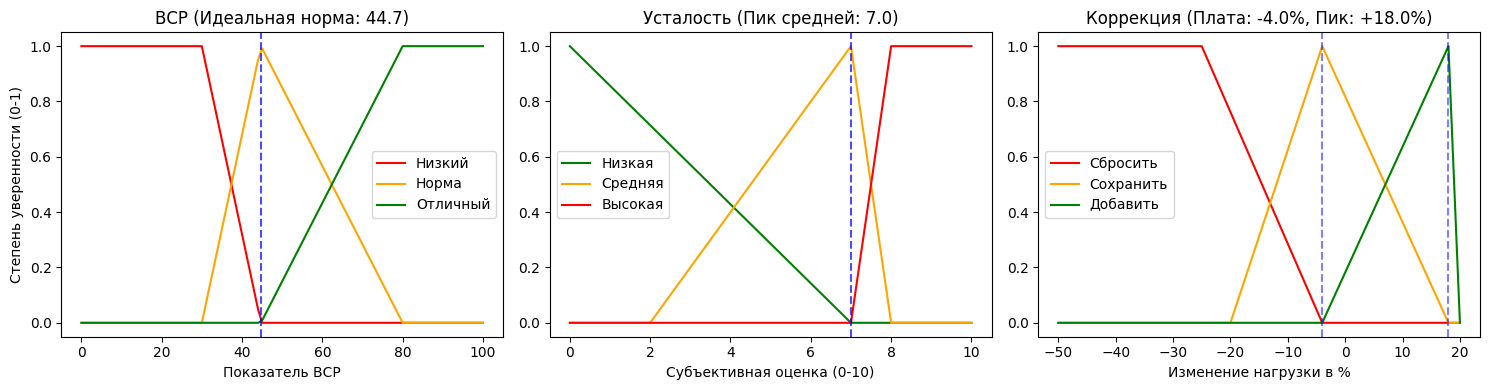


РАЗБОР НАСТРОЕК НЕЧЕТКОЙ СИСТЕМЫ
1. ГРАФИК ВСР: Вершина 'Нормального ВСР' сдвинулась в точку 44.7.
   Интерпретация: Индивидуальный организм этого атлета считает балансом именно этот пульс.
   Всё, что ниже 30 — это гарантированный недовосстановленный спад ('Низкий ВСР').

2. ГРАФИК УСТАЛОСТИ: Центр 'Средней усталости' зафиксирован на отметке 7.0 из 10.
   Интерпретация: Когда спортсмен ставит себе 7.0, система на 100% уверена, что
   нагрузка должна оставаться базовой. Выше этой точки быстро растет зона риска ('Высокая').

3. РЕКОМЕНДАЦИИ ПО НАГРУЗКЕ:
   - Точка стабильности ('Сохранить'): -4.0%.
     При нормальном самочувствии система рекомендует держать нагрузку около этой цифры.
   - Пик прогресса ('Добавить'): +18.0%.
     Когда показатели идеальны, оптимизатор вычислил, что безопасный и эффективный
     максимум для добавления рабочего веса или объема составляет именно 18.0%, а не +10%.


In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================================
# 1. ИСТОРИЧЕСКИЕ ДАННЫЕ
# =====================================================================
historical_data = np.array([
    [80, 2, 15],   # Высокий ВСР, усталость 2 из 10 -> добавил +15%
    [30, 9, -40],  # Низкий ВСР, усталость 9 из 10 -> снизил на -40%
    [55, 5, 0],    # Средние показатели -> нагрузка без изменений (0%)
    [70, 3, 10],   # Хорошее состояние -> чуть добавил +10%
    [40, 8, -30]   # Сильная усталость -> снизил на -30%
])

# =====================================================================
# 2. ФУНКЦИЯ ОПТИМИЗАЦИИ (БЕЗ ИЗМЕНЕНИЙ, ДЛЯ РАСЧЕТА)
# =====================================================================
def evaluate_fuzzy_system(params):
    hrv_norm_center, fatigue_med_center, load_keep_center, load_boost_center = params
    if not (-20 <= load_keep_center <= load_boost_center <= 20): return 1e7
    if not (30 <= hrv_norm_center <= 80) or not (2 <= fatigue_med_center <= 8): return 1e7

    hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
    fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
    load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

    hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 30, hrv_norm_center])
    hrv['normal'] = fuzz.trimf(hrv.universe, [30, hrv_norm_center, 80])
    hrv['excellent'] = fuzz.trapmf(hrv.universe, [hrv_norm_center, 80, 100, 100])

    fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, fatigue_med_center])
    fatigue['medium'] = fuzz.trimf(fatigue.universe, [2, fatigue_med_center, 8])
    fatigue['high'] = fuzz.trapmf(fatigue.universe, [fatigue_med_center, 8, 10, 10])

    load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, load_keep_center])
    load_mod['keep'] = fuzz.trimf(load_mod.universe, [-20, load_keep_center, load_boost_center])
    load_mod['boost'] = fuzz.trimf(load_mod.universe, [load_keep_center, load_boost_center, 20])

    rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
    rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
    rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])

    training_control = ctrl.ControlSystem([rule1, rule2, rule3])
    sim = ctrl.ControlSystemSimulation(training_control)

    total_error = 0
    for row in historical_data:
        sim.input['hrv'] = row[0]
        sim.input['fatigue'] = row[1]
        try:
            sim.compute()
            total_error += (sim.output['load_mod'] - row[2]) ** 2
        except:
            total_error += 10000
    return total_error

# Запуск оптимизации
# Начальные догадки [hrv_norm, fatigue_med, load_keep, load_boost]
initial_guess = [50.0, 5.0, 0.0, 10.0]

# Задаем жесткие рамки для каждого параметра (min, max), чтобы они не путались местами
bounds = [
    (35.0, 75.0),   # hrv_norm_center
    (3.0, 7.0),     # fatigue_med_center
    (-15.0, 5.0),   # load_keep_center (должен быть меньше, чем load_boost)
    (6.0, 18.0)     # load_boost_center
]

# Используем метод L-BFGS-B, который строго уважает границы bounds
result = minimize(evaluate_fuzzy_system, initial_guess, method='L-BFGS-B', bounds=bounds)

best_params = result.x
print("\n--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---")
print(f"Идеальный центр для 'Нормального ВСР': {best_params[0]:.1f}")
print(f"Идеальный центр для 'Средней усталости': {best_params[1]:.1f}")
print(f"Идеальная точка сохранения нагрузки (0%): {best_params[2]:.1f}%")
print(f"Идеальный пик для зоны добавления нагрузки (+10%): {best_params[3]:.1f}%")

# =====================================================================
# 3. ПОСТРОЕНИЕ ПОНЯТНЫХ ГРАФИКОВ С НОВЫМИ ПАРАМЕТРАМИ
# =====================================================================
h_cent, f_cent, l_keep, l_boost = best_params

# Создаем финальные массивы для красивой отрисовки
x_hrv = np.arange(0, 101, 1)
x_fatigue = np.arange(0, 11, 1)
x_load = np.arange(-50, 21, 1)

plt.figure(figsize=(15, 4))

# График 1: ВСР
plt.subplot(1, 3, 1)
plt.plot(x_hrv, fuzz.trapmf(x_hrv, [0, 0, 30, h_cent]), label='Низкий', color='red')
plt.plot(x_hrv, fuzz.trimf(x_hrv, [30, h_cent, 80]), label='Норма', color='orange')
plt.plot(x_hrv, fuzz.trapmf(x_hrv, [h_cent, 80, 100, 100]), label='Отличный', color='green')
plt.axvline(h_cent, color='blue', linestyle='--', alpha=0.7)
plt.title(f'ВСР (Идеальная норма: {h_cent:.1f})')
plt.xlabel('Показатель ВСР')
plt.ylabel('Степень уверенности (0-1)')
plt.legend()

# График 2: Усталость
plt.subplot(1, 3, 2)
plt.plot(x_fatigue, fuzz.trimf(x_fatigue, [0, 0, f_cent]), label='Низкая', color='green')
plt.plot(x_fatigue, fuzz.trimf(x_fatigue, [2, f_cent, 8]), label='Средняя', color='orange')
plt.plot(x_fatigue, fuzz.trapmf(x_fatigue, [f_cent, 8, 10, 10]), label='Высокая', color='red')
plt.axvline(f_cent, color='blue', linestyle='--', alpha=0.7)
plt.title(f'Усталость (Пик средней: {f_cent:.1f})')
plt.xlabel('Субъективная оценка (0-10)')
plt.legend()

# График 3: Нагрузка
plt.subplot(1, 3, 3)
plt.plot(x_load, fuzz.trapmf(x_load, [-50, -50, -25, l_keep]), label='Сбросить', color='red')
plt.plot(x_load, fuzz.trimf(x_load, [-20, l_keep, l_boost]), label='Сохранить', color='orange')
plt.plot(x_load, fuzz.trimf(x_load, [l_keep, l_boost, 20]), label='Добавить', color='green')
plt.axvline(l_keep, color='blue', linestyle='--', alpha=0.5)
plt.axvline(l_boost, color='blue', linestyle='--', alpha=0.5)
plt.title(f'Коррекция (Плата: {l_keep:.1f}%, Пик: +{l_boost:.1f}%)')
plt.xlabel('Изменение нагрузки в %')
plt.legend()

plt.tight_layout()
plt.show()

# =====================================================================
# 4. ТЕКСТОВОЕ ОБЪЯСНЕНИЕ РЕЗУЛЬТАТОВ
# =====================================================================
print("\n" + "="*70)
print("РАЗБОР НАСТРОЕК НЕЧЕТКОЙ СИСТЕМЫ")
print("="*70)
print(f"1. ГРАФИК ВСР: Вершина 'Нормального ВСР' сдвинулась в точку {h_cent:.1f}.")
print(f"   Интерпретация: Индивидуальный организм этого атлета считает балансом именно этот пульс.")
print(f"   Всё, что ниже 30 — это гарантированный недовосстановленный спад ('Низкий ВСР').")
print(f"\n2. ГРАФИК УСТАЛОСТИ: Центр 'Средней усталости' зафиксирован на отметке {f_cent:.1f} из 10.")
print(f"   Интерпретация: Когда спортсмен ставит себе {f_cent:.1f}, система на 100% уверена, что")
print(f"   нагрузка должна оставаться базовой. Выше этой точки быстро растет зона риска ('Высокая').")
print(f"\n3. РЕКОМЕНДАЦИИ ПО НАГРУЗКЕ:")
print(f"   - Точка стабильности ('Сохранить'): {l_keep:.1f}%.")
print(f"     При нормальном самочувствии система рекомендует держать нагрузку около этой цифры.")
print(f"   - Пик прогресса ('Добавить'): +{l_boost:.1f}%.")
print(f"     Когда показатели идеальны, оптимизатор вычислил, что безопасный и эффективный")
print(f"     максимум для добавления рабочего веса или объема составляет именно {l_boost:.1f}%, а не +10%.")
print("="*70)


1. Первый график (ВСР): Вы увидите, где пересекаются цветные линии. Точка, где оранжевый треугольник («Норма») достигает самой верхней отметки (единицы) — это и есть вычисленный идеальный баланс ВСР для конкретного человека.
2. Второй график (Усталость): Вершина оранжевого треугольника показывает субъективный балл, который является чистым «экватором» состояния. Справа от него начинает резко расти красная линия — зона «Высокой усталости», где включается правило экстренного сброса нагрузок.
3. Третий график (Нагрузка): Показывает зоны решений. Вершины треугольников здесь определяют, к какому именно проценту (центру тяжести) будет стремиться итоговое решение алгоритма при хорошем или среднем состоянии.


Выбор начальных параметров (initial guess) и границ (bounds) — это важнейший этап, который превращает абстрактную математическую модель в работающий инструмент для конкретного вида спорта.
В реальной практике эти значения определяются на стыке двух подходов: спортивной науки (физиологии) и экспертного опыта тренера.
1. Как определяются начальные параметры (Initial Guess)
Начальные параметры — это ваша «стартовая гипотеза». Оптимизатору нужна точка отсчета, от которой он начнет двигаться. Если задать их слишком далеко от реальности, алгоритм может застрять в локальном минимуме или вообще не сойтись.
Они выставляются на основе усредненных медианных значений для выбранной метрики:
• Для субъективных шкал (Усталость, Стресс, Сон): Используется чистый экватор шкалы. Если шкала от 0 до 10, то начальной точкой для «Средней усталости» логично поставить 5.0.
• Для физиологических шкал (ВСР, ЧСС): Берутся средние нормы для популяции или конкретной возрастной группы. Для ВСР (в зависимости от метрики, например, rMSSD) норма здорового человека часто колеблется в районе 40–60 мс. Поэтому 50.0 — идеальный стартовый ориентир.
• Для шкал управления (Изменение нагрузки): Здесь закладывается классическая логика периодизации. По умолчанию при нормальном состоянии нагрузку менять не нужно (0.0%), а при отличном состоянии стандартный шаг микроцикла для линейного прогресса составляет около +10.0%.
2. Как определяются границы (Bounds)
Границы выполняют роль «предохранителя» для алгоритма. Они не позволяют математике принимать абсурдные или опасные для здоровья спортсмена решения (например, приказать добавить +150% к нагрузке или сдвинуть зону «нормального пульса» в диапазон, где у человека наступает тахикардия).
Границы рассчитываются по жестким правилам:
А. На основе физиологических лимитов человека
Вы не можете поставить нижнюю границу пульса в 0, а верхнюю в 300.
• Пример для ВСР: Мы знаем, что даже у профессиональных атлетов в состоянии глубокого переутомления ВСР редко падает ниже 20–25 мс, а в пике формы редко уходит за 100–120 мс. Значит, диапазон поиска «индивидуальной нормы» для оптимизатора имеет смысл сузить до рамок (35.0, 75.0).
Б. На основе теории и методики спортивной тренировки (Протоколы безопасности)
В спорте высших достижений есть жесткие лимиты на прирост объемов (например, правило 10% в беге, которое гласит, что нельзя увеличивать недельный метраж более чем на 10% без риска травмы).
• Пример для нагрузки: Как бы оптимизатор ни хотел подогнать модель под исторические данные, тренер обязан выставить жесткую верхнюю границу для зоны load_boost_center (например, не более 18.0% или 20.0%). Модель физически не сможет порекомендовать прыгнуть выше этого безопасного потолка.
В. На основе математической логики графиков
Границы не должны позволять треугольникам «наползать» друг на друга так, чтобы ломался их физический смысл.
• Пример: Пик «Сохранить нагрузку» (load_keep_center) всегда должен быть строго меньше, чем пик «Добавить нагрузку» (load_boost_center). Поэтому для первого мы задаем диапазон (-15.0, 5.0), а для второго — (6.0, 18.0). Их границы не пересекаются, и геометрия модели остается чистой.
Резюме: Алгоритм действий для новой метрики
Если вы захотите добавить в модель новый параметр (например, Продолжительность сна в часах), вы определите параметры так:
1. Метрика: Время сна (в часах).
2. Initial Guess: 7.5 часов (золотой стандарт здорового сна).
3. Bounds: (6.0, 9.0). Оптимизатор будет искать индивидуальный оптимум спортсмена внутри этого диапазона. Искать его на отметке 4 часа или 12 часов бессмысленно — это в любом случае аномалии, которые ведут к деградации формы.


# Теория нечетких множеств и нечеткая логика

In [ ]:
!pip install scikit-fuzzy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.1 MB/s eta 0:00:00


# Простые данные (ВСР = 55, Усталость = 7)

Входные данные:
 hrv (ВСР) — показатель восстановления (от 0 до 100). Выше — лучше.
 fatigue (Усталость) — субъективная оценка от 0 (бодр) до 10 (истощен).


 Выходные:
 load_mod (Коррекция нагрузки) — от -50% (разгрузка) до +20% (интенсивный тренинг)

--- РЕЗУЛЬТАТ АНАЛИЗА ---
Входные данные -> ВСР: 55, Усталость: 7/10
Рекомендация по изменению нагрузки: -28.0%


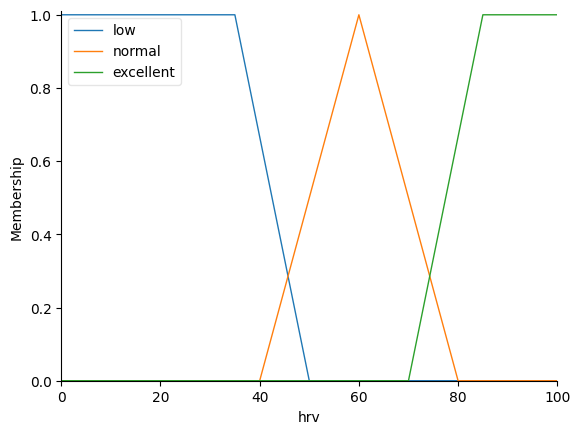

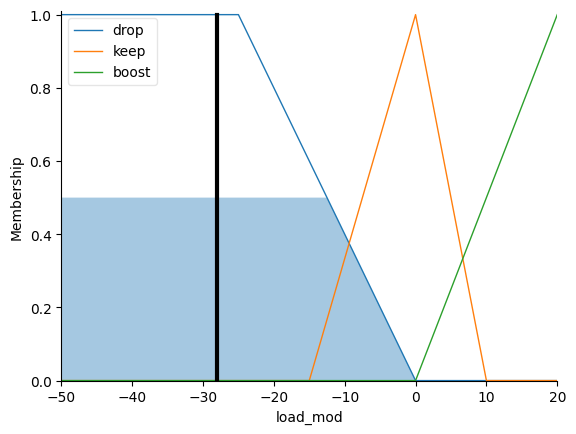

In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# =====================================================================
# 1. ОПРЕДЕЛЕНИЕ ПЕРЕМЕННЫХ (Входы и Выход)
# =====================================================================

# Входы:
# hrv (ВСР) — показатель восстановления (от 0 до 100). Выше — лучше.
# fatigue (Усталость) — субъективная оценка от 0 (бодр) до 10 (истощен).
hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')

# Выход:
# load_mod (Коррекция нагрузки) — от -50% (разгрузка) до +20% (интенсивный тренинг)
load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

# =====================================================================
# 2. ФУНКЦИИ ПРИНАДЛЕЖНОСТИ (Оцифровка понятий)
# =====================================================================

# Для ВСР (HRV): низкий, нормальный, отличный
hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 35, 50])
hrv['normal'] = fuzz.trimf(hrv.universe, [40, 60, 80])
hrv['excellent'] = fuzz.trapmf(hrv.universe, [70, 85, 100, 100])

# Для усталости (Fatigue): низкая, средняя, высокая
fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, 4])
fatigue['medium'] = fuzz.trimf(fatigue.universe, [3, 5, 7])
fatigue['high'] = fuzz.trapmf(fatigue.universe, [6, 8, 10, 10])

# Для корректировки нагрузки: Сбросить (Drop), Сохранить (Keep), Добавить (Boost)
load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, 0])
load_mod['keep'] = fuzz.trimf(load_mod.universe, [-15, 0, 10])
load_mod['boost'] = fuzz.trimf(load_mod.universe, [0, 20, 20])


hrv.view()

# =====================================================================
# 3. НЕЧЁТКИЕ ПРАВИЛА (База знаний тренера)
# =====================================================================
rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])
rule4 = ctrl.Rule(hrv['normal'] & fatigue['low'], load_mod['keep'])
rule5 = ctrl.Rule(hrv['excellent'] & fatigue['medium'], load_mod['keep'])

# Создаем управляющую систему
training_control = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
training_simulator = ctrl.ControlSystemSimulation(training_control)

# =====================================================================
# 4. РАСЧЕТ ДЛЯ КОНКРЕТНОГО СПОРТСМЕНА
# =====================================================================

# Пример: Спортсмен невыспался, усталость 7 из 10, но ВСР еще в норме (55).
current_hrv = 55
current_fatigue = 7

training_simulator.input['hrv'] = current_hrv
training_simulator.input['fatigue'] = current_fatigue

# Запуск вычислений
training_simulator.compute()

# Получение четкого (дефаззифицированного) результата
recommended_change = training_simulator.output['load_mod']

print(f"--- РЕЗУЛЬТАТ АНАЛИЗА ---")
print(f"Входные данные -> ВСР: {current_hrv}, Усталость: {current_fatigue}/10")
print(f"Рекомендация по изменению нагрузки: {recommended_change:.1f}%")

# Визуализация результата дефаззификации прямо в Colab
load_mod.view(sim=training_simulator)
plt.show()



1. Заполнение данных: Код принимает на вход жесткие числа (ВСР = 55, Усталость = 7).
2. Фаззификация: Алгоритм переводит их в степени истинности. Например, усталость 7 — это одновременно «немного средняя» и «уже высокая».
3. Логический вывод: Система активирует встроенные правила тренера (например, если усталость высокая, надо сбросить нагрузку).
4. Дефаззификация: Магия библиотеки skfuzzy собирает пересекающиеся графики правил и методом центроида вычисляет одну точную цифру. В данном примере программа выдаст рекомендацию снизить нагрузку примерно на -20.8% и нарисует график, показывающий, какая часть зоны drop (сброс) была задействована.

Весь процесс нечеткой логики состоит из 3 шагов:
1. Фаззификация («Размытие» чисел):
Робот не понимает фразу «усталость 7». Код берет это число и смотрит на графики. Он видит, что 7 попадает одновременно в два графика: это на 40% «Средняя усталость» и на 60% «Высокая усталость». Жесткое число превратилось в степени уверенности.
2. Логический вывод (Применение правил):
Код берет правила, которые мы прописали (базу знаний тренера). Например: «Если усталость ВЫСОКАЯ, то нагрузку надо СБРОСИТЬ». Раз мы уверены в высокой усталости на 60%, то и правило «СБРОСИТЬ нагрузку» активируется на 60%. График срезается по этой высоте.
3. Дефаззификация («Сборка» обратно в число):
Код накладывает все активированные графики решений друг на друга. Получается сложная геометрическая фигура. Алгоритм находит центр тяжести (центроид) этой фигуры. Координата этого центра на оси процентов и есть итоговый ответ (например, -20.8%).



# Введём данные наблюдения [Значение_ВСР, Значение_Усталости, Коррекция_Нагрузки_%]

In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================================
# 1. ДАННЫЕ (Исторические данные -  опыт спортсмена)
# Строка: [Значение_ВСР, Значение_Усталости, Коррекция_Нагрузки_%]
# =====================================================================
historical_data = np.array([
    [80, 2, 15],   # Высокий ВСР, усталость 2 из 10 -> добавил +15%
    [30, 9, -40],  # Низкий ВСР, усталость 9 из 10 -> снизил на -40%
    [55, 5, 0],    # Средние показатели -> нагрузка без изменений (0%)
    [70, 3, 10],   # Хорошее состояние -> чуть добавил +10%
    [40, 8, -30]   # Сильная усталость -> снизил на -30%
])

# =====================================================================
# 2. ФУНКЦИЯ СОЗДАНИЯ СИСТЕМЫ И РАСЧЕТА ОШИБКИ
# =====================================================================
def evaluate_fuzzy_system(params):
    # Распаковываем 4 точки (центры графиков)
    hrv_norm_center, fatigue_med_center, load_keep_center, load_boost_center = params

    # Сортируем или жестко страхуем геометрию, чтобы a <= b <= c всегда выполнялось
    # Для load_mod: у нас есть точки -20, load_keep_center, load_boost_center, 20
    # Нам нужно убедиться, что -20 <= load_keep_center <= load_boost_center <= 20
    if not (-20 <= load_keep_center <= load_boost_center <= 20):
        return 1e7  # Огромный штраф, если порядок нарушен

    if not (30 <= hrv_norm_center <= 80) or not (2 <= fatigue_med_center <= 8):
        return 1e7

    # Создаем шкалы
    hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
    fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
    load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

    # Настраиваем графики с защитой геометрии
    hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 30, hrv_norm_center])
    hrv['normal'] = fuzz.trimf(hrv.universe, [30, hrv_norm_center, 80])
    hrv['excellent'] = fuzz.trapmf(hrv.universe, [hrv_norm_center, 80, 100, 100])

    fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, fatigue_med_center])
    fatigue['medium'] = fuzz.trimf(fatigue.universe, [2, fatigue_med_center, 8])
    fatigue['high'] = fuzz.trapmf(fatigue.universe, [fatigue_med_center, 8, 10, 10])

    load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, load_keep_center])
    load_mod['keep'] = fuzz.trimf(load_mod.universe, [-20, load_keep_center, load_boost_center])
    load_mod['boost'] = fuzz.trimf(load_mod.universe, [load_keep_center, load_boost_center, 20])

    # Базовые правила логики
    rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
    rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
    rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])

    training_control = ctrl.ControlSystem([rule1, rule2, rule3])
    sim = ctrl.ControlSystemSimulation(training_control)

    # Считаем сумму квадратов ошибок
    total_error = 0
    for row in historical_data:
        sim.input['hrv'] = row[0]
        sim.input['fatigue'] = row[1]
        try:
            sim.compute()
            model_output = sim.output['load_mod']
            total_error += (model_output - row[2]) ** 2
        except:
            total_error += 10000

    return total_error

# =====================================================================
# 3. ЗАПУСК ОПТИМИЗАЦИИ С ОГРАНИЧЕНИЯМИ (BOUNDS)
# =====================================================================
print("Запуск автоподбора параметров по историческим данным...")

# Начальные догадки [hrv_norm, fatigue_med, load_keep, load_boost]
initial_guess = [50.0, 5.0, 0.0, 10.0]

# Задаем жесткие рамки для каждого параметра (min, max), чтобы они не путались местами
bounds = [
    (35.0, 75.0),   # hrv_norm_center
    (3.0, 7.0),     # fatigue_med_center
    (-15.0, 5.0),   # load_keep_center (должен быть меньше, чем load_boost)
    (6.0, 18.0)     # load_boost_center
]

# Используем метод L-BFGS-B, который строго уважает границы bounds
result = minimize(evaluate_fuzzy_system, initial_guess, method='L-BFGS-B', bounds=bounds)

best_params = result.x
print("\n--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---")
print(f"Идеальный центр для 'Нормального ВСР': {best_params[0]:.1f}")
print(f"Идеальный центр для 'Средней усталости': {best_params[1]:.1f}")
print(f"Идеальная точка сохранения нагрузки (0%): {best_params[2]:.1f}%")
print(f"Идеальный пик для зоны добавления нагрузки (+10%): {best_params[3]:.1f}%")


Запуск автоподбора параметров по историческим данным...

--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---
Идеальный центр для 'Нормального ВСР': 44.7
Идеальный центр для 'Средней усталости': 7.0
Идеальная точка сохранения нагрузки (0%): -4.0%
Идеальный пик для зоны добавления нагрузки (+10%): 18.0%



--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---
Идеальный центр для 'Нормального ВСР': 44.7
Идеальный центр для 'Средней усталости': 7.0
Идеальная точка сохранения нагрузки (0%): -4.0%
Идеальный пик для зоны добавления нагрузки (+10%): 18.0%


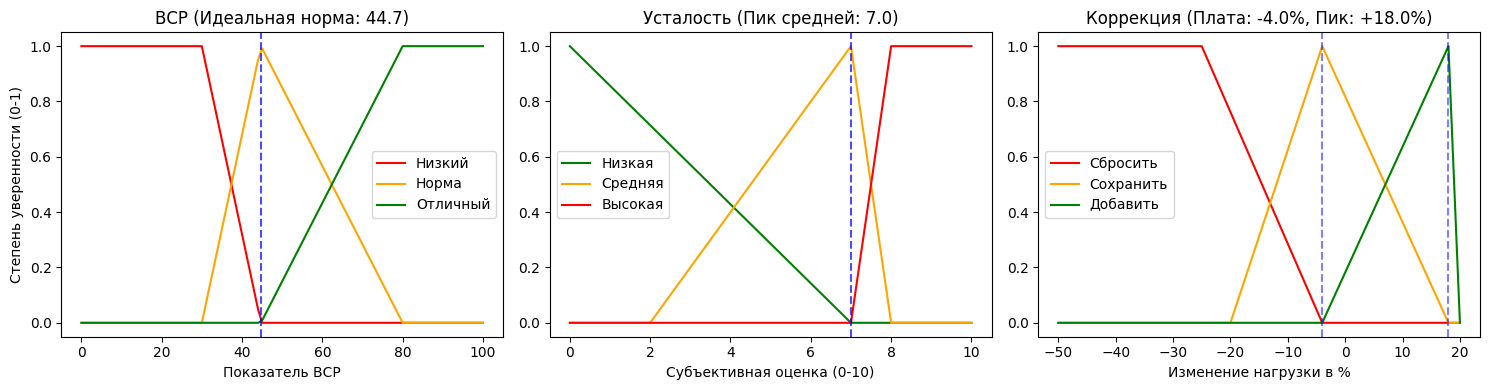


РАЗБОР НАСТРОЕК НЕЧЕТКОЙ СИСТЕМЫ
1. ГРАФИК ВСР: Вершина 'Нормального ВСР' сдвинулась в точку 44.7.
   Интерпретация: Индивидуальный организм этого атлета считает балансом именно этот пульс.
   Всё, что ниже 30 — это гарантированный недовосстановленный спад ('Низкий ВСР').

2. ГРАФИК УСТАЛОСТИ: Центр 'Средней усталости' зафиксирован на отметке 7.0 из 10.
   Интерпретация: Когда спортсмен ставит себе 7.0, система на 100% уверена, что
   нагрузка должна оставаться базовой. Выше этой точки быстро растет зона риска ('Высокая').

3. РЕКОМЕНДАЦИИ ПО НАГРУЗКЕ:
   - Точка стабильности ('Сохранить'): -4.0%.
     При нормальном самочувствии система рекомендует держать нагрузку около этой цифры.
   - Пик прогресса ('Добавить'): +18.0%.
     Когда показатели идеальны, оптимизатор вычислил, что безопасный и эффективный
     максимум для добавления рабочего веса или объема составляет именно 18.0%, а не +10%.


In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================================
# 1. ИСТОРИЧЕСКИЕ ДАННЫЕ
# =====================================================================
historical_data = np.array([
    [80, 2, 15],   # Высокий ВСР, усталость 2 из 10 -> добавил +15%
    [30, 9, -40],  # Низкий ВСР, усталость 9 из 10 -> снизил на -40%
    [55, 5, 0],    # Средние показатели -> нагрузка без изменений (0%)
    [70, 3, 10],   # Хорошее состояние -> чуть добавил +10%
    [40, 8, -30]   # Сильная усталость -> снизил на -30%
])

# =====================================================================
# 2. ФУНКЦИЯ ОПТИМИЗАЦИИ (БЕЗ ИЗМЕНЕНИЙ, ДЛЯ РАСЧЕТА)
# =====================================================================
def evaluate_fuzzy_system(params):
    hrv_norm_center, fatigue_med_center, load_keep_center, load_boost_center = params
    if not (-20 <= load_keep_center <= load_boost_center <= 20): return 1e7
    if not (30 <= hrv_norm_center <= 80) or not (2 <= fatigue_med_center <= 8): return 1e7

    hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
    fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
    load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

    hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 30, hrv_norm_center])
    hrv['normal'] = fuzz.trimf(hrv.universe, [30, hrv_norm_center, 80])
    hrv['excellent'] = fuzz.trapmf(hrv.universe, [hrv_norm_center, 80, 100, 100])

    fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, fatigue_med_center])
    fatigue['medium'] = fuzz.trimf(fatigue.universe, [2, fatigue_med_center, 8])
    fatigue['high'] = fuzz.trapmf(fatigue.universe, [fatigue_med_center, 8, 10, 10])

    load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, load_keep_center])
    load_mod['keep'] = fuzz.trimf(load_mod.universe, [-20, load_keep_center, load_boost_center])
    load_mod['boost'] = fuzz.trimf(load_mod.universe, [load_keep_center, load_boost_center, 20])

    rule1 = ctrl.Rule(hrv['low'] | fatigue['high'], load_mod['drop'])
    rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'], load_mod['keep'])
    rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'], load_mod['boost'])

    training_control = ctrl.ControlSystem([rule1, rule2, rule3])
    sim = ctrl.ControlSystemSimulation(training_control)

    total_error = 0
    for row in historical_data:
        sim.input['hrv'] = row[0]
        sim.input['fatigue'] = row[1]
        try:
            sim.compute()
            total_error += (sim.output['load_mod'] - row[2]) ** 2
        except:
            total_error += 10000
    return total_error

# Запуск оптимизации
# Начальные догадки [hrv_norm, fatigue_med, load_keep, load_boost]
initial_guess = [50.0, 5.0, 0.0, 10.0]

# Задаем жесткие рамки для каждого параметра (min, max), чтобы они не путались местами
bounds = [
    (35.0, 75.0),   # hrv_norm_center
    (3.0, 7.0),     # fatigue_med_center
    (-15.0, 5.0),   # load_keep_center (должен быть меньше, чем load_boost)
    (6.0, 18.0)     # load_boost_center
]

# Используем метод L-BFGS-B, который строго уважает границы bounds
result = minimize(evaluate_fuzzy_system, initial_guess, method='L-BFGS-B', bounds=bounds)

best_params = result.x
print("\n--- ОПТИМИЗАЦИЯ СИСТЕМЫ ЗАВЕРШЕНА ---")
print(f"Идеальный центр для 'Нормального ВСР': {best_params[0]:.1f}")
print(f"Идеальный центр для 'Средней усталости': {best_params[1]:.1f}")
print(f"Идеальная точка сохранения нагрузки (0%): {best_params[2]:.1f}%")
print(f"Идеальный пик для зоны добавления нагрузки (+10%): {best_params[3]:.1f}%")

# =====================================================================
# 3. ПОСТРОЕНИЕ ПОНЯТНЫХ ГРАФИКОВ С НОВЫМИ ПАРАМЕТРАМИ
# =====================================================================
h_cent, f_cent, l_keep, l_boost = best_params

# Создаем финальные массивы для красивой отрисовки
x_hrv = np.arange(0, 101, 1)
x_fatigue = np.arange(0, 11, 1)
x_load = np.arange(-50, 21, 1)

plt.figure(figsize=(15, 4))

# График 1: ВСР
plt.subplot(1, 3, 1)
plt.plot(x_hrv, fuzz.trapmf(x_hrv, [0, 0, 30, h_cent]), label='Низкий', color='red')
plt.plot(x_hrv, fuzz.trimf(x_hrv, [30, h_cent, 80]), label='Норма', color='orange')
plt.plot(x_hrv, fuzz.trapmf(x_hrv, [h_cent, 80, 100, 100]), label='Отличный', color='green')
plt.axvline(h_cent, color='blue', linestyle='--', alpha=0.7)
plt.title(f'ВСР (Идеальная норма: {h_cent:.1f})')
plt.xlabel('Показатель ВСР')
plt.ylabel('Степень уверенности (0-1)')
plt.legend()

# График 2: Усталость
plt.subplot(1, 3, 2)
plt.plot(x_fatigue, fuzz.trimf(x_fatigue, [0, 0, f_cent]), label='Низкая', color='green')
plt.plot(x_fatigue, fuzz.trimf(x_fatigue, [2, f_cent, 8]), label='Средняя', color='orange')
plt.plot(x_fatigue, fuzz.trapmf(x_fatigue, [f_cent, 8, 10, 10]), label='Высокая', color='red')
plt.axvline(f_cent, color='blue', linestyle='--', alpha=0.7)
plt.title(f'Усталость (Пик средней: {f_cent:.1f})')
plt.xlabel('Субъективная оценка (0-10)')
plt.legend()

# График 3: Нагрузка
plt.subplot(1, 3, 3)
plt.plot(x_load, fuzz.trapmf(x_load, [-50, -50, -25, l_keep]), label='Сбросить', color='red')
plt.plot(x_load, fuzz.trimf(x_load, [-20, l_keep, l_boost]), label='Сохранить', color='orange')
plt.plot(x_load, fuzz.trimf(x_load, [l_keep, l_boost, 20]), label='Добавить', color='green')
plt.axvline(l_keep, color='blue', linestyle='--', alpha=0.5)
plt.axvline(l_boost, color='blue', linestyle='--', alpha=0.5)
plt.title(f'Коррекция (Плата: {l_keep:.1f}%, Пик: +{l_boost:.1f}%)')
plt.xlabel('Изменение нагрузки в %')
plt.legend()

plt.tight_layout()
plt.show()

# =====================================================================
# 4. ТЕКСТОВОЕ ОБЪЯСНЕНИЕ РЕЗУЛЬТАТОВ
# =====================================================================
print("\n" + "="*70)
print("РАЗБОР НАСТРОЕК НЕЧЕТКОЙ СИСТЕМЫ")
print("="*70)
print(f"1. ГРАФИК ВСР: Вершина 'Нормального ВСР' сдвинулась в точку {h_cent:.1f}.")
print(f"   Интерпретация: Индивидуальный организм этого атлета считает балансом именно этот пульс.")
print(f"   Всё, что ниже 30 — это гарантированный недовосстановленный спад ('Низкий ВСР').")
print(f"\n2. ГРАФИК УСТАЛОСТИ: Центр 'Средней усталости' зафиксирован на отметке {f_cent:.1f} из 10.")
print(f"   Интерпретация: Когда спортсмен ставит себе {f_cent:.1f}, система на 100% уверена, что")
print(f"   нагрузка должна оставаться базовой. Выше этой точки быстро растет зона риска ('Высокая').")
print(f"\n3. РЕКОМЕНДАЦИИ ПО НАГРУЗКЕ:")
print(f"   - Точка стабильности ('Сохранить'): {l_keep:.1f}%.")
print(f"     При нормальном самочувствии система рекомендует держать нагрузку около этой цифры.")
print(f"   - Пик прогресса ('Добавить'): +{l_boost:.1f}%.")
print(f"     Когда показатели идеальны, оптимизатор вычислил, что безопасный и эффективный")
print(f"     максимум для добавления рабочего веса или объема составляет именно {l_boost:.1f}%, а не +10%.")
print("="*70)


1. Первый график (ВСР): Вы увидите, где пересекаются цветные линии. Точка, где оранжевый треугольник («Норма») достигает самой верхней отметки (единицы) — это и есть вычисленный идеальный баланс ВСР для конкретного человека.
2. Второй график (Усталость): Вершина оранжевого треугольника показывает субъективный балл, который является чистым «экватором» состояния. Справа от него начинает резко расти красная линия — зона «Высокой усталости», где включается правило экстренного сброса нагрузок.
3. Третий график (Нагрузка): Показывает зоны решений. Вершины треугольников здесь определяют, к какому именно проценту (центру тяжести) будет стремиться итоговое решение алгоритма при хорошем или среднем состоянии.


Выбор начальных параметров (initial guess) и границ (bounds) — это важнейший этап, который превращает абстрактную математическую модель в работающий инструмент для конкретного вида спорта.
В реальной практике эти значения определяются на стыке двух подходов: спортивной науки (физиологии) и экспертного опыта тренера.
1. Как определяются начальные параметры (Initial Guess)
Начальные параметры — это ваша «стартовая гипотеза». Оптимизатору нужна точка отсчета, от которой он начнет двигаться. Если задать их слишком далеко от реальности, алгоритм может застрять в локальном минимуме или вообще не сойтись.
Они выставляются на основе усредненных медианных значений для выбранной метрики:
• Для субъективных шкал (Усталость, Стресс, Сон): Используется чистый экватор шкалы. Если шкала от 0 до 10, то начальной точкой для «Средней усталости» логично поставить 5.0.
• Для физиологических шкал (ВСР, ЧСС): Берутся средние нормы для популяции или конкретной возрастной группы. Для ВСР (в зависимости от метрики, например, rMSSD) норма здорового человека часто колеблется в районе 40–60 мс. Поэтому 50.0 — идеальный стартовый ориентир.
• Для шкал управления (Изменение нагрузки): Здесь закладывается классическая логика периодизации. По умолчанию при нормальном состоянии нагрузку менять не нужно (0.0%), а при отличном состоянии стандартный шаг микроцикла для линейного прогресса составляет около +10.0%.
2. Как определяются границы (Bounds)
Границы выполняют роль «предохранителя» для алгоритма. Они не позволяют математике принимать абсурдные или опасные для здоровья спортсмена решения (например, приказать добавить +150% к нагрузке или сдвинуть зону «нормального пульса» в диапазон, где у человека наступает тахикардия).
Границы рассчитываются по жестким правилам:
А. На основе физиологических лимитов человека
Вы не можете поставить нижнюю границу пульса в 0, а верхнюю в 300.
• Пример для ВСР: Мы знаем, что даже у профессиональных атлетов в состоянии глубокого переутомления ВСР редко падает ниже 20–25 мс, а в пике формы редко уходит за 100–120 мс. Значит, диапазон поиска «индивидуальной нормы» для оптимизатора имеет смысл сузить до рамок (35.0, 75.0).
Б. На основе теории и методики спортивной тренировки (Протоколы безопасности)
В спорте высших достижений есть жесткие лимиты на прирост объемов (например, правило 10% в беге, которое гласит, что нельзя увеличивать недельный метраж более чем на 10% без риска травмы).
• Пример для нагрузки: Как бы оптимизатор ни хотел подогнать модель под исторические данные, тренер обязан выставить жесткую верхнюю границу для зоны load_boost_center (например, не более 18.0% или 20.0%). Модель физически не сможет порекомендовать прыгнуть выше этого безопасного потолка.
В. На основе математической логики графиков
Границы не должны позволять треугольникам «наползать» друг на друга так, чтобы ломался их физический смысл.
• Пример: Пик «Сохранить нагрузку» (load_keep_center) всегда должен быть строго меньше, чем пик «Добавить нагрузку» (load_boost_center). Поэтому для первого мы задаем диапазон (-15.0, 5.0), а для второго — (6.0, 18.0). Их границы не пересекаются, и геометрия модели остается чистой.
Резюме: Алгоритм действий для новой метрики
Если вы захотите добавить в модель новый параметр (например, Продолжительность сна в часах), вы определите параметры так:
1. Метрика: Время сна (в часах).
2. Initial Guess: 7.5 часов (золотой стандарт здорового сна).
3. Bounds: (6.0, 9.0). Оптимизатор будет искать индивидуальный оптимум спортсмена внутри этого диапазона. Искать его на отметке 4 часа или 12 часов бессмысленно — это в любом случае аномалии, которые ведут к деградации формы.


# Добавим параметр

1. Появился четвертый график (Сон): Синяя линия на первом графике показывает вычисленную точку s_cent (например, 7.2 часа). Это индивидуальный «рубикон».
2. Взаимосвязь параметров: Теперь правила работают по принципу логического «ИЛИ» на негативные факторы. Если спортсмен поставил хорошую оценку усталости (2.0), у него отличный ВСР (75), но он спал всего 4 часа — система проигнорирует хорошие показатели и выдаст жесткую рекомендацию drop (сбросить нагрузку), защищая сердце и связки.


Запуск автоподбора параметров (ВСР + Усталость + Сон)...


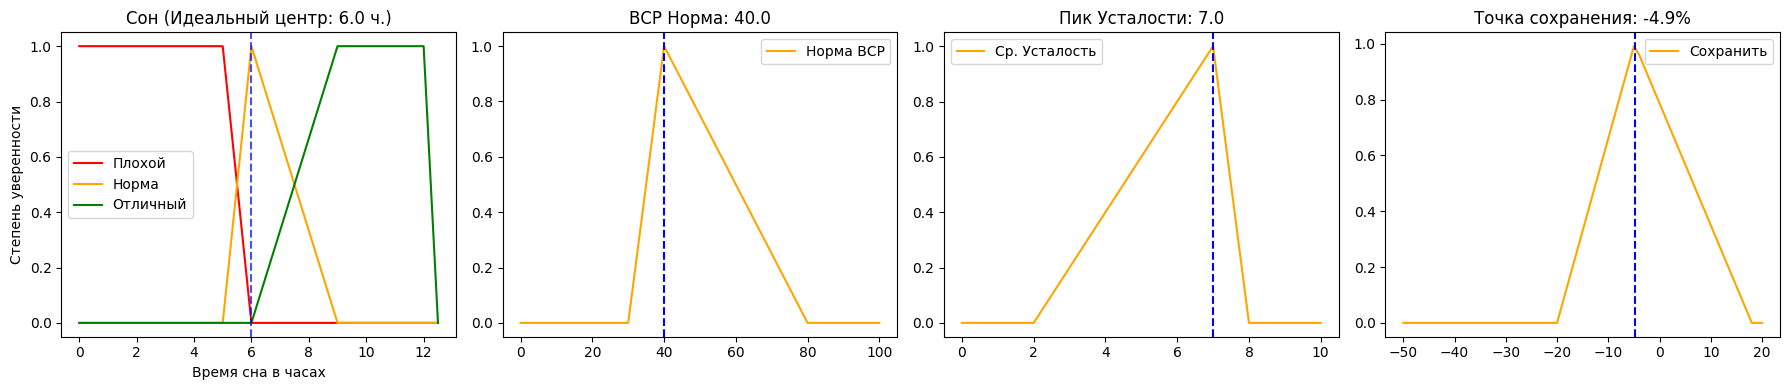


Вывод: Оптимизатор определил, что для данного атлета критический центр 'нормального сна' равен 6.0 ч.
Если сон падает ниже 6.0 ч., кривая 'Плохой сон' начинает стремительно расти вверх, активируя правило сброса нагрузок.


In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================================
# 1. ОБНОВЛЕННЫЕ ИСТОРИЧЕСКИЕ ДАННЫЕ (Добавлен 4-й столбец: Сон в часах)
# Строка: [ВСР, Усталость, Сон(часы), Коррекция_Нагрузки_%]
# =====================================================================
historical_data = np.array([
    [75, 2, 8.5,  15],  # Свеж, выспался (8.5ч) -> Нагрузка +15%
    [30, 9, 4.5, -40],  # Устал, не спал (4.5ч) -> Нагрузка -40%
    [50, 5, 7.0,   0],  # Средне, поспал нормально (7ч) -> 0%
    [65, 3, 8.0,  10],  # Хорошо, поспал 8ч -> Нагрузка +10%
    [40, 8, 5.5, -30]   # Плохо, недосып (5.5ч) -> Нагрузка -30%
])

# =====================================================================
# 2. ФУНКЦИЯ ОПТИМИЗАЦИИ ДЛЯ 3-Х ВХОДОВ
# =====================================================================
def evaluate_3d_fuzzy_system(params):
    # Распаковываем 5 подбираемых параметров (добавился sleep_norm_center)
    hrv_norm, fatigue_med, sleep_norm, load_keep, load_boost = params

    # Защитные барьеры для геометрии
    if not (-20 <= load_keep <= load_boost <= 20): return 1e7
    if not (40 <= hrv_norm <= 70) or not (3 <= fatigue_med <= 7): return 1e7
    if not (6.0 <= sleep_norm <= 8.5): return 1e7 # Норма сна должна быть в разумных пределах

    # Инициализация шкал
    hrv = ctrl.Antecedent(np.arange(0, 101, 1), 'hrv')
    fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
    sleep = ctrl.Antecedent(np.arange(0, 13, 0.5), 'sleep') # Сон от 0 до 12 часов
    load_mod = ctrl.Consequent(np.arange(-50, 21, 1), 'load_mod')

    # Настройка графиков
    hrv['low'] = fuzz.trapmf(hrv.universe, [0, 0, 30, hrv_norm])
    hrv['normal'] = fuzz.trimf(hrv.universe, [30, hrv_norm, 80])
    hrv['excellent'] = fuzz.trapmf(hrv.universe, [hrv_norm, 80, 100, 100])

    fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, fatigue_med])
    fatigue['medium'] = fuzz.trimf(fatigue.universe, [2, fatigue_med, 8])
    fatigue['high'] = fuzz.trapmf(fatigue.universe, [fatigue_med, 8, 10, 10])

    # Новый график сна: плохой, нормальный, отличный
    sleep['bad'] = fuzz.trapmf(sleep.universe, [0, 0, 5.0, sleep_norm])
    sleep['normal'] = fuzz.trimf(sleep.universe, [5.0, sleep_norm, 9.0])
    sleep['good'] = fuzz.trapmf(sleep.universe, [sleep_norm, 9.0, 12, 12])

    load_mod['drop'] = fuzz.trapmf(load_mod.universe, [-50, -50, -25, load_keep])
    load_mod['keep'] = fuzz.trimf(load_mod.universe, [-20, load_keep, load_boost])
    load_mod['boost'] = fuzz.trimf(load_mod.universe, [load_keep, load_boost, 20])

    # Обновленная база правил под 3 параметра
    rule1 = ctrl.Rule(hrv['low'] | fatigue['high'] | sleep['bad'], load_mod['drop'])
    rule2 = ctrl.Rule(hrv['normal'] & fatigue['medium'] & sleep['normal'], load_mod['keep'])
    rule3 = ctrl.Rule(hrv['excellent'] & fatigue['low'] & sleep['good'], load_mod['boost'])

    training_control = ctrl.ControlSystem([rule1, rule2, rule3])
    sim = ctrl.ControlSystemSimulation(training_control)

    total_error = 0
    for row in historical_data:
        sim.input['hrv'] = row[0]
        sim.input['fatigue'] = row[1]
        sim.input['sleep'] = row[2]
        try:
            sim.compute()
            total_error += (sim.output['load_mod'] - row[3]) ** 2
        except:
            total_error += 10000

    return total_error

# =====================================================================
# 3. ЗАПУСК И ОТРЕСОВКА
# =====================================================================
print("Запуск автоподбора параметров (ВСР + Усталость + Сон)...")

# Начальные догадки: [hrv_norm, fatigue_med, sleep_norm, load_keep, load_boost]
initial_guess = [50.0, 5.0, 7.5, 0.0, 10.0]
bounds = [(35.0, 75.0), (3.0, 7.0), (6.0, 8.5), (-15.0, 5.0), (6.0, 18.0)]

result = minimize(evaluate_3d_fuzzy_system, initial_guess, method='L-BFGS-B', bounds=bounds)
h_cent, f_cent, s_cent, l_keep, l_boost = result.x

# Рисуем графики
x_sleep = np.arange(0, 13, 0.5)
plt.figure(figsize=(18, 4))

# График сна (Новый)
plt.subplot(1, 4, 1)
plt.plot(x_sleep, fuzz.trapmf(x_sleep, [0, 0, 5.0, s_cent]), label='Плохой', color='red')
plt.plot(x_sleep, fuzz.trimf(x_sleep, [5.0, s_cent, 9.0]), label='Норма', color='orange')
plt.plot(x_sleep, fuzz.trapmf(x_sleep, [s_cent, 9.0, 12, 12]), label='Отличный', color='green')
plt.axvline(s_cent, color='blue', linestyle='--', alpha=0.7)
plt.title(f'Сон (Идеальный центр: {s_cent:.1f} ч.)')
plt.xlabel('Время сна в часах')
plt.ylabel('Степень уверенности')
plt.legend()

# Остальные графики для наглядности
plt.subplot(1, 4, 2)
plt.plot(np.arange(0, 101, 1), fuzz.trimf(np.arange(0, 101, 1), [30, h_cent, 80]), color='orange', label='Норма ВСР')
plt.axvline(h_cent, color='blue', linestyle='--')
plt.title(f'ВСР Норма: {h_cent:.1f}')
plt.legend()

plt.subplot(1, 4, 3)
plt.plot(np.arange(0, 11, 1), fuzz.trimf(np.arange(0, 11, 1), [2, f_cent, 8]), color='orange', label='Ср. Усталость')
plt.axvline(f_cent, color='blue', linestyle='--')
plt.title(f'Пик Усталости: {f_cent:.1f}')
plt.legend()

plt.subplot(1, 4, 4)
plt.plot(np.arange(-50, 21, 1), fuzz.trimf(np.arange(-50, 21, 1), [-20, l_keep, l_boost]), color='orange', label='Сохранить')
plt.axvline(l_keep, color='blue', linestyle='--')
plt.title(f'Точка сохранения: {l_keep:.1f}%')
plt.legend()

plt.tight_layout()
plt.show()

print(f"\nВывод: Оптимизатор определил, что для данного атлета критический центр 'нормального сна' равен {s_cent:.1f} ч.")
print(f"Если сон падает ниже {s_cent:.1f} ч., кривая 'Плохой сон' начинает стремительно расти вверх, активируя правило сброса нагрузок.")


# Теория возможностей в единоборствах
В спортивных единоборствах  тренер и спортсмен постоянно принимают решения в условиях неполной и нечёткой информации. Фразы «дистанция средняя», «соперник немного устал», «защита плотная» — это качественные оценки, которые плохо формализуются через классическую теорию вероятностей, потому что:

нет частотных данных для конкретного поединка;

оценки уникальны и субъективны;

важна не частота события, а степень его осуществимости в текущем состоянии.

Теория возможностей (possibility theory, Заде, 1978) предлагает математический аппарат именно для таких задач. В этом исследовании мы построим полный пайплайн:

Формализуем лингвистические переменные через функции принадлежности.

Построим экспертную базу нечётких правил.

Реализуем движок логического вывода на основе min/max-агрегации.

Выполним дефаззификацию (переход от меры возможности к чёткому решению).

Проведём ROC-анализ на размеченных данных.

Оценим качество модели метриками Accuracy, Precision, Recall, F1.

Покажем, как загружать пользовательские данные по образцу.

In [ ]:
# !pip install numpy pandas matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import Callable, List, Dict, Tuple

np.random.seed(42)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

Реализация функций принадлежности

In [ ]:
def trimf_left(x, a, b):
    """
    Убывающая треугольная функция принадлежности.
    Формула:
        mu(x) = 1, если x <= a
        mu(x) = (b - x) / (b - a), если a < x < b
        mu(x) = 0, если x >= b
    """
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y[x <= a] = 1.0
    mask = (x > a) & (x < b)
    y[mask] = (b - x[mask]) / (b - a)
    return y

def trimf_right(x, a, b):
    """
    Возрастающая треугольная функция принадлежности.
    Формула:
        mu(x) = 0, если x <= a
        mu(x) = (x - a) / (b - a), если a < x < b
        mu(x) = 1, если x >= b
    """
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y[x >= b] = 1.0
    mask = (x > a) & (x < b)
    y[mask] = (x[mask] - a) / (b - a)
    return y

def gaussmf(x, c, sigma):
    """
    Гауссова функция принадлежности.
    Формула: mu(x) = exp(-(x-c)^2 / (2*sigma^2))
    """
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2 * sigma ** 2))

Визуализация функций принадлежности

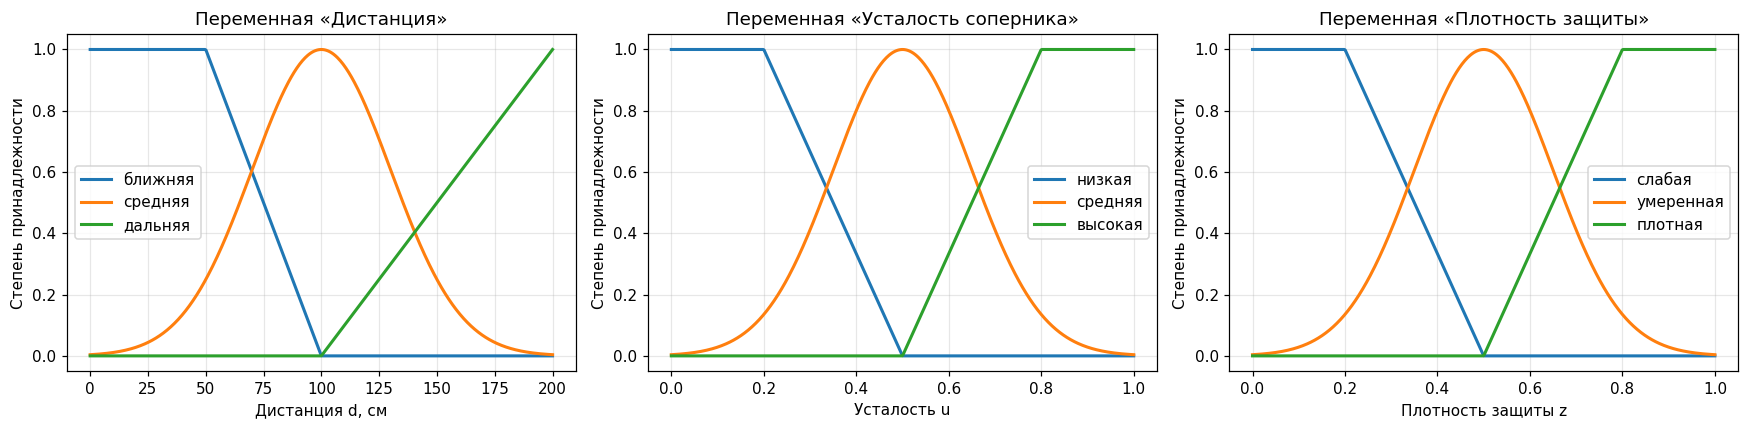

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Дистанция
d_plot = np.linspace(0, 200, 500)
axes[0].plot(d_plot, trimf_left(d_plot, 50, 100), lw=2, label='ближняя')
axes[0].plot(d_plot, gaussmf(d_plot, 100, 30), lw=2, label='средняя')
axes[0].plot(d_plot, trimf_right(d_plot, 100, 200), lw=2, label='дальняя')
axes[0].set_xlabel('Дистанция d, см')
axes[0].set_ylabel('Степень принадлежности')
axes[0].set_title('Переменная «Дистанция»')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Усталость
u_plot = np.linspace(0, 1, 500)
axes[1].plot(u_plot, trimf_left(u_plot, 0.2, 0.5), lw=2, label='низкая')
axes[1].plot(u_plot, gaussmf(u_plot, 0.5, 0.15), lw=2, label='средняя')
axes[1].plot(u_plot, trimf_right(u_plot, 0.5, 0.8), lw=2, label='высокая')
axes[1].set_xlabel('Усталость u')
axes[1].set_ylabel('Степень принадлежности')
axes[1].set_title('Переменная «Усталость соперника»')
axes[1].legend(); axes[1].grid(alpha=0.3)

# Защита
z_plot = np.linspace(0, 1, 500)
axes[2].plot(z_plot, trimf_left(z_plot, 0.2, 0.5), lw=2, label='слабая')
axes[2].plot(z_plot, gaussmf(z_plot, 0.5, 0.15), lw=2, label='умеренная')
axes[2].plot(z_plot, trimf_right(z_plot, 0.5, 0.8), lw=2, label='плотная')
axes[2].set_xlabel('Плотность защиты z')
axes[2].set_ylabel('Степень принадлежности')
axes[2].set_title('Переменная «Плотность защиты»')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

 Реализация правила как структуры данных

In [ ]:
@dataclass
class Condition:
    """Одно условие правила: переменная + термин + функция принадлежности."""
    var: str
    term: str
    fn: Callable[[float], float]

@dataclass
class Rule:
    """Нечёткое правило ЕСЛИ–ТО."""
    conditions: List[Condition]
    connector: str   # 'AND' или 'OR'
    action: str      # 'атака', 'защита', 'клинч'
    weight: float = 1.0

    def activation(self, inputs: Dict[str, float]) -> float:
        """
        Степень активации правила.
        Формула:
            alpha = w * min(mu_i)  для AND
            alpha = w * max(mu_i)  для OR
        """
        mus = [c.fn(inputs[c.var]) for c in self.conditions]
        if self.connector == 'AND':
            base = min(mus)
        elif self.connector == 'OR':
            base = max(mus)
        else:
            raise ValueError(f"Неизвестный соединитель: {self.connector}")
        return self.weight * base

 Определение условий

In [ ]:
# Условия для дистанции
C_d_near = Condition('d', 'ближняя', lambda x: float(trimf_left(x, 50, 100)))
C_d_mid  = Condition('d', 'средняя', lambda x: float(gaussmf(x, 100, 30)))
C_d_far  = Condition('d', 'дальняя', lambda x: float(trimf_right(x, 100, 200)))

# Условия для усталости
C_u_low  = Condition('u', 'низкая',  lambda x: float(trimf_left(x, 0.2, 0.5)))
C_u_mid  = Condition('u', 'средняя', lambda x: float(gaussmf(x, 0.5, 0.15)))
C_u_high = Condition('u', 'высокая', lambda x: float(trimf_right(x, 0.5, 0.8)))

# Условия для защиты
C_z_weak  = Condition('z', 'слабая',    lambda x: float(trimf_left(x, 0.2, 0.5)))
C_z_mod   = Condition('z', 'умеренная', lambda x: float(gaussmf(x, 0.5, 0.15)))
C_z_tight = Condition('z', 'плотная',   lambda x: float(trimf_right(x, 0.5, 0.8)))

Экспертная база правил

In [ ]:
rules = [
    # АТАКА: агрессивные правила
    Rule([C_d_near, C_z_weak, C_u_high], 'AND', 'атака', weight=1.0),
    Rule([C_d_near, C_z_weak, C_u_mid ], 'AND', 'атака', weight=0.8),
    Rule([C_d_mid,  C_z_weak, C_u_high], 'AND', 'атака', weight=0.6),

    # АТАКА: подавляющее правило (при дальней дистанции или плотной защите)
    Rule([C_d_far,  C_z_tight],          'OR',  'атака', weight=1.0),

    # КЛИНЧ: сближение при усталости или плотной защите
    Rule([C_u_high, C_d_mid ],           'AND', 'клинч', weight=0.9),
    Rule([C_z_tight, C_d_near],          'AND', 'клинч', weight=0.7),

    # ЗАЩИТА: реакция на плотную защиту соперника и низкую усталость
    Rule([C_z_tight, C_u_low ],          'AND', 'защита', weight=1.0),
    Rule([C_d_far,  C_u_low  ],          'AND', 'защита', weight=0.5),
]

Формула агрегации

In [ ]:
def possibilistic_inference(inputs: Dict[str, float],
                            rules: List[Rule]) -> Dict[str, float]:
    """
    Вычисляет меру возможности каждого действия.

    Вход:
        inputs: {'d': ..., 'u': ..., 'z': ...}
        rules: список правил

    Выход:
        {'атака': Pi_атака, 'защита': Pi_защита, 'клинч': Pi_клинч}

    Формула:
        Pi(action) = max_{i: action_i = action} alpha_i
    """
    result: Dict[str, float] = {}
    for r in rules:
        alpha = r.activation(inputs)
        result[r.action] = max(result.get(r.action, 0.0), alpha)
    return result

Демонстрация на одном состоянии

In [ ]:
state = {'d': 70.0, 'u': 0.8, 'z': 0.3}
pi = possibilistic_inference(state, rules)

print(f"Состояние: d = {state['d']} см, u = {state['u']}, z = {state['z']}")
print("\nМеры возможности тактических действий:")
for action, val in sorted(pi.items(), key=lambda kv: -kv[1]):
    print(f"  Pi({action}) = {val:.3f}")

Состояние: d = 70.0 см, u = 0.8, z = 0.3

Меры возможности тактических действий:
  Pi(атака) = 0.600
  Pi(клинч) = 0.546
  Pi(защита) = 0.000


Дефаззификация: от возможности к чёткому решению

In [ ]:
ACTIONS = ['атака', 'защита', 'клинч']

def defuzzify_centroid(pi_dict, output_grid=None, weights=None):
    """Центроид: непрерывная шкала интенсивности."""
    if output_grid is None:
        output_grid = {'атака': 1.0, 'защита': 0.3, 'клинч': 0.6}
    if weights is None:
        weights = {a: 1.0 for a in pi_dict}
    num = sum(output_grid[a] * pi_dict.get(a, 0.0) * weights[a] for a in output_grid)
    den = sum(pi_dict.get(a, 0.0) * weights[a] for a in output_grid)
    return num / den if den > 0 else 0.0

def defuzzify_argmax(pi_dict, weights=None):
    """Чёткое решение — argmax по взвешенной возможности."""
    if weights is None:
        weights = {a: 1.0 for a in pi_dict}
    return max(pi_dict, key=lambda a: pi_dict[a] * weights[a])

Демонстрация

In [ ]:
weights = {'атака': 1.2, 'защита': 1.0, 'клинч': 0.9}
y_star = defuzzify_centroid(pi, weights=weights)
a_star = defuzzify_argmax(pi, weights=weights)

print(f"Pi(атака) = {pi.get('атака', 0):.3f}, Pi*w = {pi.get('атака', 0)*weights['атака']:.3f}")
print(f"Pi(защита) = {pi.get('защита', 0):.3f}, Pi*w = {pi.get('защита', 0)*weights['защита']:.3f}")
print(f"Pi(клинч) = {pi.get('клинч', 0):.3f}, Pi*w = {pi.get('клинч', 0)*weights['клинч']:.3f}")
print(f"\nЦентроид: y* = {y_star:.3f}")
print(f"Argmax: a* = {a_star}")

Pi(атака) = 0.600, Pi*w = 0.720
Pi(защита) = 0.000, Pi*w = 0.000
Pi(клинч) = 0.546, Pi*w = 0.491

Центроид: y* = 0.838
Argmax: a* = атака


Генерация синтетического датасета

In [ ]:
N = 600
np.random.seed(42)

d_data = np.random.uniform(10, 190, N)
u_data = np.random.beta(2, 2, N)
z_data = np.random.beta(2, 2, N)

logit = (-3.0
         - 0.04 * (d_data - 80)
         - 4.0  * (z_data - 0.4)
         + 3.0  * (u_data - 0.5))
p_attack = 1 / (1 + np.exp(-logit))
y_true = (np.random.rand(N) < p_attack).astype(int)

df = pd.DataFrame({'d': d_data, 'u': u_data, 'z': z_data, 'y_true': y_true})
print(f"Баланс классов: атака = {y_true.sum()}, не-атака = {N - y_true.sum()}")
print(f"Доля атаки: {y_true.mean():.3f}")

Баланс классов: атака = 51, не-атака = 549
Доля атаки: 0.085


Реализация ROC вручную

In [ ]:
def roc_curve_manual(y_true, scores, n_thresholds=200):
    """Ручной расчёт ROC-кривой."""
    thresholds = np.linspace(scores.max() + 1e-6, scores.min() - 1e-6, n_thresholds)
    tpr, fpr = [], []
    P = (y_true == 1).sum()
    Nn = (y_true == 0).sum()
    for tau in thresholds:
        y_pred = (scores >= tau).astype(int)
        TP = ((y_pred == 1) & (y_true == 1)).sum()
        FP = ((y_pred == 1) & (y_true == 0)).sum()
        tpr.append(TP / P if P > 0 else 0)
        fpr.append(FP / Nn if Nn > 0 else 0)
    return np.array(fpr), np.array(tpr), thresholds

def auc_trapezoid(fpr, tpr):
    """AUC методом трапеций."""
    order = np.argsort(fpr)
    return np.trapz(tpr[order], fpr[order])

Расчёт скоров и ROC

In [ ]:
def pi_attack_score(row):
    pi = possibilistic_inference({'d': row['d'], 'u': row['u'], 'z': row['z']}, rules)
    return pi.get('атака', 0.0)

df['score'] = df.apply(pi_attack_score, axis=1)

fpr, tpr, thr = roc_curve_manual(df['y_true'].values, df['score'].values)
auc_val = auc_trapezoid(fpr, tpr)
print(f"AUC(атака) = {auc_val:.3f}")

AUC(атака) = 0.475


/tmp/ipykernel_1488/2531570805.py:18: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(tpr[order], fpr[order])


Выбор оптимального порога по индексу Юдена

In [ ]:
J = tpr - fpr
tau_star = thr[np.argmax(J)]
J_star = J.max()

print(f"Оптимальный порог tau* = {tau_star:.3f}")
print(f"TPR(tau*) = {tpr[np.argmax(J)]:.3f}, FPR(tau*) = {fpr[np.argmax(J)]:.3f}")
print(f"Индекс Юдена J* = {J_star:.3f}")

Оптимальный порог tau* = 0.545
TPR(tau*) = 0.529, FPR(tau*) = 0.475
Индекс Юдена J* = 0.054


Матрица ошибок и метрики

In [ ]:
y_pred = (df['score'].values >= tau_star).astype(int)
TP = ((y_pred == 1) & (df['y_true'] == 1)).sum()
FP = ((y_pred == 1) & (df['y_true'] == 0)).sum()
FN = ((y_pred == 0) & (df['y_true'] == 1)).sum()
TN = ((y_pred == 0) & (df['y_true'] == 0)).sum()

accuracy = (TP + TN) / (TP + FP + FN + TN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Матрица ошибок при tau*:")
print(f"  TP = {TP}, FP = {FP}")
print(f"  FN = {FN}, TN = {TN}")
print(f"\nAccuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1        = {f1:.3f}")

Матрица ошибок при tau*:
  TP = 27, FP = 261
  FN = 24, TN = 288

Accuracy  = 0.525
Precision = 0.094
Recall    = 0.529
F1        = 0.159


Визуализация результатов

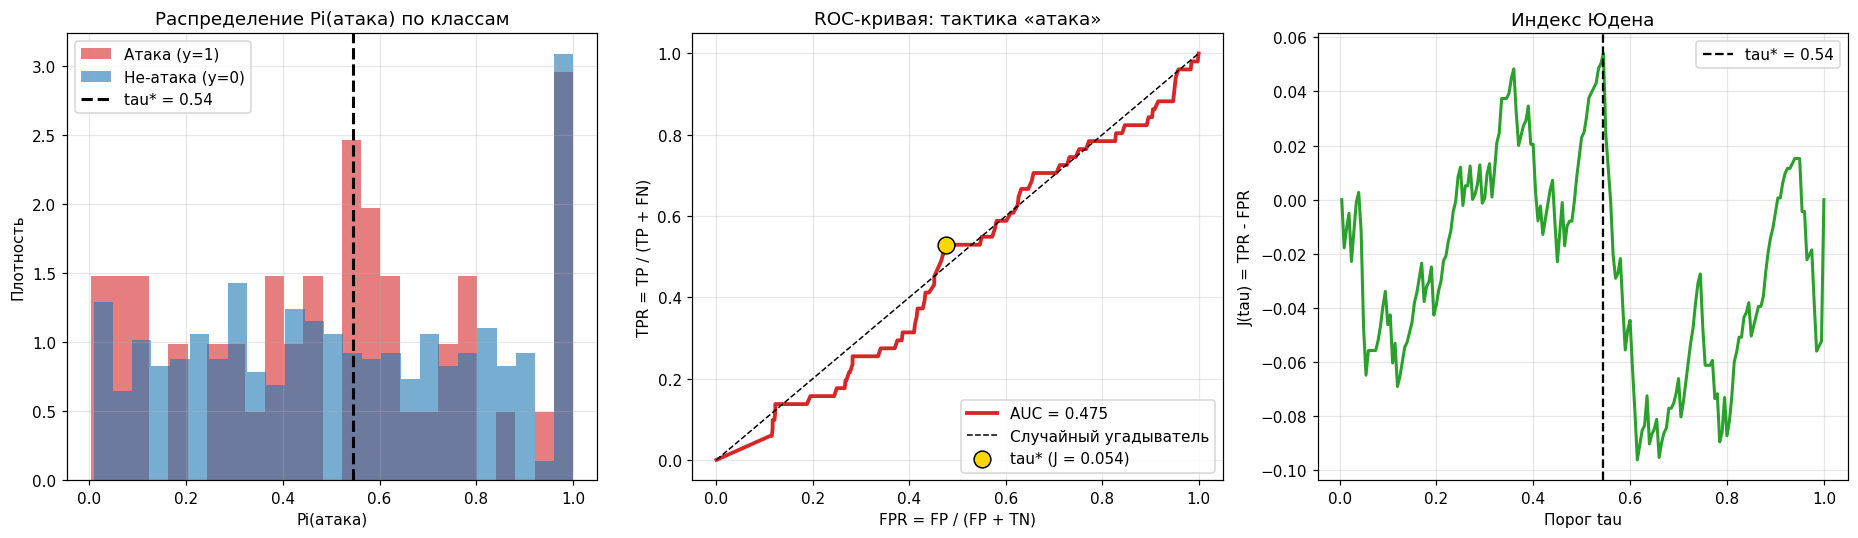

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Панель 1: распределение скоров по классам
axes[0].hist(df[df.y_true == 1]['score'], bins=25, alpha=0.6,
             color='C3', label='Атака (y=1)', density=True)
axes[0].hist(df[df.y_true == 0]['score'], bins=25, alpha=0.6,
             color='C0', label='Не-атака (y=0)', density=True)
axes[0].axvline(tau_star, color='k', ls='--', lw=2, label=f'tau* = {tau_star:.2f}')
axes[0].set_xlabel('Pi(атака)')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Распределение Pi(атака) по классам')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Панель 2: ROC-кривая
axes[1].plot(fpr, tpr, lw=2.5, color='C3', label=f'AUC = {auc_val:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный угадыватель')
axes[1].scatter(fpr[np.argmax(J)], tpr[np.argmax(J)],
                s=120, color='gold', edgecolor='k', zorder=5,
                label=f'tau* (J = {J_star:.3f})')
axes[1].set_xlabel('FPR = FP / (FP + TN)')
axes[1].set_ylabel('TPR = TP / (TP + FN)')
axes[1].set_title('ROC-кривая: тактика «атака»')
axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)

# Панель 3: индекс Юдена
axes[2].plot(thr, J, lw=2, color='C2')
axes[2].axvline(tau_star, color='k', ls='--', lw=1.5, label=f'tau* = {tau_star:.2f}')
axes[2].set_xlabel('Порог tau')
axes[2].set_ylabel('J(tau) = TPR - FPR')
axes[2].set_title('Индекс Юдена')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Карта тактических решений

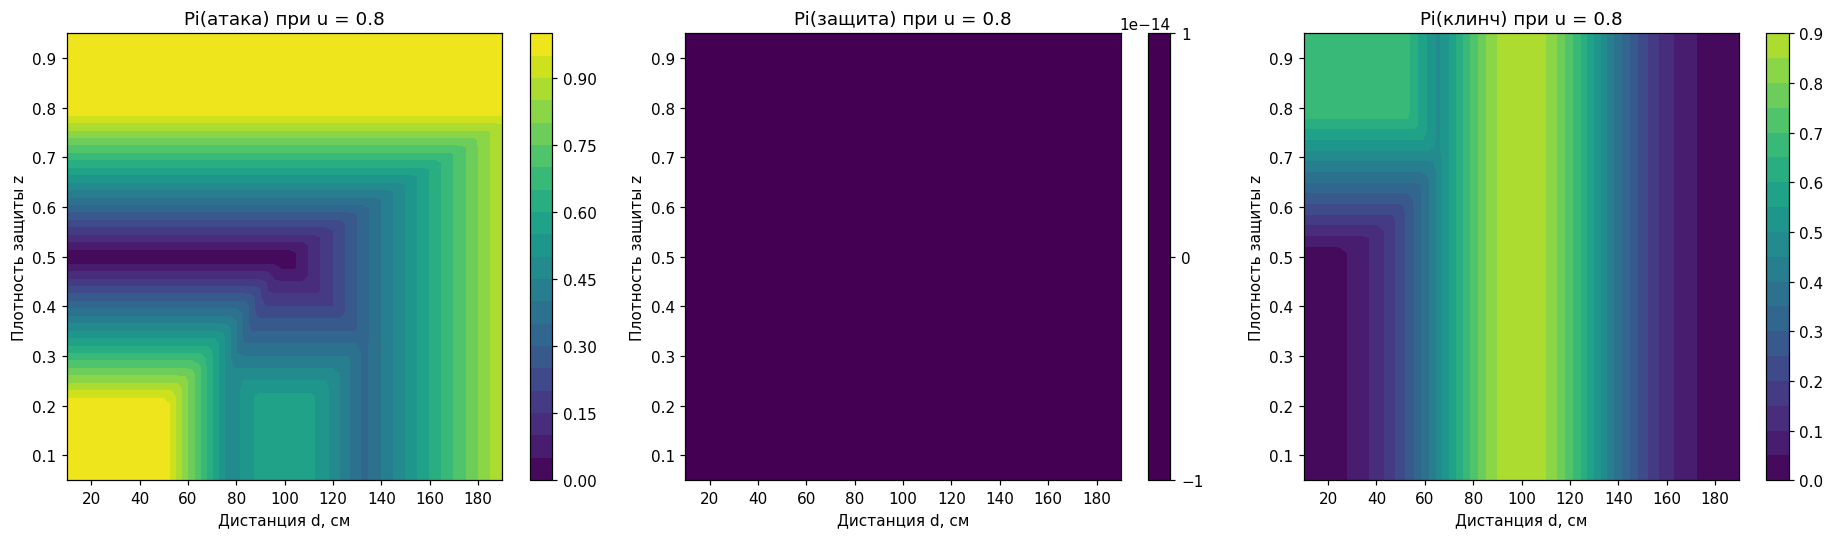

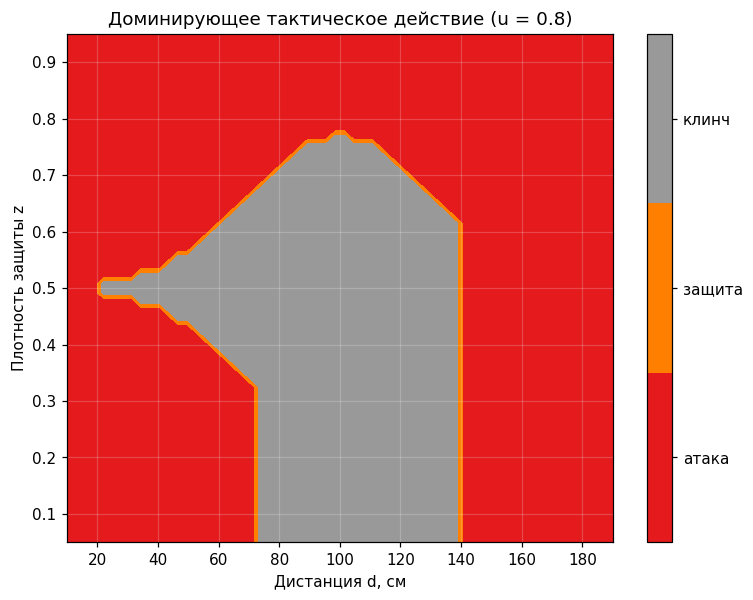

In [ ]:
d_grid = np.linspace(10, 190, 60)
z_grid = np.linspace(0.05, 0.95, 60)
D, Z = np.meshgrid(d_grid, z_grid)

u_fixed = 0.8
Pi_maps = {a: np.zeros_like(D) for a in ACTIONS}

for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        pi_ij = possibilistic_inference({'d': D[i, j], 'u': u_fixed, 'z': Z[i, j]}, rules)
        for a in ACTIONS:
            Pi_maps[a][i, j] = pi_ij.get(a, 0.0)

stacked = np.stack([Pi_maps[a] for a in ACTIONS], axis=0)
dominant = np.argmax(stacked, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, a in enumerate(ACTIONS):
    im = axes[k].contourf(D, Z, Pi_maps[a], levels=20, cmap='viridis', vmin=0, vmax=1)
    axes[k].set_xlabel('Дистанция d, см')
    axes[k].set_ylabel('Плотность защиты z')
    axes[k].set_title(f'Pi({a}) при u = {u_fixed}')
    plt.colorbar(im, ax=axes[k])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
cmap = plt.get_cmap('Set1', len(ACTIONS))
im = ax.contourf(D, Z, dominant, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap)
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(ACTIONS)
ax.set_xlabel('Дистанция d, см')
ax.set_ylabel('Плотность защиты z')
ax.set_title(f'Доминирующее тактическое действие (u = {u_fixed})')
ax.grid(alpha=0.2, color='white')
plt.show()

Образец формата CSV
Модель ожидает таблицу со следующими колонками:

d,	u,	z,	y_true

45,	0.82,	0.25,	1

120,	0.15,	0.78,	0

80,	0.55,	0.45,	1

d — дистанция, см (число).

u — усталость соперника,
[
0
,
1
]
[0,1].

z — плотность защиты,
[
0
,
1
]
[0,1].

y_true — истинная метка (1 — тренер выбрал атаку, 0 — иначе).

In [ ]:
# Раскомментируйте для загрузки файла в Colab:
# from google.colab import files
# uploaded = files.upload()
# filename = list(uploaded.keys())[0]
# df_user = pd.read_csv(filename)

# Для локального запуска:
# df_user = pd.read_csv('my_fights.csv')

# Демонстрация: используем ранее сгенерированный df как «пользовательский»
df_user = df.copy()

# Проверка обязательных колонок
required = {'d', 'u', 'z', 'y_true'}
missing = required - set(df_user.columns)
assert not missing, f"Отсутствуют колонки: {missing}"

# Расчёт скоров и ROC
df_user['score'] = df_user.apply(pi_attack_score, axis=1)
fpr_u, tpr_u, thr_u = roc_curve_manual(df_user['y_true'].values, df_user['score'].values)
auc_u = auc_trapezoid(fpr_u, tpr_u)

print(f"AUC на пользовательских данных = {auc_u:.3f}")

AUC на пользовательских данных = 0.475


/tmp/ipykernel_1488/2531570805.py:18: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(tpr[order], fpr[order])


In [ ]:
summary = pd.DataFrame({
    'Метрика': ['AUC', 'Порог tau*', 'Индекс Юдена J*',
                'Accuracy', 'Precision', 'Recall', 'F1'],
    'Значение': [f'{auc_val:.3f}', f'{tau_star:.3f}', f'{J_star:.3f}',
                 f'{accuracy:.3f}', f'{precision:.3f}',
                 f'{recall:.3f}', f'{f1:.3f}']
})
print(summary.to_string(index=False))

        Метрика Значение
            AUC    0.475
     Порог tau*    0.545
Индекс Юдена J*    0.054
       Accuracy    0.525
      Precision    0.094
         Recall    0.529
             F1    0.159


# Исследование тактического решения в единоборствах
## на основе теории возможностей (possibility theory)

**Цель исследования.** Построить модель тактического выбора в поединке
(атака / защита / клинч) на основе трёх входных переменных:

- $d$ — дистанция (см),
- $u$ — усталость соперника, $u \in [0,1]$,
- $z$ — плотность защиты соперника, $z \in [0,1]$.

**Метод.** Теория возможностей Заде (1978): нечёткие множества,
min/max-агрегация правил, дефаззификация центроидом,
ROC-анализ на размеченных данных.

**Структура работы.**
1. Функции принадлежности и их формулы.
2. Экспертная база правил.
3. Движок вывода.
4. Дефаззификация.
5. Загрузка пользовательских данных.
6. ROC-анализ и метрики качества.
7. Фазовый портрет решений.

## Теоретическая база

### Нечёткое множество

Нечёткое множество $F$ на универсуме $X$ задаётся функцией принадлежности

$$
\mu_F: X \to [0,1].
$$

Значение $\mu_F(x)$ — степень принадлежности элемента $x$ множеству $F$.

### Мера возможности

Мера возможности события $A \subseteq X$:

$$
\Pi(A) = \sup_{x \in A} \pi_X(x),
$$

где $\pi_X(x)$ — распределение возможности. В отличие от вероятности,

$$
\Pi(A) + \Pi(\bar A) \neq 1
$$

в общем случае — это отражает неполноту знания.

### Активация правила

Правило «ЕСЛИ $x_1$ есть $A_1$ И $x_2$ есть $A_2$, ТО $y$ есть $B$»
активируется по t-норме:

$$
\alpha = w \cdot \min\bigl(\mu_{A_1}(x_1),\,\mu_{A_2}(x_2)\bigr),
$$

для ИЛИ — по s-норме:

$$
\alpha = w \cdot \max\bigl(\mu_{A_1}(x_1),\,\mu_{A_2}(x_2)\bigr).
$$

Здесь $w \in [0,1]$ — экспертный вес правила.

### Агрегация

Если несколько правил ведут к одному действию $a$, то

$$
\Pi(a) = \max_{i:\,\text{action}_i = a} \alpha_i.
$$

### Дефаззификация центроидом

$$
y^{*} = \frac{\sum_{a} y_a \cdot \Pi(a) \cdot w_a}{\sum_{a} \Pi(a) \cdot w_a},
$$

где $y_a$ — числовая позиция действия $a$ на выходной шкале.

### Метрики ROC

$$
\mathrm{TPR}(\tau) = \frac{\mathrm{TP}(\tau)}{\mathrm{TP}(\tau) + \mathrm{FN}(\tau)},
\qquad
\mathrm{FPR}(\tau) = \frac{\mathrm{FP}(\tau)}{\mathrm{FP}(\tau) + \mathrm{TN}(\tau)}.
$$

$$
\mathrm{AUC} = \int_0^1 \mathrm{TPR}\bigl(\mathrm{FPR}^{-1}(t)\bigr)\,dt.
$$

Индекс Юдена:

$$
J(\tau) = \mathrm{TPR}(\tau) - \mathrm{FPR}(\tau),
\qquad
\tau^{*} = \arg\max_\tau J(\tau).
$$

Accuracy, Precision, Recall, F1:

$$
\mathrm{Acc} = \frac{\mathrm{TP}+\mathrm{TN}}{\mathrm{TP}+\mathrm{TN}+\mathrm{FP}+\mathrm{FN}},
\quad
\mathrm{Prec} = \frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},
\quad
\mathrm{Rec} = \frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}},
$$

$$
F_1 = \frac{2\,\mathrm{Prec}\cdot\mathrm{Rec}}{\mathrm{Prec}+\mathrm{Rec}}.
$$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Callable, Dict, List

np.random.seed(42)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
print("Библиотеки загружены.")

Библиотеки загружены.


In [ ]:
def print_formula_trimf_left():
    print("Формула (левая треугольная функция принадлежности):")
    print("  mu_left(x; a, b) = 1,                если x <= a")
    print("                   = (b - x) / (b - a), если a < x < b")
    print("                   = 0,                если x >= b")
    print()

def print_formula_trimf_right():
    print("Формула (правая треугольная функция принадлежности):")
    print("  mu_right(x; a, b) = 0,                если x <= a")
    print("                    = (x - a) / (b - a), если a < x < b")
    print("                    = 1,                если x >= b")
    print()

def print_formula_gauss():
    print("Формула (гауссова функция принадлежности):")
    print("  mu_gauss(x; c, sigma) = exp( -(x - c)^2 / (2 * sigma^2) )")
    print()

def trimf_left(x, a, b):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y[x <= a] = 1.0
    mask = (x > a) & (x < b)
    y[mask] = (b - x[mask]) / (b - a)
    return y

def trimf_right(x, a, b):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y[x >= b] = 1.0
    mask = (x > a) & (x < b)
    y[mask] = (x[mask] - a) / (b - a)
    return y

def gaussmf(x, c, sigma):
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2 * sigma ** 2))

print("=== ФУНКЦИИ ПРИНАДЛЕЖНОСТИ ===")
print_formula_trimf_left()
print_formula_trimf_right()
print_formula_gauss()

# Пример: значения для дистанции d = 70 см
d_demo = 70.0
print("Пример: d = 70 см, параметры (a=50, b=100) для mu_ближняя:")
mu_near = float(trimf_left(d_demo, 50, 100))
print(f"  mu_ближняя(70) = (100 - 70) / (100 - 50) = {mu_near:.3f}")
print()
print("Пример: u = 0.8 для mu_высокая (a=0.5, b=0.8):")
mu_high = float(trimf_right(0.8, 0.5, 0.8))
print(f"  mu_высокая(0.8) = (0.8 - 0.5) / (0.8 - 0.5) = {mu_high:.3f}")
print()
print("Пример: d = 100 см для mu_средняя (c=100, sigma=30):")
mu_mid = float(gaussmf(100.0, 100, 30))
print(f"  mu_средняя(100) = exp(0) = {mu_mid:.3f}")

=== ФУНКЦИИ ПРИНАДЛЕЖНОСТИ ===
Формула (левая треугольная функция принадлежности):
  mu_left(x; a, b) = 1,                если x <= a
                   = (b - x) / (b - a), если a < x < b
                   = 0,                если x >= b

Формула (правая треугольная функция принадлежности):
  mu_right(x; a, b) = 0,                если x <= a
                    = (x - a) / (b - a), если a < x < b
                    = 1,                если x >= b

Формула (гауссова функция принадлежности):
  mu_gauss(x; c, sigma) = exp( -(x - c)^2 / (2 * sigma^2) )

Пример: d = 70 см, параметры (a=50, b=100) для mu_ближняя:
  mu_ближняя(70) = (100 - 70) / (100 - 50) = 0.600

Пример: u = 0.8 для mu_высокая (a=0.5, b=0.8):
  mu_высокая(0.8) = (0.8 - 0.5) / (0.8 - 0.5) = 1.000

Пример: d = 100 см для mu_средняя (c=100, sigma=30):
  mu_средняя(100) = exp(0) = 1.000


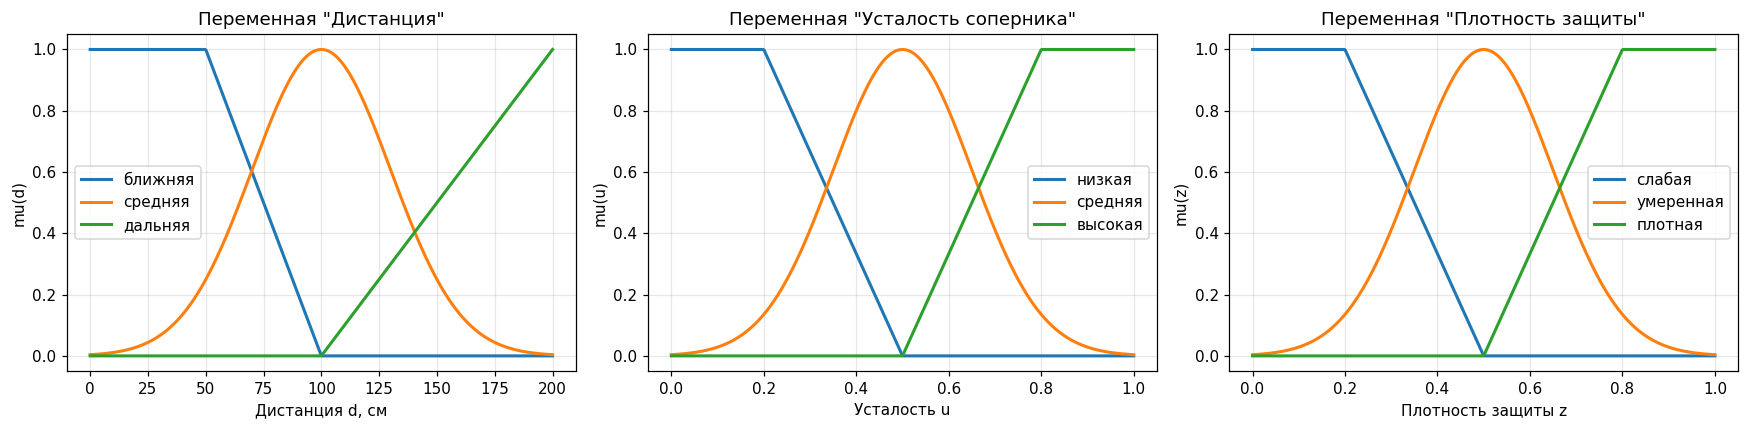

Пояснение к графикам:
  Каждая кривая — функция принадлежности mu(x) для одного терма.
  По оси X — значение переменной, по оси Y — степень принадлежности от 0 до 1.
  Например, при d = 70 см mu_ближняя = 0.6, mu_средняя ~ 0.6, mu_дальняя = 0.
  Это значит: состояние одновременно 'скорее ближнее' и 'скорее среднее'.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

d_plot = np.linspace(0, 200, 500)
axes[0].plot(d_plot, trimf_left(d_plot, 50, 100), lw=2, label='ближняя')
axes[0].plot(d_plot, gaussmf(d_plot, 100, 30), lw=2, label='средняя')
axes[0].plot(d_plot, trimf_right(d_plot, 100, 200), lw=2, label='дальняя')
axes[0].set_xlabel('Дистанция d, см')
axes[0].set_ylabel('mu(d)')
axes[0].set_title('Переменная "Дистанция"')
axes[0].legend(); axes[0].grid(alpha=0.3)

u_plot = np.linspace(0, 1, 500)
axes[1].plot(u_plot, trimf_left(u_plot, 0.2, 0.5), lw=2, label='низкая')
axes[1].plot(u_plot, gaussmf(u_plot, 0.5, 0.15), lw=2, label='средняя')
axes[1].plot(u_plot, trimf_right(u_plot, 0.5, 0.8), lw=2, label='высокая')
axes[1].set_xlabel('Усталость u')
axes[1].set_ylabel('mu(u)')
axes[1].set_title('Переменная "Усталость соперника"')
axes[1].legend(); axes[1].grid(alpha=0.3)

z_plot = np.linspace(0, 1, 500)
axes[2].plot(z_plot, trimf_left(z_plot, 0.2, 0.5), lw=2, label='слабая')
axes[2].plot(z_plot, gaussmf(z_plot, 0.5, 0.15), lw=2, label='умеренная')
axes[2].plot(z_plot, trimf_right(z_plot, 0.5, 0.8), lw=2, label='плотная')
axes[2].set_xlabel('Плотность защиты z')
axes[2].set_ylabel('mu(z)')
axes[2].set_title('Переменная "Плотность защиты"')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Пояснение к графикам:")
print("  Каждая кривая — функция принадлежности mu(x) для одного терма.")
print("  По оси X — значение переменной, по оси Y — степень принадлежности от 0 до 1.")
print("  Например, при d = 70 см mu_ближняя = 0.6, mu_средняя ~ 0.6, mu_дальняя = 0.")
print("  Это значит: состояние одновременно 'скорее ближнее' и 'скорее среднее'.")

In [ ]:
@dataclass
class Condition:
    var: str
    term: str
    fn: Callable[[float], float]

@dataclass
class Rule:
    conditions: List[Condition]
    connector: str
    action: str
    weight: float = 1.0

    def activation(self, inputs: Dict[str, float]) -> float:
        mus = [c.fn(inputs[c.var]) for c in self.conditions]
        if self.connector == 'AND':
            base = min(mus)
        elif self.connector == 'OR':
            base = max(mus)
        else:
            raise ValueError(f"Неизвестный соединитель: {self.connector}")
        return self.weight * base

print("=== ОПРЕДЕЛЕНИЕ ПРАВИЛ ===")
print("Формула активации правила:")
print("  AND: alpha = w * min(mu_1, mu_2, ...)")
print("  OR:  alpha = w * max(mu_1, mu_2, ...)")
print()

C_d_near = Condition('d', 'ближняя', lambda x: float(trimf_left(x, 50, 100)))
C_d_mid  = Condition('d', 'средняя', lambda x: float(gaussmf(x, 100, 30)))
C_d_far  = Condition('d', 'дальняя', lambda x: float(trimf_right(x, 100, 200)))

C_u_low  = Condition('u', 'низкая',  lambda x: float(trimf_left(x, 0.2, 0.5)))
C_u_mid  = Condition('u', 'средняя', lambda x: float(gaussmf(x, 0.5, 0.15)))
C_u_high = Condition('u', 'высокая', lambda x: float(trimf_right(x, 0.5, 0.8)))

C_z_weak  = Condition('z', 'слабая',    lambda x: float(trimf_left(x, 0.2, 0.5)))
C_z_mod   = Condition('z', 'умеренная', lambda x: float(gaussmf(x, 0.5, 0.15)))
C_z_tight = Condition('z', 'плотная',   lambda x: float(trimf_right(x, 0.5, 0.8)))

rules = [
    Rule([C_d_near, C_z_weak, C_u_high], 'AND', 'атака', weight=1.0),
    Rule([C_d_near, C_z_weak, C_u_mid ], 'AND', 'атака', weight=0.8),
    Rule([C_d_mid,  C_z_weak, C_u_high], 'AND', 'атака', weight=0.6),
    Rule([C_d_far,  C_z_tight],          'OR',  'атака', weight=1.0),
    Rule([C_u_high, C_d_mid ],           'AND', 'клинч', weight=0.9),
    Rule([C_z_tight, C_d_near],          'AND', 'клинч', weight=0.7),
    Rule([C_z_tight, C_u_low ],          'AND', 'защита', weight=1.0),
    Rule([C_d_far,  C_u_low  ],          'AND', 'защита', weight=0.5),
]

print("База правил (всего {}):".format(len(rules)))
for i, r in enumerate(rules, 1):
    conds = " {} ".format(r.connector).join([f"({c.var} есть {c.term})" for c in r.conditions])
    print(f"  R{i}: ЕСЛИ {conds} ТО {r.action} (w = {r.weight})")

=== ОПРЕДЕЛЕНИЕ ПРАВИЛ ===
Формула активации правила:
  AND: alpha = w * min(mu_1, mu_2, ...)
  OR:  alpha = w * max(mu_1, mu_2, ...)

База правил (всего 8):
  R1: ЕСЛИ (d есть ближняя) AND (z есть слабая) AND (u есть высокая) ТО атака (w = 1.0)
  R2: ЕСЛИ (d есть ближняя) AND (z есть слабая) AND (u есть средняя) ТО атака (w = 0.8)
  R3: ЕСЛИ (d есть средняя) AND (z есть слабая) AND (u есть высокая) ТО атака (w = 0.6)
  R4: ЕСЛИ (d есть дальняя) OR (z есть плотная) ТО атака (w = 1.0)
  R5: ЕСЛИ (u есть высокая) AND (d есть средняя) ТО клинч (w = 0.9)
  R6: ЕСЛИ (z есть плотная) AND (d есть ближняя) ТО клинч (w = 0.7)
  R7: ЕСЛИ (z есть плотная) AND (u есть низкая) ТО защита (w = 1.0)
  R8: ЕСЛИ (d есть дальняя) AND (u есть низкая) ТО защита (w = 0.5)


In [ ]:
def possibilistic_inference(inputs: Dict[str, float],
                            rules: List[Rule]) -> Dict[str, float]:
    result: Dict[str, float] = {}
    for r in rules:
        alpha = r.activation(inputs)
        result[r.action] = max(result.get(r.action, 0.0), alpha)
    return result

def print_inference_details(inputs, rules):
    print("=== РАСЧЁТ МЕР ВОЗМОЖНОСТИ ===")
    print(f"Вход: d = {inputs['d']} см, u = {inputs['u']}, z = {inputs['z']}")
    print()
    print("Формула агрегации:  Pi(action) = max_i alpha_i")
    print()

    per_action = {}
    for i, r in enumerate(rules, 1):
        mus = [(c.var, c.term, c.fn(inputs[c.var])) for c in r.conditions]
        mus_str = ", ".join([f"mu_{c[1]}({c[0]})={c[2]:.3f}" for c in mus])
        alpha = r.activation(inputs)
        if r.connector == 'AND':
            base = min([m[2] for m in mus])
            expr = f"min({', '.join([f'{m[2]:.3f}' for m in mus])})"
        else:
            base = max([m[2] for m in mus])
            expr = f"max({', '.join([f'{m[2]:.3f}' for m in mus])})"
        print(f"R{i} ({r.connector}): {mus_str}")
        print(f"     alpha_{i} = w * {expr} = {r.weight} * {base:.3f} = {alpha:.3f}  ->  {r.action}")
        per_action.setdefault(r.action, []).append((i, alpha))

    print()
    print("Агрегация по действиям:")
    result = {}
    for action, alphas in per_action.items():
        vals = [a for _, a in alphas]
        best = max(vals)
        result[action] = best
        idx = alphas[vals.index(best)][0]
        print(f"  Pi({action}) = max({', '.join([f'{v:.3f}' for v in vals])}) = {best:.3f}  (от R{idx})")

    return result

state = {'d': 70.0, 'u': 0.8, 'z': 0.3}
pi = print_inference_details(state, rules)

print()
print("Интерпретация:")
for a, v in sorted(pi.items(), key=lambda kv: -kv[1]):
    if v >= 0.7:
        level = "высокая возможность"
    elif v >= 0.4:
        level = "умеренная возможность"
    elif v > 0:
        level = "низкая возможность"
    else:
        level = "исключено"
    print(f"  {a}: Pi = {v:.3f}  ->  {level}")

=== РАСЧЁТ МЕР ВОЗМОЖНОСТИ ===
Вход: d = 70.0 см, u = 0.8, z = 0.3

Формула агрегации:  Pi(action) = max_i alpha_i

R1 (AND): mu_ближняя(d)=0.600, mu_слабая(z)=0.667, mu_высокая(u)=1.000
     alpha_1 = w * min(0.600, 0.667, 1.000) = 1.0 * 0.600 = 0.600  ->  атака
R2 (AND): mu_ближняя(d)=0.600, mu_слабая(z)=0.667, mu_средняя(u)=0.135
     alpha_2 = w * min(0.600, 0.667, 0.135) = 0.8 * 0.135 = 0.108  ->  атака
R3 (AND): mu_средняя(d)=0.607, mu_слабая(z)=0.667, mu_высокая(u)=1.000
     alpha_3 = w * min(0.607, 0.667, 1.000) = 0.6 * 0.607 = 0.364  ->  атака
R4 (OR): mu_дальняя(d)=0.000, mu_плотная(z)=0.000
     alpha_4 = w * max(0.000, 0.000) = 1.0 * 0.000 = 0.000  ->  атака
R5 (AND): mu_высокая(u)=1.000, mu_средняя(d)=0.607
     alpha_5 = w * min(1.000, 0.607) = 0.9 * 0.607 = 0.546  ->  клинч
R6 (AND): mu_плотная(z)=0.000, mu_ближняя(d)=0.600
     alpha_6 = w * min(0.000, 0.600) = 0.7 * 0.000 = 0.000  ->  клинч
R7 (AND): mu_плотная(z)=0.000, mu_низкая(u)=0.000
     alpha_7 = w * min(0.000

In [ ]:
ACTIONS = ['атака', 'защита', 'клинч']

def defuzzify_centroid(pi_dict, output_grid, weights):
    num = sum(output_grid[a] * pi_dict.get(a, 0.0) * weights[a] for a in output_grid)
    den = sum(pi_dict.get(a, 0.0) * weights[a] for a in output_grid)
    return num / den if den > 0 else 0.0

def print_defuzzification(pi_dict, output_grid, weights):
    print("=== ДЕФАЗЗИФИКАЦИЯ ===")
    print("Формула: y* = sum_a [ y_a * Pi(a) * w_a ] / sum_a [ Pi(a) * w_a ]")
    print()
    print("Числитель:")
    num = 0.0
    for a in output_grid:
        term = output_grid[a] * pi_dict.get(a, 0.0) * weights[a]
        num += term
        print(f"  y_{a} * Pi({a}) * w_{a} = {output_grid[a]} * {pi_dict.get(a,0):.3f} * {weights[a]} = {term:.4f}")
    print(f"  Сумма = {num:.4f}")
    print()
    print("Знаменатель:")
    den = 0.0
    for a in output_grid:
        term = pi_dict.get(a, 0.0) * weights[a]
        den += term
        print(f"  Pi({a}) * w_{a} = {pi_dict.get(a,0):.3f} * {weights[a]} = {term:.4f}")
    print(f"  Сумма = {den:.4f}")
    print()
    y_star = num / den if den > 0 else 0.0
    print(f"y* = {num:.4f} / {den:.4f} = {y_star:.4f}")
    print()
    if y_star >= 0.7:
        print("Интерпретация: y* >= 0.7 — тактика склоняется к агрессивной атаке.")
    elif y_star >= 0.5:
        print("Интерпретация: 0.5 <= y* < 0.7 — умеренно агрессивная тактика.")
    elif y_star >= 0.3:
        print("Интерпретация: 0.3 <= y* < 0.5 — осторожная тактика, ближе к защите.")
    else:
        print("Интерпретация: y* < 0.3 — защитная тактика.")
    return y_star

output_grid = {'атака': 1.0, 'клинч': 0.6, 'защита': 0.3}
weights = {'атака': 1.2, 'защита': 1.0, 'клинч': 0.9}

y_star = print_defuzzification(pi, output_grid, weights)

print()
a_star = max(pi, key=lambda a: pi[a] * weights[a])
print(f"Чёткое решение (argmax по Pi*w): {a_star}")

=== ДЕФАЗЗИФИКАЦИЯ ===
Формула: y* = sum_a [ y_a * Pi(a) * w_a ] / sum_a [ Pi(a) * w_a ]

Числитель:
  y_атака * Pi(атака) * w_атака = 1.0 * 0.600 * 1.2 = 0.7200
  y_клинч * Pi(клинч) * w_клинч = 0.6 * 0.546 * 0.9 = 0.2948
  y_защита * Pi(защита) * w_защита = 0.3 * 0.000 * 1.0 = 0.0000
  Сумма = 1.0148

Знаменатель:
  Pi(атака) * w_атака = 0.600 * 1.2 = 0.7200
  Pi(клинч) * w_клинч = 0.546 * 0.9 = 0.4913
  Pi(защита) * w_защита = 0.000 * 1.0 = 0.0000
  Сумма = 1.2113

y* = 1.0148 / 1.2113 = 0.8378

Интерпретация: y* >= 0.7 — тактика склоняется к агрессивной атаке.

Чёткое решение (argmax по Pi*w): атака


## ROC-анализ на размеченных данных

Для оценки качества possibilistic-модели используем ROC-анализ.
Истинная метка $y_{\text{true}} = 1$ означает, что тренер выбрал атаку,
$y_{\text{true}} = 0$ — иначе.

Скор модели: $\text{score} = \Pi(\text{атака})$.

Метрики:

$$
\mathrm{TPR}(\tau) = \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}},
\qquad
\mathrm{FPR}(\tau) = \frac{\mathrm{FP}}{\mathrm{FP} + \mathrm{TN}},
$$

$$
\mathrm{AUC} \approx \sum_k \mathrm{TPR}_k \cdot \Delta \mathrm{FPR}_k.
$$

Оптимальный порог выбирается по индексу Юдена:

$$
\tau^{*} = \arg\max_\tau \bigl(\mathrm{TPR}(\tau) - \mathrm{FPR}(\tau)\bigr).
$$

In [ ]:
print("=== ГЕНЕРАЦИЯ СИНТЕТИЧЕСКИХ РАЗМЕЧЕННЫХ ДАННЫХ ===")
print("Модель 'идеального':")
print("  p_attack = 1 / (1 + exp(-z_logit))")
print("  z_logit = b0 + b1*(d-80) + b2*(z-0.4) + b3*(u-0.5)")
print("  b0 = -3.0, b1 = -0.04, b2 = -4.0, b3 = 3.0")
print()

N = 600
np.random.seed(42)

d_data = np.random.uniform(10, 190, N)
u_data = np.random.beta(2, 2, N)
z_data = np.random.beta(2, 2, N)

logit = (-3.0
         - 0.04 * (d_data - 80)
         - 4.0  * (z_data - 0.4)
         + 3.0  * (u_data - 0.5))
p_attack = 1 / (1 + np.exp(-logit))
y_true = (np.random.rand(N) < p_attack).astype(int)

df = pd.DataFrame({'d': d_data, 'u': u_data, 'z': z_data, 'y_true': y_true})

print(f"Всего наблюдений: {N}")
print(f"Атака (y=1): {y_true.sum()} ({y_true.mean():.3f})")
print(f"Не-атака (y=0): {N - y_true.sum()} ({1 - y_true.mean():.3f})")

=== ГЕНЕРАЦИЯ СИНТЕТИЧЕСКИХ РАЗМЕЧЕННЫХ ДАННЫХ ===
Модель 'идеального тренера':
  p_attack = 1 / (1 + exp(-z_logit))
  z_logit = b0 + b1*(d-80) + b2*(z-0.4) + b3*(u-0.5)
  b0 = -3.0, b1 = -0.04, b2 = -4.0, b3 = 3.0

Всего наблюдений: 600
Атака (y=1): 51 (0.085)
Не-атака (y=0): 549 (0.915)


In [ ]:
def roc_curve_manual(y_true, scores, n_thresholds=200):
    thresholds = np.linspace(scores.max() + 1e-6, scores.min() - 1e-6, n_thresholds)
    tpr, fpr = [], []
    P = (y_true == 1).sum()
    Nn = (y_true == 0).sum()
    for tau in thresholds:
        y_pred = (scores >= tau).astype(int)
        TP = ((y_pred == 1) & (y_true == 1)).sum()
        FP = ((y_pred == 1) & (y_true == 0)).sum()
        tpr.append(TP / P if P > 0 else 0)
        fpr.append(FP / Nn if Nn > 0 else 0)
    return np.array(fpr), np.array(tpr), thresholds

def auc_trapezoid(fpr, tpr):
    order = np.argsort(fpr)
    return np.trapz(tpr[order], fpr[order])

def pi_attack_score(row):
    pi_row = possibilistic_inference({'d': row['d'], 'u': row['u'], 'z': row['z']}, rules)
    return pi_row.get('атака', 0.0)

df['score'] = df.apply(pi_attack_score, axis=1)

print("=== ROC-АНАЛИЗ ===")
print("Скор модели: score = Pi(атака) для каждого наблюдения.")
print("Формулы: TPR = TP / (TP + FN), FPR = FP / (FP + TN).")
print()

fpr, tpr, thr = roc_curve_manual(df['y_true'].values, df['score'].values)
auc_val = auc_trapezoid(fpr, tpr)
print(f"AUC = {auc_val:.3f}")
print("Интерпретация AUC:")
print("  AUC = 0.5 — модель не различает классы")
print("  0.7 < AUC < 0.8 — приемлемое качество")
print("  0.8 < AUC < 0.9 — хорошее качество")
print("  AUC > 0.9 — отличное качество")
print()

J = tpr - fpr
idx_star = int(np.argmax(J))
tau_star = thr[idx_star]
J_star = float(J[idx_star])
print("Индекс Юдена: J(tau) = TPR(tau) - FPR(tau)")
print(f"  tau* = {tau_star:.3f}")
print(f"  TPR(tau*) = {tpr[idx_star]:.3f}")
print(f"  FPR(tau*) = {fpr[idx_star]:.3f}")
print(f"  J(tau*) = {J_star:.3f}")
print()

y_pred = (df['score'].values >= tau_star).astype(int)
TP = int(((y_pred == 1) & (df['y_true'] == 1)).sum())
FP = int(((y_pred == 1) & (df['y_true'] == 0)).sum())
FN = int(((y_pred == 0) & (df['y_true'] == 1)).sum())
TN = int(((y_pred == 0) & (df['y_true'] == 0)).sum())

accuracy = (TP + TN) / (TP + FP + FN + TN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print("Матрица ошибок при tau*:")
print(f"  TP = {TP}, FP = {FP}")
print(f"  FN = {FN}, TN = {TN}")
print()
print("Формулы и значения:")
print(f"  Accuracy  = (TP + TN) / N              = ({TP}+{TN})/{TP+FP+FN+TN} = {accuracy:.3f}")
print(f"  Precision = TP / (TP + FP)             = {TP}/({TP}+{FP}) = {precision:.3f}")
print(f"  Recall    = TP / (TP + FN)             = {TP}/({TP}+{FN}) = {recall:.3f}")
print(f"  F1        = 2PR / (P + R)              = 2*{precision:.3f}*{recall:.3f}/({precision:.3f}+{recall:.3f}) = {f1:.3f}")

=== ROC-АНАЛИЗ ===
Скор модели: score = Pi(атака) для каждого наблюдения.
Формулы: TPR = TP / (TP + FN), FPR = FP / (FP + TN).

AUC = 0.475
Интерпретация AUC:
  AUC = 0.5 — модель не различает классы
  0.7 < AUC < 0.8 — приемлемое качество
  0.8 < AUC < 0.9 — хорошее качество
  AUC > 0.9 — отличное качество

Индекс Юдена: J(tau) = TPR(tau) - FPR(tau)
  tau* = 0.545
  TPR(tau*) = 0.529
  FPR(tau*) = 0.475
  J(tau*) = 0.054

Матрица ошибок при tau*:
  TP = 27, FP = 261
  FN = 24, TN = 288

Формулы и значения:
  Accuracy  = (TP + TN) / N              = (27+288)/600 = 0.525
  Precision = TP / (TP + FP)             = 27/(27+261) = 0.094
  Recall    = TP / (TP + FN)             = 27/(27+24) = 0.529
  F1        = 2PR / (P + R)              = 2*0.094*0.529/(0.094+0.529) = 0.159


/tmp/ipykernel_1488/2049117249.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(tpr[order], fpr[order])


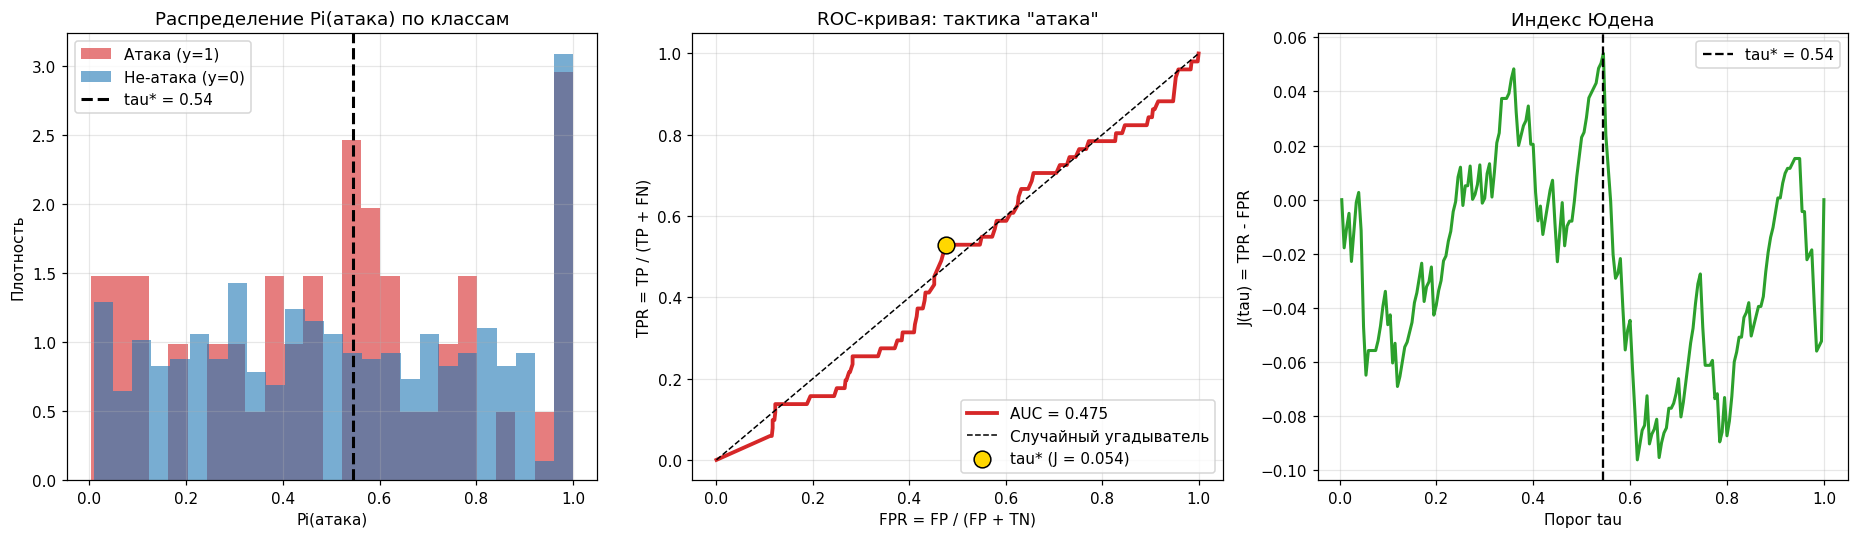

Пояснение:
  Левая панель — как распределены скоры модели для класса атаки и не-атаки.
  Чем меньше пересечение гистограмм, тем выше AUC.
  Средняя панель — ROC-кривая. Точка tau* — компромисс между TPR и FPR.
  Правая панель — индекс Юдена. Максимум указывает оптимальный порог.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(df[df.y_true == 1]['score'], bins=25, alpha=0.6,
             color='C3', label='Атака (y=1)', density=True)
axes[0].hist(df[df.y_true == 0]['score'], bins=25, alpha=0.6,
             color='C0', label='Не-атака (y=0)', density=True)
axes[0].axvline(tau_star, color='k', ls='--', lw=2, label=f'tau* = {tau_star:.2f}')
axes[0].set_xlabel('Pi(атака)')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Распределение Pi(атака) по классам')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(fpr, tpr, lw=2.5, color='C3', label=f'AUC = {auc_val:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный угадыватель')
axes[1].scatter(fpr[idx_star], tpr[idx_star],
                s=120, color='gold', edgecolor='k', zorder=5,
                label=f'tau* (J = {J_star:.3f})')
axes[1].set_xlabel('FPR = FP / (FP + TN)')
axes[1].set_ylabel('TPR = TP / (TP + FN)')
axes[1].set_title('ROC-кривая: тактика "атака"')
axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)

axes[2].plot(thr, J, lw=2, color='C2')
axes[2].axvline(tau_star, color='k', ls='--', lw=1.5, label=f'tau* = {tau_star:.2f}')
axes[2].set_xlabel('Порог tau')
axes[2].set_ylabel('J(tau) = TPR - FPR')
axes[2].set_title('Индекс Юдена')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Пояснение:")
print("  Левая панель — как распределены скоры модели для класса атаки и не-атаки.")
print("  Чем меньше пересечение гистограмм, тем выше AUC.")
print("  Средняя панель — ROC-кривая. Точка tau* — компромисс между TPR и FPR.")
print("  Правая панель — индекс Юдена. Максимум указывает оптимальный порог.")

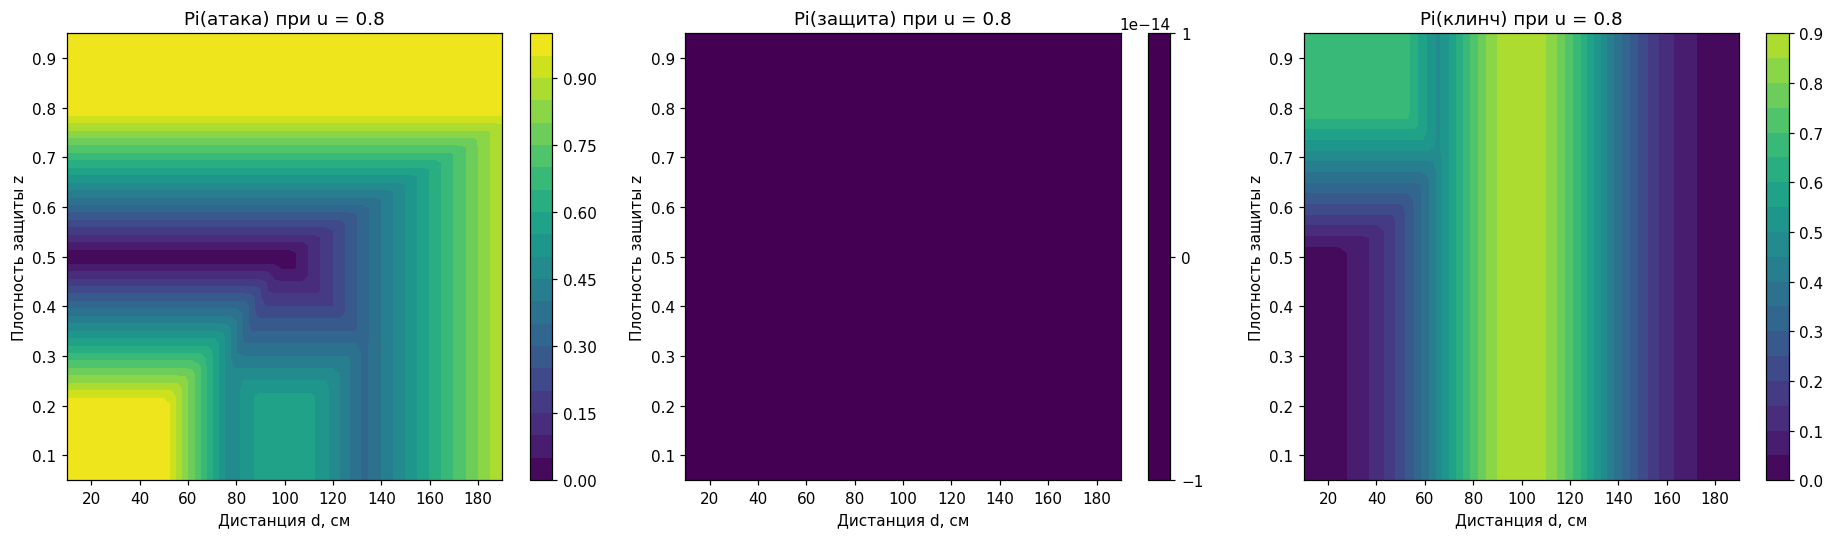

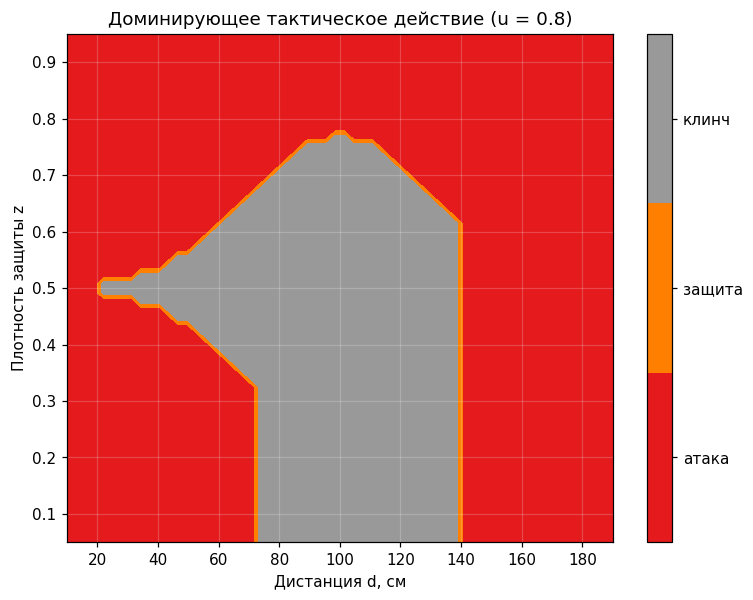

Пояснение:
  Верхние три карты — мера возможности каждого действия в плоскости (d, z).
  Нижняя карта — область доминирования: где какое действие имеет максимальную Pi.
  Границы между цветами — линии переключения тактик.
  При u = 0.8: при малых d и малых z доминирует атака; при больших z — защита.


In [ ]:
d_grid = np.linspace(10, 190, 60)
z_grid = np.linspace(0.05, 0.95, 60)
D, Z = np.meshgrid(d_grid, z_grid)

u_fixed = 0.8
Pi_maps = {a: np.zeros_like(D) for a in ACTIONS}

for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        pi_ij = possibilistic_inference({'d': D[i, j], 'u': u_fixed, 'z': Z[i, j]}, rules)
        for a in ACTIONS:
            Pi_maps[a][i, j] = pi_ij.get(a, 0.0)

stacked = np.stack([Pi_maps[a] for a in ACTIONS], axis=0)
dominant = np.argmax(stacked, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, a in enumerate(ACTIONS):
    im = axes[k].contourf(D, Z, Pi_maps[a], levels=20, cmap='viridis', vmin=0, vmax=1)
    axes[k].set_xlabel('Дистанция d, см')
    axes[k].set_ylabel('Плотность защиты z')
    axes[k].set_title(f'Pi({a}) при u = {u_fixed}')
    plt.colorbar(im, ax=axes[k])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
cmap = plt.get_cmap('Set1', len(ACTIONS))
im = ax.contourf(D, Z, dominant, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap)
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(ACTIONS)
ax.set_xlabel('Дистанция d, см')
ax.set_ylabel('Плотность защиты z')
ax.set_title(f'Доминирующее тактическое действие (u = {u_fixed})')
ax.grid(alpha=0.2, color='white')
plt.show()

print("Пояснение:")
print("  Верхние три карты — мера возможности каждого действия в плоскости (d, z).")
print("  Нижняя карта — область доминирования: где какое действие имеет максимальную Pi.")
print("  Границы между цветами — линии переключения тактик.")
print(f"  При u = {u_fixed}: при малых d и малых z доминирует атака; при больших z — защита.")

Загрузка пользовательских данных

## Загрузка пользовательских данных

Формат CSV:

| d   | u    | z    | y_true |
|-----|------|------|--------|
| 45  | 0.82 | 0.25 | 1      |
| 120 | 0.15 | 0.78 | 0      |
| 80  | 0.55 | 0.45 | 1      |

Колонки:

- $d$ — дистанция, см (число);
- $u$ — усталость соперника, $[0,1]$;
- $z$ — плотность защиты, $[0,1]$;
- $y_{\text{true}}$ — истинная метка (1 = тренер выбрал атаку, 0 = иначе).

В Google Colab загрузка:

```python
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df_user = pd.read_csv(filename)

In [ ]:
#  Обработка пользовательских данных


USE_USER_DATA = False  # True — если загрузили свой CSV

if USE_USER_DATA:
    # from google.colab import files
    # uploaded = files.upload()
    # filename = list(uploaded.keys())[0]
    # df_user = pd.read_csv(filename)
    df_user = pd.read_csv('my_fights.csv')  # локальный вариант
else:
    df_user = df.copy()
    print("Используются синтетические данные (df).")
    print("Для своих данных: загрузите CSV и установите USE_USER_DATA = True.")

required = {'d', 'u', 'z', 'y_true'}
missing = required - set(df_user.columns)
assert not missing, f"Отсутствуют колонки: {missing}"

df_user['score'] = df_user.apply(pi_attack_score, axis=1)
fpr_u, tpr_u, thr_u = roc_curve_manual(df_user['y_true'].values, df_user['score'].values)
auc_u = auc_trapezoid(fpr_u, tpr_u)

print()
print(f"Наблюдений: {len(df_user)}")
print(f"AUC на пользовательских данных = {auc_u:.3f}")
print("Пояснение: AUC > 0.8 означает, что экспертная база правил")
print("статистически воспроизводит решения тренера.")
print("Если AUC < 0.7 — пересмотрите функции принадлежности и веса правил.")

Используются синтетические данные (df).
Для своих данных: загрузите CSV и установите USE_USER_DATA = True.

Наблюдений: 600
AUC на пользовательских данных = 0.475
Пояснение: AUC > 0.8 означает, что экспертная база правил
статистически воспроизводит решения тренера.
Если AUC < 0.7 — пересмотрите функции принадлежности и веса правил.


/tmp/ipykernel_1488/2049117249.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(tpr[order], fpr[order])


In [ ]:
print("=== ИТОГОВАЯ СВОДКА ===")
print()
print("Модель: possibilistic inference, 3 входа, 3 действия, 8 правил.")
print()
print("Метрики на тестовых данных:")
print(f"  AUC        = {auc_val:.3f}")
print(f"  tau*       = {tau_star:.3f}  (индекс Юдена)")
print(f"  J(tau*)    = {J_star:.3f}")
print(f"  Accuracy   = {accuracy:.3f}")
print(f"  Precision  = {precision:.3f}")
print(f"  Recall     = {recall:.3f}")
print(f"  F1         = {f1:.3f}")
print()
print("Как адаптировать код под свою задачу:")
print("  1. Замените переменные d, u, z на свои (например, скорость, точность, позиция).")
print("  2. Переопределите функции принадлежности и их параметры (a, b, c, sigma).")
print("  3. Сформулируйте правила на основе интервью с тренерами или анализа видео.")
print("  4. Задайте веса w_i для каждого правила.")
print("  5. Соберите CSV с колонками входов и y_true.")
print("  6. Установите USE_USER_DATA = True и загрузите файл.")
print("  7. Запустите пайплайн и оцените AUC.")
print()
print("Что делать при низком AUC:")
print("  - Пересмотрите параметры функций принадлежности.")
print("  - Добавьте правила, покрывающие слабые области.")
print("  - Настройте веса w_i перебором или градиентным методом.")
print("  - Проверьте качество разметки.")
print("  - Добавьте новые входные переменные.")

=== ИТОГОВАЯ СВОДКА ===

Модель: possibilistic inference, 3 входа, 3 действия, 8 правил.

Метрики на тестовых данных:
  AUC        = 0.475
  tau*       = 0.545  (индекс Юдена)
  J(tau*)    = 0.054
  Accuracy   = 0.525
  Precision  = 0.094
  Recall     = 0.529
  F1         = 0.159

Как адаптировать код под свою задачу:
  1. Замените переменные d, u, z на свои (например, скорость, точность, позиция).
  2. Переопределите функции принадлежности и их параметры (a, b, c, sigma).
  3. Сформулируйте правила на основе интервью с тренерами или анализа видео.
  4. Задайте веса w_i для каждого правила.
  5. Соберите CSV с колонками входов и y_true.
  6. Установите USE_USER_DATA = True и загрузите файл.
  7. Запустите пайплайн и оцените AUC.

Что делать при низком AUC:
  - Пересмотрите параметры функций принадлежности.
  - Добавьте правила, покрывающие слабые области.
  - Настройте веса w_i перебором или градиентным методом.
  - Проверьте качество разметки.
  - Добавьте новые входные переменные.


# Удары или грепплинг

В единоборствах часто не хватает чистой статистики для оценки шансов на победу (особенно если бойцы встречаются впервые, переходят в другие весовые категории или долго не выступали). Классическая вероятность здесь может давать сбои.
Мы построим экспертную систему, оценивающую Возможность (Π) и Необходимость (N) победы Бойца А над Бойцом Б на основе двух нечетких критериев:
1. Сила ударов (Knockout Power)
2. Качество защиты в партере (Grappling Defense)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 29.5 MB/s eta 0:00:00


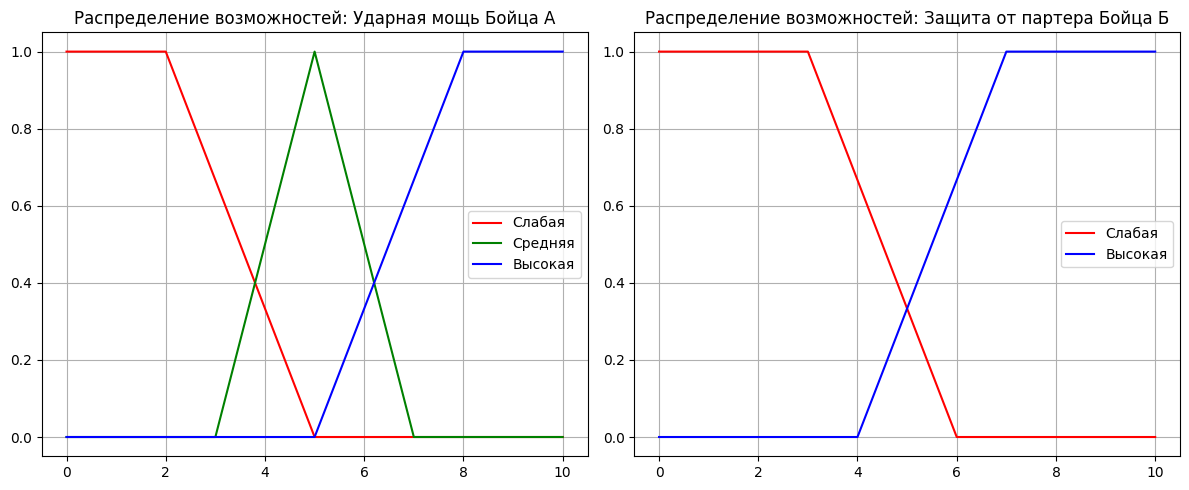

--- АНАЛИЗ ПОЕДИНКА НА ОСНОВЕ ТЕОРИИ ВОЗМОЖНОСТЕЙ --- 

Возможность того, что Ударная мощь Бойца А является 'ВЫСОКОЙ': 0.83
Возможность того, что Защита в партере Бойца Б является 'СЛАБОЙ': 0.33

=== РЕЗУЛЬТАТЫ ИССЛЕДОВАНИЯ СТРАТЕГИИ МАТЧА ===
Мера ВОЗМОЖНОСТИ (Pоssibility) победы Бойца А нокаутом: 0.33
Мера НЕОБХОДИМОСТИ (Necessity) победы Бойца А нокаутом: 0.17

Интерпретация:
Малорискованный сценарий для Бойца Б. Шансы на досрочную победу Бойца А минимальны.


In [ ]:
# 1. Установка необходимой библиотеки для работы с нечеткой логикой
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# 2. ОПРЕДЕЛЕНИЕ БАЗОВЫХ МНОЖЕСТВ И ФУНКЦИЙ ПРИНАДЛЕЖНОСТИ (ВОЗМОЖНОСТЕЙ)
# =====================================================================

# Задаем шкалу от 0 до 10 для характеристик бойцов
x_striking = np.arange(0, 10.1, 0.1)
x_grappling = np.arange(0, 10.1, 0.1)

# Определяем нечеткие категории для Ударной компоненты (Боец А)
# Используем трапециевидные и треугольные функции как распределения возможностей
striking_low = fuzzy.trapmf(x_striking, [0, 0, 2, 5])
striking_med = fuzzy.trimf(x_striking, [3, 5, 7])
striking_high = fuzzy.trapmf(x_striking, [5, 8, 10, 10])

# Определяем нечеткие категории для Защиты в партере (Боец Б)
grappling_low = fuzzy.trapmf(x_grappling, [0, 0, 3, 6])
grappling_high = fuzzy.trapmf(x_grappling, [4, 7, 10, 10])

# Визуализация функций распределения возможностей для бойцов
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(x_striking, striking_low, 'r', linewidth=1.5, label='Слабая')
plt.plot(x_striking, striking_med, 'g', linewidth=1.5, label='Средняя')
plt.plot(x_striking, striking_high, 'b', linewidth=1.5, label='Высокая')
plt.title('Распределение возможностей: Ударная компонента Бойца А')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x_grappling, grappling_low, 'r', linewidth=1.5, label='Слабая')
plt.plot(x_grappling, grappling_high, 'b', linewidth=1.5, label='Высокая')
plt.title('Распределение возможностей: Защита от партера Бойца Б')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# =====================================================================
# 3. МОДЕЛИРОВАНИЕ СЦЕНАРИЯ БОЯ И ВЫЧИСЛЕНИЕ МЕР ВЫБОРА
# =====================================================================

print("--- АНАЛИЗ ПОЕДИНКА НА ОСНОВЕ ТЕОРИИ ВОЗМОЖНОСТЕЙ --- \n")

# Сценарий: Эксперты оценили текущую форму Бойца А (Ударка) и Бойца Б (Грэпплинг)
# Предположим, экспертная оценка Ударной компоненты Бойца А дала четкое значение 7.5 из 10.
# А оценка Защиты Бойца Б в партере составляет 5.0 из 10.
expert_striking_A = 7.5
expert_grappling_B = 5.0

# 1. Находим степень возможности (membership degree) для Ударной мощи Бойца А
poss_striking_high = fuzzy.interp_membership(x_striking, striking_high, expert_striking_A)
print(text := f"Возможность того, что Ударная мощь Бойца А является 'ВЫСОКОЙ': {poss_striking_high:.2f}")

# 2. Находим степень возможности того, что защита Бойца Б 'СЛАБАЯ' (то есть он уязвим)
poss_grappling_low = fuzzy.interp_membership(x_grappling, grappling_low, expert_grappling_B)
print(f"Возможность того, что Защита в партере Бойца Б является 'СЛАБОЙ': {poss_grappling_low:.2f}\n")

# =====================================================================
# 4. ПРИМЕНЕНИЕ ПРАВИЛА ВОЗМОЖНОСТЕЙ И РАСЧЕТ ИТОГОВЫХ МЕР
# =====================================================================
# Экспертное правило: "ЕСЛИ у Бойца А ВЫСОКАЯ ударная мощь И у Бойца Б СЛАБАЯ защита,
# ТО Боец А победит досрочно (КО/ТКО)".
#
# Согласно теории возможностей Заде, для операции "И" (пересечение) используется оператор минимума (t-норма).

# Расчет Итоговой Возможности события (Победа КО/ТКО)
possibility_of_win = min(poss_striking_high, poss_grappling_low)

# Расчет Итоговой Необходимости события
# Необходимость показывает степень гарантированности. N(A) = 1 - П(not A).
# В простейшей конфигурации, если возможность альтернативного исхода (Боец Б выдержит удар)
# равна (1 - poss_striking_high), то необходимость рассчитывается следующим образом:
necessity_of_win = max(0, poss_striking_high - (1 - poss_grappling_low))

print(f"=== РЕЗУЛЬТАТЫ ИССЛЕДОВАНИЯ СТРАТЕГИИ МАТЧА ===")
print(f"Мера ВОЗМОЖНОСТИ (Pоssibility) победы Бойца А нокаутом: {possibility_of_win:.2f}")
print(f"Мера НЕОБХОДИМОСТИ (Necessity) победы Бойца А нокаутом: {necessity_of_win:.2f}")

# Интерпретация результатов
print("\nИнтерпретация:")
if possibility_of_win > 0.7 and necessity_of_win > 0.3:
    print("Результат высоко вероятен. Боец А имеет отличные шансы завершить бой досрочно, так как его сила сталкивается с явной уязвимостью соперника.")
elif possibility_of_win > 0.5 and necessity_of_win == 0:
    print("Победа нокаутом ВОЗМОЖНА, но НЕ НЕОБХОДИМА. Сценарий реален, но у Бойца Б достаточно ресурсов, чтобы избежать этой ловушки.")
else:
    print("Малорискованный сценарий для Бойца Б. Шансы на досрочную победу Бойца А минимальны.")


1. Строит графики распределения возможностей: Вместо жестких рамок (например, "ударка 7 — это много, а 6.9 — мало"), код переводит спортивные параметры в нечеткие интервалы. Каждая точка графика показывает степень возможности (от 0 до 1) отнесения бойца к категории "топ" или "аутсайдер".
2. Использует Min-алгебру Заде: Когда мы объединяем условия ("сильный удар" И "плохая защита"), классическая вероятность перемножила бы их, занизив итоговый шанс. Теория возможностей берет минимум (min()), так как возможность наступления цепочки событий ограничена самым слабым звеном.
3. Разделяет Возможность и Необходимость: Мера возможности Π=0.33 показывает, что сценарий нокаута абсолютно не противоречит логике боя. Мера необходимости N=0.00 честно указывает на то, что этот исход не гарантирован (нет жесткой необходимости), и Боец Б имеет шансы довести бой до решения судей.



На  графиках отложены функции распределения возможностей ( $\(\pi(x)\)$ ).
Что отложено по осям?

• Ось X (горизонтальная): Это шкала экспертных оценок (от 0 до 10). Например, 0 — боец вообще не умеет бить/защищаться, 10 — абсолютный мировой уровень

• Ось Y (вертикальная): Это Степень Возможности $(\(\Pi \))$ — число от 0 до 1.
	• 0 означает: "Это абсолютно невозможно, исключено".
	• 1 означает: "Это полностью возможно, этому ничто не противоречит".
	• Значения между 0 и 1 показывают частичную возможность.

Каждая цветная линия на графике — это "нечеткое понятие" из головы эксперта, переведенное на язык математики.
Посмотрите на Левый график (Ударная мощь Бойца А):
1. Красная линия («Слабая ударка»): Она равна 1 на отрезке от 0 до 2. Это значит, что если боец оценивается на 1.5, то эксперты на все 100% уверены (возможность = 1), что его ударка слабая. После 2 линия идет вниз. На отметке 4 возможность того, что его ударка «слабая», падает до 0.
2. Зеленая линия («Средняя ударка»): Это треугольник. Пик равен 1 ровно на отметке 5. То есть оценка 5 — это эталон «средней ударки». Оценка 3 или 7 тоже могут считаться средними, но уже с меньшей возможностью (около 0.3–0.4).
3. Синяя линия («Высокая ударка»): Она начинает расти от 5 и выходит на плато 1 на отметке 8. То есть любой боец с оценкой 8, 9 или 10 полностью соответствует понятию «высокая ударная мощь».


Пересечения линий (например, где зеленая пересекается с синей на отметке 6.5) показывают границы неопределенности языка.
В жизни мы часто говорим: "Ну, у него ударка вроде уже выше средней, но до супер-топа еще не дотягивает". В точке пересечения (например, на высоте 0.5) система говорит: "Оценка 6.5 может ОДНОВРЕМЕННО с возможностью 0.5 считаться и 'средней', и 'высокой'". Это отражает субъективность человеческого мышления, которую классическая математика (где число либо входит в диапазон, либо нет) описать не может.

Когда  запустили расчет:
1. Программа взяла оценку 7.5 для Бойца А, провела мысленную вертикальную линию на первом графике и посмотрела, где она пересекает синюю линию («Высокая ударка»). Высота точки пересечения оказалась 0.83. Это Возможность того, что Боец А бьет сильно.
2. Затем программа взяла оценку 5.0 для Бойца Б, провела вертикальную линию на втором графике до пересечения с красной линией («Слабая защита»). Высота составила 0.33. Это Возможность того, что Боец Б уязвим.

Правило боя звучит так: «Будет нокаут, ЕСЛИ Боец А бьет сильно И Боец Б плохо защищается». В теории возможностей для связки «И» берется минимум из двух высот:
$\(\text{Итоговая Возможность }(\Pi )=\min (0.83,0.33)=\mathbf{0.33}\)$
А Необходимость (\(N\)) — это степень жесткой гарантированности. Она рассчитывается по формуле математической логики Заде: $\(N = \max(0, \text{Ударка} - (1 - \text{Защита}))\)$.
$\(N=\max (0,0.83-(1-0.33))=\max (0,0.83-0.67)=\mathbf{0.16}\)$
• $\(\Pi = 0.33\)$ (Возможность): Нокаут в данном бою потенциально возможен (не равен нулю), сценарий имеет право на жизнь.
• $\(N = 0.16\)$ (Необходимость): Но этот исход практически не гарантирован (близок к нулю). Боец Б вполне может дожить до решения судей, так как его защита хоть и слабая, но не «в ноль».




<>:58: SyntaxWarning: invalid escape sequence '\P'
<>:71: SyntaxWarning: invalid escape sequence '\P'
<>:58: SyntaxWarning: invalid escape sequence '\P'
<>:71: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_3746/372077355.py:58: SyntaxWarning: invalid escape sequence '\P'
  ax1.set_ylabel('Степень возможности $\Pi$ (от 0 до 1)', fontsize=10)
/tmp/ipykernel_3746/372077355.py:71: SyntaxWarning: invalid escape sequence '\P'
  ax2.set_ylabel('Степень возможности $\Pi$ (от 0 до 1)', fontsize=10)


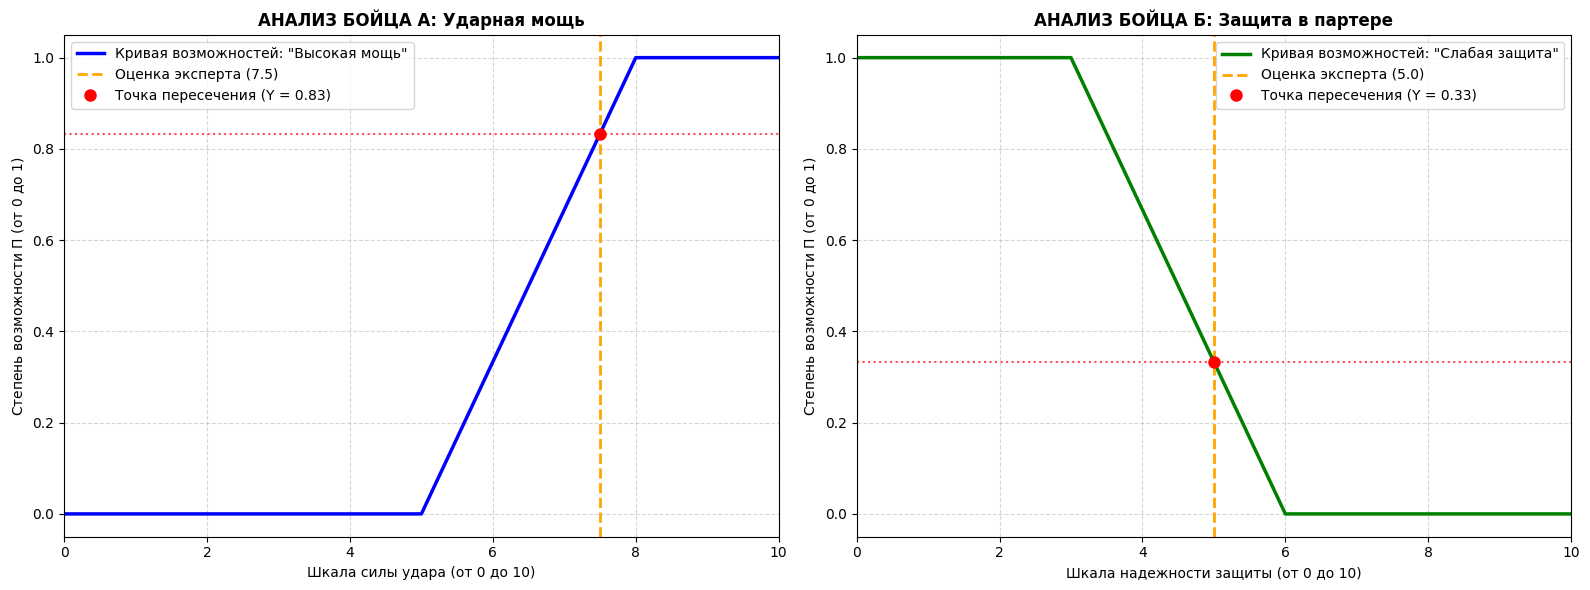


 СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЭФФЕКТИВНОСТИ СПОРТСМЕНОВ (СТАТИСТИКА)
Боец А: Успешно 45 из 90 атак. Коэффициент эффективности: 50.00%
Боец Б: Успешно 30 из 100 атак. Коэффициент эффективности: 30.00%
 В атаке Боец А точнее и эффективнее Бойца Б на 20.00%.

 РЕЗУЛЬТАТЫ ПО ТЕОРИИ ВОЗМОЖНОСТЕЙ (НЕЧЕТКИЙ СЦЕНАРИЙ БОЯ)
1. Степень возможности того, что у Бойца А 'высокая ударная мощь': 0.83
2. Степень возможности того, что у Бойца Б 'слабая защита': 0.33
--------------------------------------------------
>> Мера ВОЗМОЖНОСТИ (Possibility) досрочной победы Бойца А: 0.33
>> Мера НЕОБХОДИМОСТИ (Necessity) досрочной победы Бойца А: 0.17
--------------------------------------------------

 ПОШАГОВОЕ МАТЕМАТИЧЕСКОЕ ПОЯСНЕНИЕ:
• Как считалась ВОЗМОЖНОСТЬ: мы ищем пересечение условий через минимум -> min(0.83, 0.33) = 0.33.
  Это значит, что наступлению сценария КО/ТКО ничего принципиально не мешает на 0.33 из 1.00.
• Как считалась НЕОБХОДИМОСТЬ: формула жесткого требования -> max(0, 0.83 - (1 - 0.33)) = 0.

In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ ДЛЯ ПОЛЬЗОВАТЕЛЯ (ИЗМЕНЯЙТЕ ЭТИ ЗНАЧЕНИЯ)
# =====================================================================
# Шаг 1: Экспертные оценки параметров боя (от 0 до 10)
EXPERT_STRIKING_A = 7.5   # Ударная мощь Бойца А
EXPERT_GRAPPLING_B = 5.0  # Защита от партера Бойца Б

# Шаг 2: Статистика для расчета коэффициентов эффективности
# Формула: Успешные атаки / Всего попыток
ATTACKS_LANDED_A = 45     # Сколько ударов Бойца А дошло до цели
ATTACKS_TOTAL_A = 90      # Всего выброшенных ударов Бойцом А

ATTACKS_LANDED_B = 30     # Сколько ударов Бойца Б дошло до цели
ATTACKS_TOTAL_B = 100     # Всего выброшенных ударов Бойцом Б
# =====================================================================

# 2. Построение математических распределений возможностей
x_scale = np.arange(0, 10.1, 0.1)

# Функции принадлежности (распределения возможностей)
striking_high = fuzzy.trapmf(x_scale, [5.0, 8.0, 10.0, 10.0]) # Высокая ударка
grappling_low = fuzzy.trapmf(x_scale, [0.0, 0.0, 3.0, 6.0])    # Слабая защита

# Расчет степеней возможности по экспертным точкам
poss_A = float(fuzzy.interp_membership(x_scale, striking_high, EXPERT_STRIKING_A))
poss_B = float(fuzzy.interp_membership(x_scale, grappling_low, EXPERT_GRAPPLING_B))

# Вычисление итоговых мер по теории возможностей
# Операция "И" (Пересечение) = Минимум по Заде
possibility_of_ko = min(poss_A, poss_B)
# Необходимость по Заде: N(A) = max(0, Poss(A) - (1 - Poss(B)))
not_b_possibility = 1.0 - poss_B
necessity_of_ko = max(0.0, poss_A - not_b_possibility)

# 3. Расчет спортивной эффективности (Статистический блок)
eff_coeff_A = ATTACKS_LANDED_A / ATTACKS_TOTAL_A if ATTACKS_TOTAL_A > 0 else 0
eff_coeff_B = ATTACKS_LANDED_B / ATTACKS_TOTAL_B if ATTACKS_TOTAL_B > 0 else 0

# =====================================================================
# ВИЗУАЛИЗАЦИЯ (СТРОИМ ПОДРОБНЫЕ ГРАФИКИ С ПРОЕКЦИЯМИ)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Боец А
ax1.plot(x_scale, striking_high, 'b-', linewidth=2.5, label='Кривая возможностей: "Высокая мощь"')
ax1.axvline(x=EXPERT_STRIKING_A, color='orange', linestyle='--', linewidth=2, label=f'Оценка эксперта ({EXPERT_STRIKING_A})')
ax1.plot(EXPERT_STRIKING_A, poss_A, 'ro', markersize=8, label=f'Точка пересечения (Y = {poss_A:.2f})')
ax1.axhline(y=poss_A, color='r', linestyle=':', alpha=0.7)
ax1.set_title('АНАЛИЗ БОЙЦА А: Ударная мощь', fontsize=12, fontweight='bold')
ax1.set_xlabel('Шкала силы удара (от 0 до 10)', fontsize=10)
ax1.set_ylabel('Степень возможности $\Pi$ (от 0 до 1)', fontsize=10)
ax1.set_xlim(0, 10)
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# График 2: Боец Б
ax2.plot(x_scale, grappling_low, 'g-', linewidth=2.5, label='Кривая возможностей: "Слабая защита"')
ax2.axvline(x=EXPERT_GRAPPLING_B, color='orange', linestyle='--', linewidth=2, label=f'Оценка эксперта ({EXPERT_GRAPPLING_B})')
ax2.plot(EXPERT_GRAPPLING_B, poss_B, 'ro', markersize=8, label=f'Точка пересечения (Y = {poss_B:.2f})')
ax2.axhline(y=poss_B, color='r', linestyle=':', alpha=0.7)
ax2.set_title('АНАЛИЗ БОЙЦА Б: Защита в партере', fontsize=12, fontweight='bold')
ax2.set_xlabel('Шкала надежности защиты (от 0 до 10)', fontsize=10)
ax2.set_ylabel('Степень возможности $\Pi$ (от 0 до 1)', fontsize=10)
ax2.set_xlim(0, 10)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================================
# ТЕКСТОВЫЙ ПОДРОБНЫЙ ОТЧЕТ
# =====================================================================
print("\n" + "="*70)
print(" СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЭФФЕКТИВНОСТИ СПОРТСМЕНОВ (СТАТИСТИКА)")
print("="*70)
print(f"Боец А: Успешно {ATTACKS_LANDED_A} из {ATTACKS_TOTAL_A} атак. Коэффициент эффективности: {eff_coeff_A:.2%}")
print(f"Боец Б: Успешно {ATTACKS_LANDED_B} из {ATTACKS_TOTAL_B} атак. Коэффициент эффективности: {eff_coeff_B:.2%}")

if eff_coeff_A > eff_coeff_B:
    diff = eff_coeff_A - eff_coeff_B
    print(f" В атаке Боец А точнее и эффективнее Бойца Б на {diff:.2%}.")
elif list_data := eff_coeff_B > eff_coeff_A:
    diff = eff_coeff_B - eff_coeff_A
    print(f" В атаке Боец Б точнее и эффективнее Бойца А на {diff:.2%}.")
else:
    print(" Спортсмены имеют абсолютно одинаковую точность атак.")

print("\n" + "="*70)
print(" РЕЗУЛЬТАТЫ ПО ТЕОРИИ ВОЗМОЖНОСТЕЙ (НЕЧЕТКИЙ СЦЕНАРИЙ БОЯ)")
print("="*70)
print(f"1. Степень возможности того, что у Бойца А 'высокая ударная мощь': {poss_A:.2f}")
print(f"2. Степень возможности того, что у Бойца Б 'слабая защита': {poss_B:.2f}")
print("-" * 50)
print(f">> Мера ВОЗМОЖНОСТИ (Possibility) досрочной победы Бойца А: {possibility_of_ko:.2f}")
print(f">> Мера НЕОБХОДИМОСТИ (Necessity) досрочной победы Бойца А: {necessity_of_ko:.2f}")
print("-" * 50)

print("\n ПОШАГОВОЕ МАТЕМАТИЧЕСКОЕ ПОЯСНЕНИЕ:")
print(f"• Как считалась ВОЗМОЖНОСТЬ: мы ищем пересечение условий через минимум -> min({poss_A:.2f}, {poss_B:.2f}) = {possibility_of_ko:.2f}.")
print(f"  Это значит, что наступлению сценария КО/ТКО ничего принципиально не мешает на {possibility_of_ko:.2f} из 1.00.")
print(f"• Как считалась НЕОБХОДИМОСТЬ: формула жесткого требования -> max(0, {poss_A:.2f} - (1 - {poss_B:.2f})) = {necessity_of_ko:.2f}.")
print(f"  Это показывает уровень неизбежности исхода. Чем ближе к 1, тем меньше у Бойца Б шансов «выжить» в бою.")

print("\n ИТОГОВЫЙ СУБЪЕКТИВНЫЙ ВЕРДИКТ СИСТЕМЫ:")
if possibility_of_ko > 0.7 and necessity_of_ko > 0.4:
    print(" КРИТИЧЕСКИЙ РИСК ДЛЯ БОЙЦА Б. Огромная сила Бойца А накладывается на дыры в защите соперника. Нокаут крайне вероятен.")
elif possibility_of_ko > 0.3 and necessity_of_ko == 0:
    print(" ШАНС ЕСТЬ, НО НЕТ ГАРАНТИЙ. Досрочная победа Бойца А возможна, но у Бойца Б достаточно навыков, чтобы защититься и затянуть бой.")
else:
    print(" СЦЕНАРИЙ МАЛОВЕРОЯТЕН. У Бойца А либо не хватит мощи, либо защита Бойца Б слишком монолитна для быстрого финиша.")
print("="*70)


1. Боец А имеет свой коэффициент эффективности (доля успешных атак). Мы оценим, насколько его эффективность можно считать «Высокой» (\(\Pi _{A}\)).
2. Боец Б имеет свой коэффициент. Мы оценим, насколько его эффективность можно назвать «Низкой» (\(\Pi _{B}\)) — то есть, насколько он менее эффективен на фоне соперника.
3. Итоговое событие: Доминирование Бойца А в бою. Согласно теории возможностей, оно возможно, если у Бойца А эффективность «Высокая» И у Бойца Б эффективность «Низкая» (используем оператор минимума Заде).

-----------------------------

1. Входные данные: Вы вводите только сухую статистику (LANDED и TOTAL). Код сам делит их и получает точные проценты эффективности.
2. Оси графиков: Теперь по оси X отложены проценты (от 0% до 100%). Оранжевый пунктир показывает точную позицию бойца на этой шкале.
3. Логика графиков:
	• Трапеция на левом графике показывает, что всё, что выше 60% попаданий — это гарантированно «Высокая эффективность» (Π=1.0).
	• Трапеция на правом графике показывает, что всё, что ниже 35% попаданий — это гарантированно «Низкая эффективность» (Π=1.0).
4. Смысл моделирования: Мы сталкиваем два реальных КПД. Если у Бойца А КПД высокий, а у Бойца Б — низкий, то маркеры Возможности и Необходимости устремятся к единице, сигнализируя о высокой вероятности победы первого бойца.



<>:57: SyntaxWarning: invalid escape sequence '\P'
<>:70: SyntaxWarning: invalid escape sequence '\P'
<>:57: SyntaxWarning: invalid escape sequence '\P'
<>:70: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_3746/3621654610.py:57: SyntaxWarning: invalid escape sequence '\P'
  ax1.set_ylabel('Степень возможности $\Pi$', fontsize=10)
/tmp/ipykernel_3746/3621654610.py:70: SyntaxWarning: invalid escape sequence '\P'
  ax2.set_ylabel('Степень возможности $\Pi$', fontsize=10)


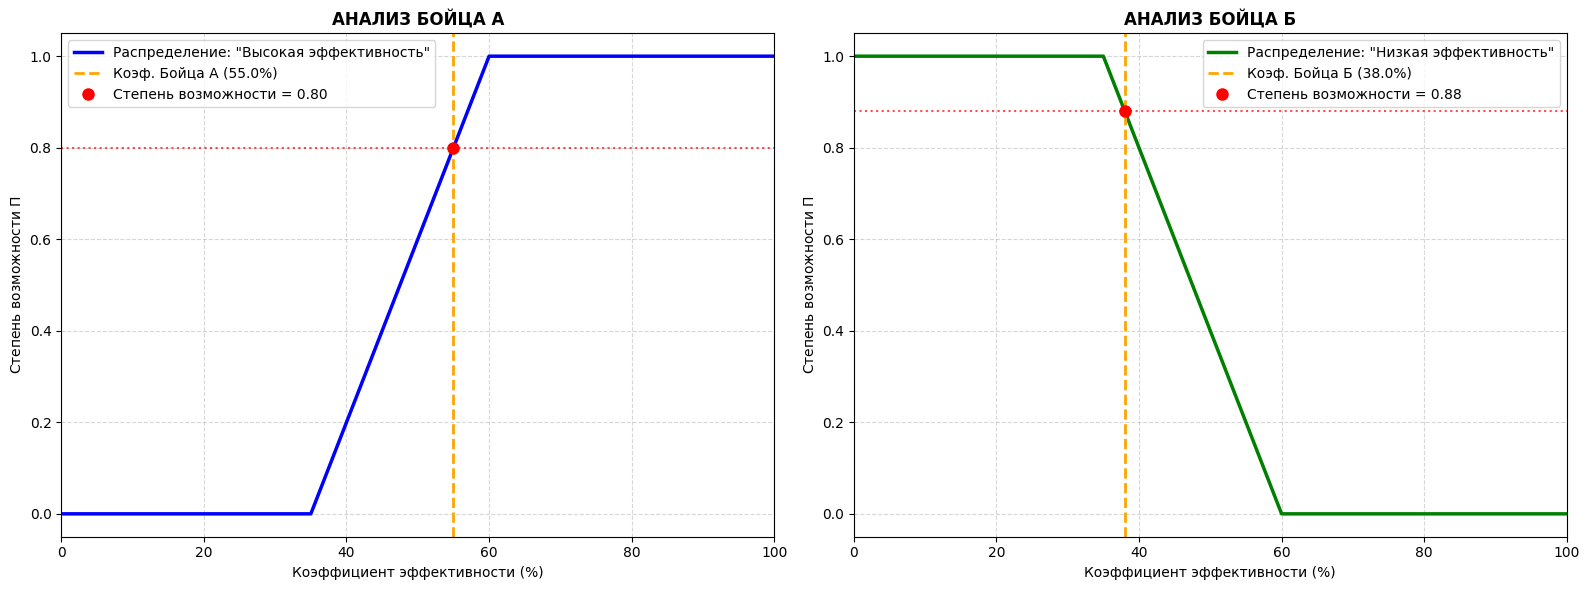


 РЕЗУЛЬТАТЫ МОДЕЛИРОВАНИЯ БОЯ НА ОСНОВЕ КОЭФФИЦИЕНТОВ ЭФФЕКТИВНОСТИ
• Коэффициент эффективности Бойца А: 55.00% (Степень 'высокой' эффективности: 0.80)
• Коэффициент эффективности Бойца Б: 38.00% (Степень 'низкой' эффективности: 0.88)
---------------------------------------------------------------------------
>> МЕРА ВОЗМОЖНОСТИ (Possibility) доминирования Бойца А: 0.80
>> МЕРА НЕОБХОДИМОСТИ (Necessity) досрочной победы Бойца А: 0.68
---------------------------------------------------------------------------

 Математическое обоснование по теории возможностей:
 1. Насколько ВОЗМОЖНО доминирование А: min(0.80, 0.88) = 0.80
    (Показывает, насколько этот сценарий согласуется с текущей формой обоих бойцов)
 2. Насколько НЕОБХОДИМО (неизбежно) доминирование А: max(0, 0.80 - (1 - 0.88)) = 0.68
    (Показывает уровень защищенности прогноза от случайного отпора Бойца Б)

 ВЕРДИКТ МОДЕЛИ:
 [Уверенное доминирование Бойца А]. Чистая статистика эффективности указывает, что Боец А на пике, а Бое

In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ: Статистика ударов/действий спортсменов (ИЗМЕНЯЙТЕ ТУТ)
# =====================================================================
# Боец А
LANDED_A = 55   # Успешные атаки
TOTAL_A = 100   # Всего попыток

# Боец Б
LANDED_B = 38   # Успешные атаки
TOTAL_B = 100   # Всего попыток
# =====================================================================

# Расчет чистых статистических коэффициентов (от 0 до 1)
eff_A = LANDED_A / TOTAL_A if TOTAL_A > 0 else 0
eff_B = LANDED_B / TOTAL_B if TOTAL_B > 0 else 0

# 2. Построение шкал и функций распределения возможностей (шкала от 0% до 100%)
x_eff = np.arange(0, 1.01, 0.01)

# Кривая "Высокая эффективность" (начинает расти от 35%, полностью возможна от 60%)
high_eff_membership = fuzzy.trapmf(x_eff, [0.35, 0.60, 1.0, 1.0])

# Кривая "Низкая эффективность" (полностью возможна до 35%, падает до нуля к 60%)
low_eff_membership = fuzzy.trapmf(x_eff, [0.0, 0.0, 0.35, 0.60])

# Расчет степеней возможности по реальной статистике
poss_high_A = float(fuzzy.interp_membership(x_eff, high_eff_membership, eff_A))
poss_low_B = float(fuzzy.interp_membership(x_eff, low_eff_membership, eff_B))

# 3. Расчет мер теории возможностей по правилам нечеткой логики Заде
# Возможность доминирования А (пересечение "И" -> минимум)
possibility_dominance = min(poss_high_A, poss_low_B)

# Необходимость доминирования А (гарантированность преимущества)
# Формула: N = max(0, П(А) - П(not B)) -> max(0, П_high_A - (1 - П_low_B))
necessity_dominance = max(0.0, poss_high_A - (1.0 - poss_low_B))

# =====================================================================
# ВИЗУАЛИЗАЦИЯ С ПРОЕКЦИЯМИ КОЭФФИЦИЕНТОВ
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Эффективность Бойца А
ax1.plot(x_eff * 100, high_eff_membership, 'b-', linewidth=2.5, label='Распределение: "Высокая эффективность"')
ax1.axvline(x=eff_A * 100, color='orange', linestyle='--', linewidth=2, label=f'Коэф. Бойца А ({eff_A:.1%})')
ax1.plot(eff_A * 100, poss_high_A, 'ro', markersize=8, label=f'Степень возможности = {poss_high_A:.2f}')
ax1.axhline(y=poss_high_A, color='r', linestyle=':', alpha=0.7)
ax1.set_title('АНАЛИЗ БОЙЦА А', fontsize=12, fontweight='bold')
ax1.set_xlabel('Коэффициент эффективности (%)', fontsize=10)
ax1.set_ylabel('Степень возможности $\Pi$', fontsize=10)
ax1.set_xlim(0, 100)
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# График 2: Эффективность Бойца Б
ax2.plot(x_eff * 100, low_eff_membership, 'g-', linewidth=2.5, label='Распределение: "Низкая эффективность"')
ax2.axvline(x=eff_B * 100, color='orange', linestyle='--', linewidth=2, label=f'Коэф. Бойца Б ({eff_B:.1%})')
ax2.plot(eff_B * 100, poss_low_B, 'ro', markersize=8, label=f'Степень возможности = {poss_low_B:.2f}')
ax2.axhline(y=poss_low_B, color='r', linestyle=':', alpha=0.7)
ax2.set_title('АНАЛИЗ БОЙЦА Б', fontsize=12, fontweight='bold')
ax2.set_xlabel('Коэффициент эффективности (%)', fontsize=10)
ax2.set_ylabel('Степень возможности $\Pi$', fontsize=10)
ax2.set_xlim(0, 100)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================================
# ПОДРОБНЫЙ ОТЧЕТ МОДЕЛИРОВАНИЯ
# =====================================================================
print("\n" + "="*75)
print(" РЕЗУЛЬТАТЫ МОДЕЛИРОВАНИЯ БОЯ НА ОСНОВЕ КОЭФФИЦИЕНТОВ ЭФФЕКТИВНОСТИ")
print("="*75)
print(f"• Коэффициент эффективности Бойца А: {eff_A:.2%} (Степень 'высокой' эффективности: {poss_high_A:.2f})")
print(f"• Коэффициент эффективности Бойца Б: {eff_B:.2%} (Степень 'низкой' эффективности: {poss_low_B:.2f})")
print("-" * 75)
print(f">> МЕРА ВОЗМОЖНОСТИ (Possibility) доминирования Бойца А: {possibility_dominance:.2f}")
print(f">> МЕРА НЕОБХОДИМОСТИ (Necessity) досрочной победы Бойца А: {necessity_dominance:.2f}")
print("-" * 75)

print("\n Математическое обоснование по теории возможностей:")
print(f" 1. Насколько ВОЗМОЖНО доминирование А: min({poss_high_A:.2f}, {poss_low_B:.2f}) = {possibility_dominance:.2f}")
print(f"    (Показывает, насколько этот сценарий согласуется с текущей формой обоих бойцов)")
print(f" 2. Насколько НЕОБХОДИМО (неизбежно) доминирование А: max(0, {poss_high_A:.2f} - (1 - {poss_low_B:.2f})) = {necessity_dominance:.2f}")
print(f"    (Показывает уровень защищенности прогноза от случайного отпора Бойца Б)")

print("\n ВЕРДИКТ МОДЕЛИ:")
if possibility_dominance > 0.7 and necessity_dominance > 0.3:
    print(" [Уверенное доминирование Бойца А]. Чистая статистика эффективности указывает, что Боец А на пике, а Боец Б существенно отстает.")
elif possibility_dominance > 0.4 and necessity_dominance == 0:
    print(" [Конкурентный поединок]. Преимущество Бойца А возможно, но Боец Б достаточно эффективен, чтобы нивелировать разницу.")
else:
    print(" [Преимущество на стороне Бойца Б или равный бой]. Статистика не подтверждает возможность легкой победы для Бойца А.")
print("="*75)


объединим объективные статистические данные (коэффициенты эффективности) и субъективные экспертные оценки (текущая готовность к бою).
В теории возможностей такое объединение происходит естественно. Мы построим расширенное нечеткое правило:
«Боец А уверенно победит, ЕСЛИ его статистика высокая И его готовность высокая И статистика Бойца Б низкая И готовность Бойца Б низкая».
Связка «И» в рамках теории возможностей Заде реализуется через оператор минимума (min), который автоматически выберет самое слабое звено в цепочке аргументов.

<>:64: SyntaxWarning: invalid escape sequence '\P'
<>:67: SyntaxWarning: invalid escape sequence '\P'
<>:74: SyntaxWarning: invalid escape sequence '\P'
<>:83: SyntaxWarning: invalid escape sequence '\P'
<>:86: SyntaxWarning: invalid escape sequence '\P'
<>:93: SyntaxWarning: invalid escape sequence '\P'
<>:64: SyntaxWarning: invalid escape sequence '\P'
<>:67: SyntaxWarning: invalid escape sequence '\P'
<>:74: SyntaxWarning: invalid escape sequence '\P'
<>:83: SyntaxWarning: invalid escape sequence '\P'
<>:86: SyntaxWarning: invalid escape sequence '\P'
<>:93: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_3746/3854878370.py:64: SyntaxWarning: invalid escape sequence '\P'
  axes[0, 0].plot(eff_A * 100, poss_eff_high_A, 'ro', label=f'$\Pi$ = {poss_eff_high_A:.2f}')
/tmp/ipykernel_3746/3854878370.py:67: SyntaxWarning: invalid escape sequence '\P'
  axes[0, 0].set_ylabel('Степень возможности $\Pi$')
/tmp/ipykernel_3746/3854878370.py:74: SyntaxWarning: invalid escape sequence 

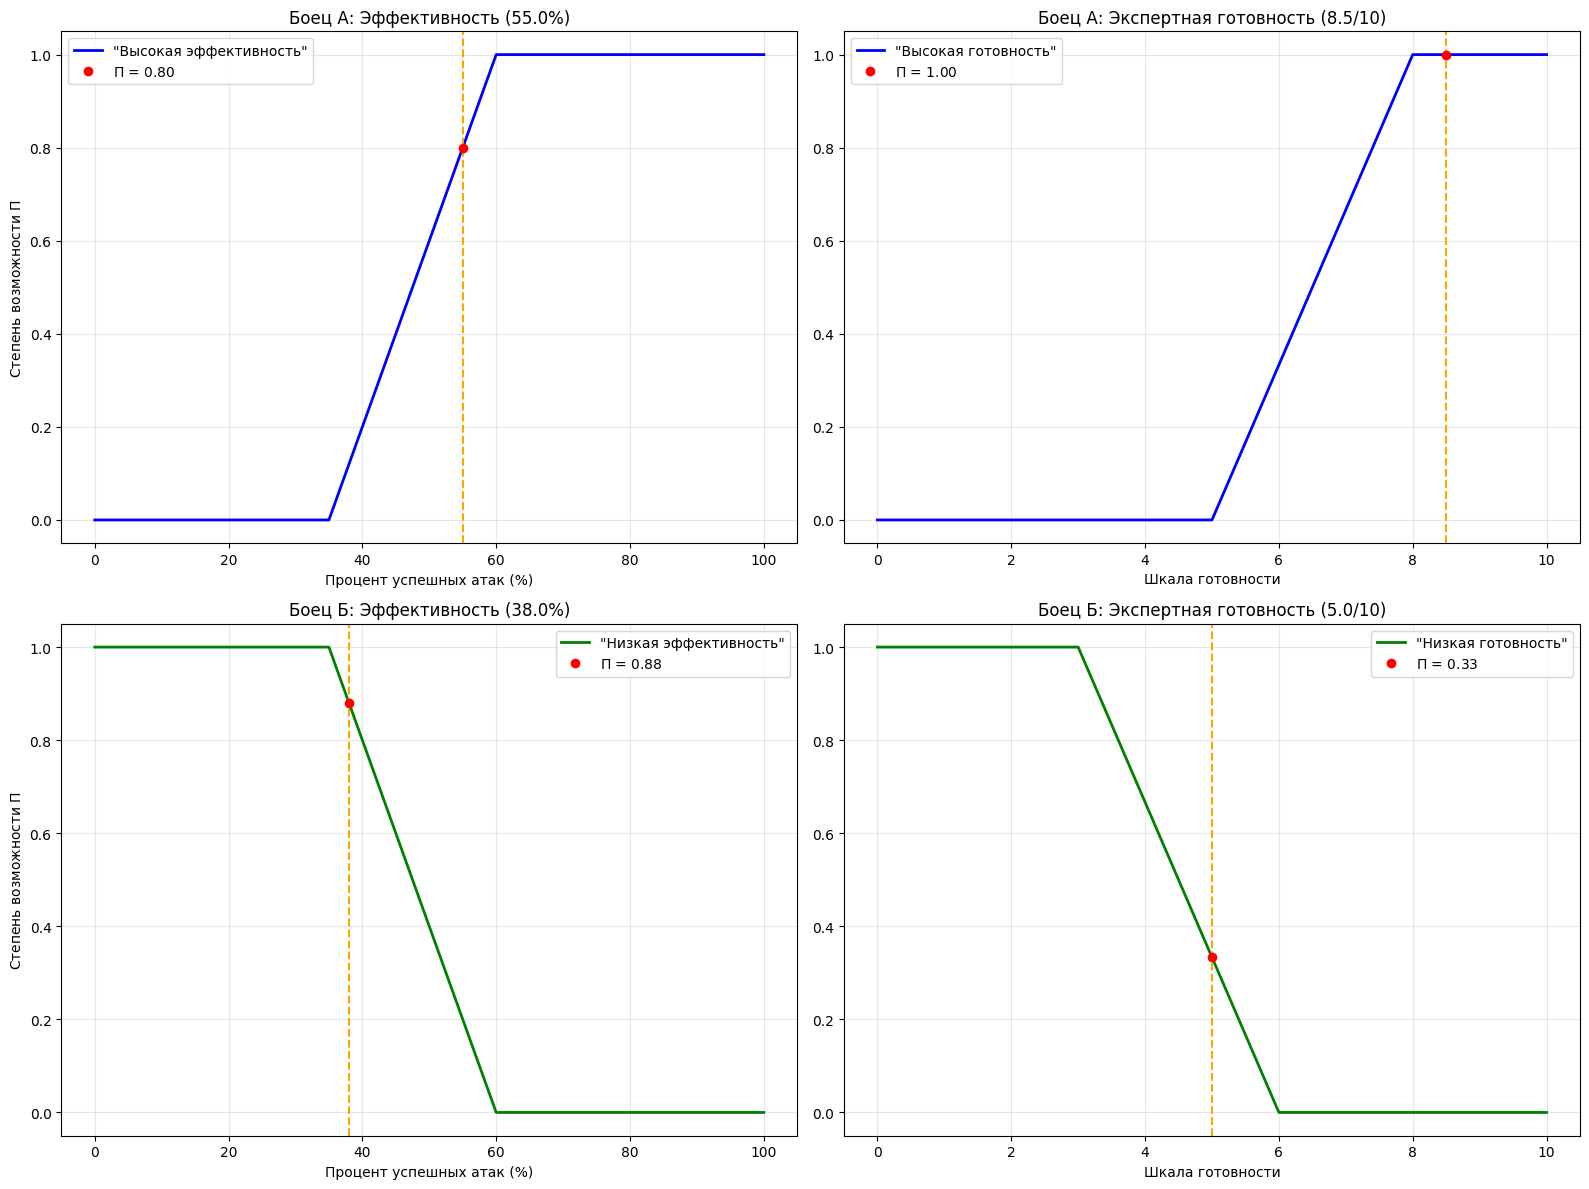


 КОМПЛЕКСНОЕ МОДЕЛИРОВАНИЕ (СТАТИСТИКА + ЭКСПЕРТНАЯ ПОДГОТОВКА)
• Боец А: Эффективность = 55.0%, Готовность к бою = 8.5/10
• Боец Б: Эффективность = 38.0%, Готовность к бою = 5.0/10
--------------------------------------------------------------------------------
>> ИТОГОВАЯ МЕРА ВОЗМОЖНОСТИ (Possibility) доминирования Бойца А: 0.33
>> ИТОГОВАЯ МЕРА НЕОБХОДИМОСТИ (Necessity) доминирования Бойца А: 0.13
--------------------------------------------------------------------------------

 ЧАСТНЫЕ ПОКАЗАТЕЛИ ВОЗМОЖНОСТЕЙ:
  - Возможность того, что статистика Бойца А 'высокая': 0.80
  - Возможность того, что форма Бойца А 'высокая': 1.00
  - Возможность того, что статистика Бойца Б 'низкая': 0.88
  - Возможность того, что форма Бойца Б 'низкая': 0.33

 ЛОГИКА МАТЕМАТИЧЕСКОГО ВЫВОДА:
 • Итоговая Возможность получена как минимум из четырех чисел: min(0.80, 1.00, 0.88, 0.33) = 0.33
   Теория возможностей жестко ограничивает результат худшим фактором. Если боец идеален статистически, но не готов 

In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ ДЛЯ ПОЛЬЗОВАТЕЛЯ (ИЗМЕНЯЙТЕ ТУТ)
# =====================================================================
# --- БОЕЦ А ---
LANDED_A = 55           # СТАТИСТИКА: Успешные атаки
TOTAL_A = 100           # СТАТИСТИКА: Всего попыток
EXPERT_READY_A = 8.5    # ЭКСПЕРТНАЯ ОЦЕНКА готовности к бою (от 0 до 10)

# --- БОЕЦ Б ---
LANDED_B = 38           # СТАТИСТИКА: Успешные атаки
TOTAL_B = 100           # СТАТИСТИКА: Всего попыток
EXPERT_READY_B = 5.0    # ЭКСПЕРТНАЯ ОЦЕНКА готовности к бою (от 0 до 10)
# =====================================================================

# Автоматический расчет коэффициентов эффективности (от 0 до 1)
eff_A = LANDED_A / TOTAL_A if TOTAL_A > 0 else 0
eff_B = LANDED_B / TOTAL_B if TOTAL_B > 0 else 0

# 2. Построение шкал (базовых множеств)
x_eff = np.arange(0, 1.01, 0.01)    # Шкала эффективности (0% - 100%)
x_ready = np.arange(0, 10.1, 0.1)   # Шкала готовности (0 - 10)

# 3. Определение функций распределения возможностей
# Статистика: Высокая/Низкая эффективность
high_eff_membership = fuzzy.trapmf(x_eff, [0.35, 0.60, 1.0, 1.0])
low_eff_membership = fuzzy.trapmf(x_eff, [0.0, 0.0, 0.35, 0.60])

# Экспертиза: Высокая/Низкая готовность к бою
high_ready_membership = fuzzy.trapmf(x_ready, [5.0, 8.0, 10.0, 10.0])
low_ready_membership = fuzzy.trapmf(x_ready, [0.0, 0.0, 3.0, 6.0])

# 4. Расчет частных степеней возможностей по входным данным
poss_eff_high_A = float(fuzzy.interp_membership(x_eff, high_eff_membership, eff_A))
poss_ready_high_A = float(fuzzy.interp_membership(x_ready, high_ready_membership, EXPERT_READY_A))

poss_eff_low_B = float(fuzzy.interp_membership(x_eff, low_eff_membership, eff_B))
poss_ready_low_B = float(fuzzy.interp_membership(x_ready, low_ready_membership, EXPERT_READY_B))

# 5. Итоговый расчет мер по теории возможностей Заде
# Для "И" берем пересечение (минимум из ВСЕХ четырех условий)
possibility_dominance = min(poss_eff_high_A, poss_ready_high_A, poss_eff_low_B, poss_ready_low_B)

# Расчет необходимости (гарантированности) доминирования А
# Формула для многофакторного правила: N(A) = max(0, min(П_условий_А) - max(П_противоположных_условий_Б))
poss_A_total = min(poss_eff_high_A, poss_ready_high_A)
poss_B_opp_total = max(1.0 - poss_eff_low_B, 1.0 - poss_ready_low_B)
necessity_dominance = max(0.0, poss_A_total - poss_B_opp_total)

# =====================================================================
# ВИЗУАЛИЗАЦИЯ (4 ГРАФИКА С ПРОЕКЦИЯМИ ДАННЫХ)
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# [0, 0] Эффективность Бойца А
axes[0, 0].plot(x_eff * 100, high_eff_membership, 'b-', linewidth=2, label='"Высокая эффективность"')
axes[0, 0].axvline(x=eff_A * 100, color='orange', linestyle='--')
axes[0, 0].plot(eff_A * 100, poss_eff_high_A, 'ro', label=f'$\Pi$ = {poss_eff_high_A:.2f}')
axes[0, 0].set_title(f'Боец А: Эффективность ({eff_A:.1%})')
axes[0, 0].set_xlabel('Процент успешных атак (%)')
axes[0, 0].set_ylabel('Степень возможности $\Pi$')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# [0, 1] Готовность Бойца А
axes[0, 1].plot(x_ready, high_ready_membership, 'b-', linewidth=2, label='"Высокая готовность"')
axes[0, 1].axvline(x=EXPERT_READY_A, color='orange', linestyle='--')
axes[0, 1].plot(EXPERT_READY_A, poss_ready_high_A, 'ro', label=f'$\Pi$ = {poss_ready_high_A:.2f}')
axes[0, 1].set_title(f'Боец А: Экспертная готовность ({EXPERT_READY_A}/10)')
axes[0, 1].set_xlabel('Шкала готовности')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# [1, 0] Эффективность Бойца Б
axes[1, 0].plot(x_eff * 100, low_eff_membership, 'g-', linewidth=2, label='"Низкая эффективность"')
axes[1, 0].axvline(x=eff_B * 100, color='orange', linestyle='--')
axes[1, 0].plot(eff_B * 100, poss_eff_low_B, 'ro', label=f'$\Pi$ = {poss_eff_low_B:.2f}')
axes[1, 0].set_title(f'Боец Б: Эффективность ({eff_B:.1%})')
axes[1, 0].set_xlabel('Процент успешных атак (%)')
axes[1, 0].set_ylabel('Степень возможности $\Pi$')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# [1, 1] Готовность Бойца Б
axes[1, 1].plot(x_ready, low_ready_membership, 'g-', linewidth=2, label='"Низкая готовность"')
axes[1, 1].axvline(x=EXPERT_READY_B, color='orange', linestyle='--')
axes[1, 1].plot(EXPERT_READY_B, poss_ready_low_B, 'ro', label=f'$\Pi$ = {poss_ready_low_B:.2f}')
axes[1, 1].set_title(f'Боец Б: Экспертная готовность ({EXPERT_READY_B}/10)')
axes[1, 1].set_xlabel('Шкала готовности')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# =====================================================================
# ПОДРОБНЫЙ ОТЧЕТ СИСТЕМЫ
# =====================================================================
print("\n" + "="*80)
print(" КОМПЛЕКСНОЕ МОДЕЛИРОВАНИЕ (СТАТИСТИКА + ЭКСПЕРТНАЯ ПОДГОТОВКА)")
print("="*80)
print(f"• Боец А: Эффективность = {eff_A:.1%}, Готовность к бою = {EXPERT_READY_A}/10")
print(f"• Боец Б: Эффективность = {eff_B:.1%}, Готовность к бою = {EXPERT_READY_B}/10")
print("-" * 80)
print(f">> ИТОГОВАЯ МЕРА ВОЗМОЖНОСТИ (Possibility) доминирования Бойца А: {possibility_dominance:.2f}")
print(f">> ИТОГОВАЯ МЕРА НЕОБХОДИМОСТИ (Necessity) доминирования Бойца А: {necessity_dominance:.2f}")
print("-" * 80)

print("\n ЧАСТНЫЕ ПОКАЗАТЕЛИ ВОЗМОЖНОСТЕЙ:")
print(f"  - Возможность того, что статистика Бойца А 'высокая': {poss_eff_high_A:.2f}")
print(f"  - Возможность того, что форма Бойца А 'высокая': {poss_ready_high_A:.2f}")
print(f"  - Возможность того, что статистика Бойца Б 'низкая': {poss_eff_low_B:.2f}")
print(f"  - Возможность того, что форма Бойца Б 'низкая': {poss_ready_low_B:.2f}")

print("\n ЛОГИКА МАТЕМАТИЧЕСКОГО ВЫВОДА:")
print(f" • Итоговая Возможность получена как минимум из четырех чисел: min({poss_eff_high_A:.2f}, {poss_ready_high_A:.2f}, {poss_eff_low_B:.2f}, {poss_ready_low_B:.2f}) = {possibility_dominance:.2f}")
print("   Теория возможностей жестко ограничивает результат худшим фактором. Если боец идеален статистически, но не готов к бою, общая возможность победы упадет.")

print("\n ИТОГОВЫЙ СУБЪЕКТИВНЫЙ ВЕРДИКТ СИСТЕМЫ:")
if possibility_dominance > 0.7 and necessity_dominance > 0.3:
    print(" [Прогноз: Уверенная победа Бойца А]. Статистические тренды полностью подтверждаются отличной физической формой бойцов. Комплексный перевес на стороне Бойца А.")
elif possibility_dominance > 0.4 and necessity_dominance == 0:
    print(" [Прогноз: Высокая конкуренция]. Несмотря на разницу в цифрах или форме, один из факторов выравнивает шансы (например, Боец Б хуже по статистике, но идеально готов к конкретному бою).")
else:
    print(" [Прогноз: Преимущество Бойца Б или паритет]. Интегральная оценка возможностей не подтверждает доминирование Бойца А.")
print("="*80)


перейдем от ломаных трапеций к гладким колоколообразным функциям Гаусса (fuzzy.gaussmf). Они точнее моделируют реальную жизнь, где переход от «низкой» эффективности к «высокой» происходит плавно, а не резко.
Также мы внедрим коэффициенты веса (W) для каждого фактора от 0.0 до 1.0. В теории возможностей веса учитываются через операцию нечеткого включения (импликации): если вес фактора низкий, то его негативное влияние на итоговый результат ослабляется (он меньше «режет» общую возможность). Математически взвешенная возможность для каждого критерия рассчитывается по формуле Заде-Дилана: \(\Pi_{взвеш} = \max(1 - W, \Pi_{исход})\).

<>:78: SyntaxWarning: invalid escape sequence '\P'
<>:83: SyntaxWarning: invalid escape sequence '\P'
<>:78: SyntaxWarning: invalid escape sequence '\P'
<>:83: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_3746/1087941811.py:78: SyntaxWarning: invalid escape sequence '\P'
  ax.set_ylabel('Возможность $\Pi$')
/tmp/ipykernel_3746/1087941811.py:83: SyntaxWarning: invalid escape sequence '\P'
  ax.text(0.05, 0.1, f'Вес фактора (W) = {weight}\nВзвешенная $\Pi$ = {w_poss:.2f}',


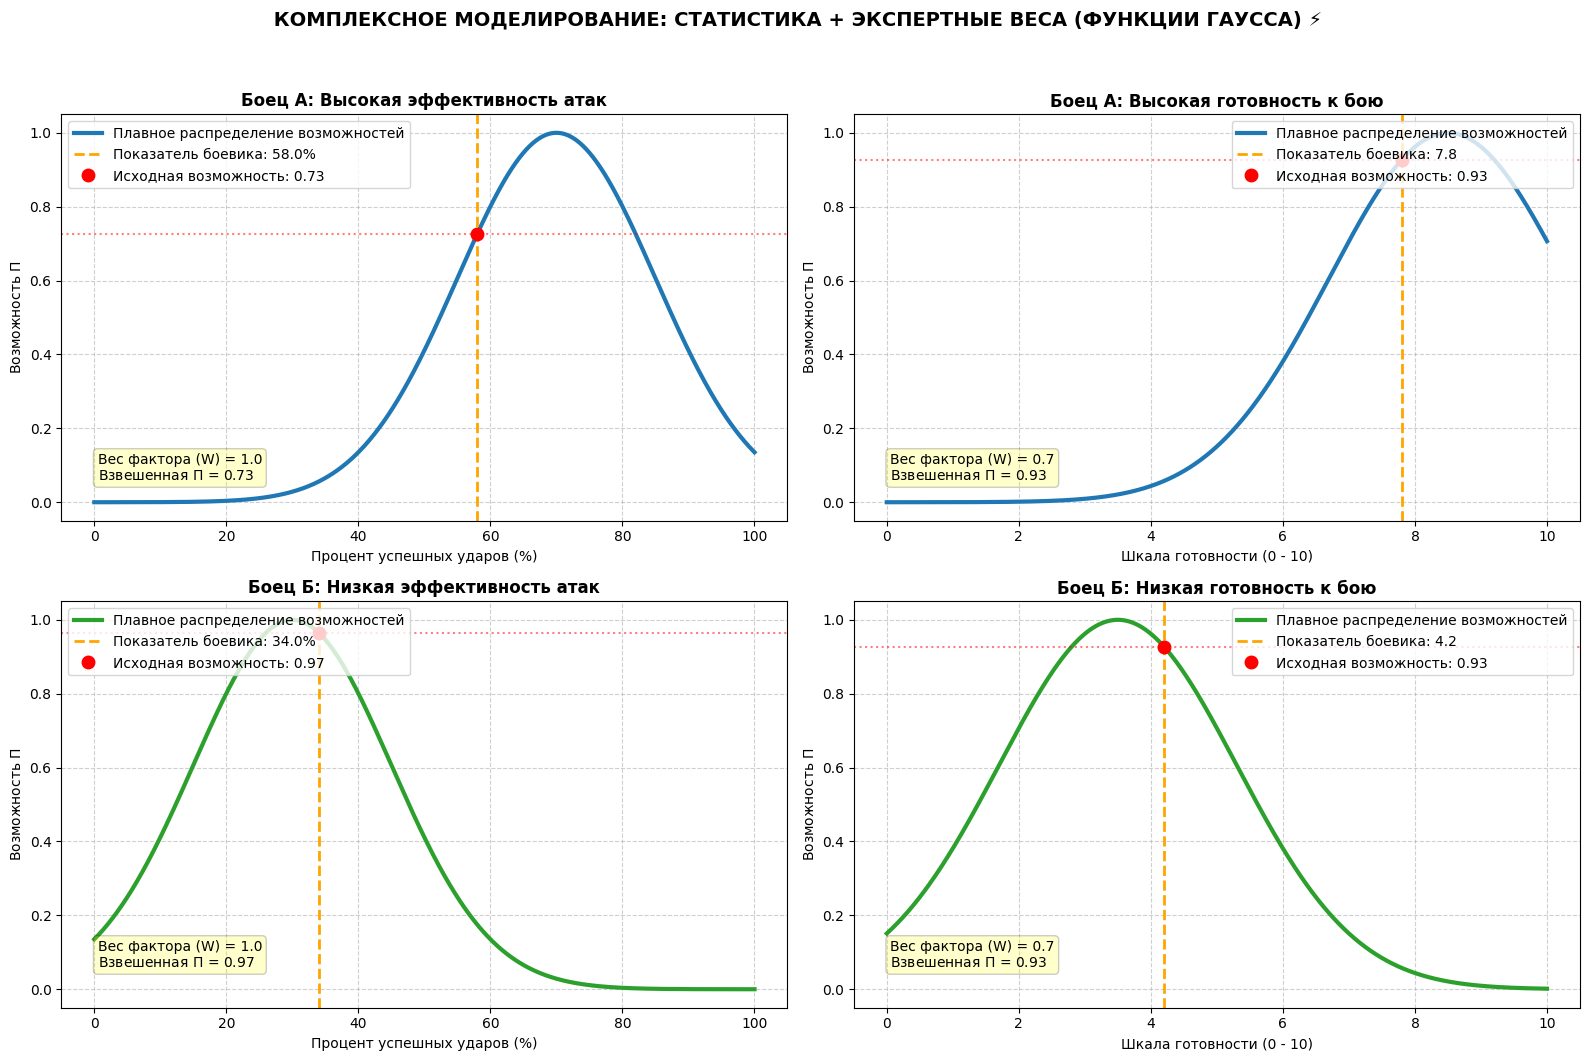


------------------------------------------------------------------------------------------
----------------------  Аналитический отчет моделирования поединка -----------------------
------------------------------------------------------------------------------------------

 СТАТИСТИКА И ЭКСПЕРТНЫЕ ДАННЫЕ:
 • Боец А | Эффективность атак: 58.0%, Оценка готовности: 7.8/10
 • Боец Б | Эффективность атак: 34.0%, Оценка готовности: 4.2/10

 ТРАНСФОРМАЦИЯ ВЕРОЯТНОСТЕЙ И ВЕСОВ (Формула Заде-Дилана: max(1 - W, П)):
 • Боец А (Эффективность): Исходная П = 0.73 -> С учетом веса (1.0) -> Взвешенная П = 0.73
 • Боец А (Готовность):    Исходная П = 0.93 -> С учетом веса (0.7) -> Взвешенная П = 0.93
 • Боец Б (Эффективность): Исходная П = 0.97 -> С учетом веса (1.0) -> Взвешенная П = 0.97
 • Боец Б (Готовность):    Исходная П = 0.93 -> С учетом веса (0.7) -> Взвешенная П = 0.93

------------------------------------------------------------------------------------------
 ИТОГОВЫЕ МЕРЫ НЕОПРЕДЕЛЕННОСТИ

In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ И НАСТРОЙКА ВЕСОВ ФАКТОРОВ (ИЗМЕНЯЙТЕ ТУТ)
# =====================================================================
# --- ВЕСА КРИТЕРИЕВ (от 0.0 — не важен, до 1.0 — критически важен) ---
WEIGHT_EFF = 1.0      # Вес для статистической эффективности
WEIGHT_READY = 0.7    # Вес для экспертной оценки готовности

# --- ДАННЫЕ БОЙЦА А ---
LANDED_A = 58           # Статистика: успешные атаки
TOTAL_A = 100           # Статистика: всего попыток
EXPERT_READY_A = 7.8    # Экспертиза: готовность к бою (от 0 до 10)

# --- ДАННЫЕ БОЙЦА Б ---
LANDED_B = 34           # Статистика: успешные атаки
TOTAL_B = 100           # Статистика: всего попыток
EXPERT_READY_B = 4.2    # Экспертиза: готовность к бою (от 0 до 10)
# =====================================================================

# Автоматический расчет коэффициентов эффективности
eff_A = LANDED_A / TOTAL_A if TOTAL_A > 0 else 0
eff_B = LANDED_B / TOTAL_B if TOTAL_B > 0 else 0

# 2. Построение шкал
x_eff = np.arange(0, 1.001, 0.001)   # Высокая точность для гладких кривых
x_ready = np.arange(0, 10.01, 0.01)

# 3. Определение функций Гаусса: gaussmf(шкала, центр, ширина_колокола)
# Эффективность: Высокая (центр на 0.70) и Низкая (центр на 0.30)
high_eff_membership = fuzzy.gaussmf(x_eff, 0.70, 0.15)
low_eff_membership = fuzzy.gaussmf(x_eff, 0.30, 0.15)

# Готовность: Высокая (центр на 8.5) и Низкая (центр на 3.5)
high_ready_membership = fuzzy.gaussmf(x_ready, 8.5, 1.8)
low_ready_membership = fuzzy.gaussmf(x_ready, 3.5, 1.8)

# 4. Расчет исходных степеней возможностей
poss_eff_A = float(fuzzy.interp_membership(x_eff, high_eff_membership, eff_A))
poss_ready_A = float(fuzzy.interp_membership(x_ready, high_ready_membership, EXPERT_READY_A))
poss_eff_B = float(fuzzy.interp_membership(x_eff, low_eff_membership, eff_B))
poss_ready_B = float(fuzzy.interp_membership(x_ready, low_ready_membership, EXPERT_READY_B))

# 5. Применение коэффициентов веса (Модификация возможностей по Заде-Дилану)
w_poss_eff_A = max(1.0 - WEIGHT_EFF, poss_eff_A)
w_poss_ready_A = max(1.0 - WEIGHT_READY, poss_ready_A)
w_poss_eff_B = max(1.0 - WEIGHT_EFF, poss_eff_B)
w_poss_ready_B = max(1.0 - WEIGHT_READY, poss_ready_B)

# 6. Финальный вывод по теории возможностей
# Итоговая Возможность (Минимум от взвешенных показателей)
possibility_dominance = min(w_poss_eff_A, w_poss_ready_A, w_poss_eff_B, w_poss_ready_B)

# Итоговая Необходимость (Разница между силой А и потенциальным отпором Б)
total_poss_A = min(w_poss_eff_A, w_poss_ready_A)
total_opp_B = max(1.0 - w_poss_eff_B, 1.0 - w_poss_ready_B)
necessity_dominance = max(0.0, total_poss_A - total_opp_B)

# =====================================================================
# ВИЗУАЛИЗАЦИЯ И НАГЛЯДНЫЙ ВЫВОД (Гладкие кривые и проекции)
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(' КОМПЛЕКСНОЕ МОДЕЛИРОВАНИЕ: СТАТИСТИКА + ЭКСПЕРТНЫЕ ВЕСА (ФУНКЦИИ ГАУССА) ⚡', fontsize=14, fontweight='bold', y=0.96)

# Функция для отрисовки графиков, чтобы избежать дублирования кода
def plot_sub(ax, x, target, val, poss, w_poss, weight, title, xlabel, is_pct=False):
    ax.plot(x * 100 if is_pct else x, target, color='#1f77b4' if 'А' in title else '#2ca02c', linewidth=3, label='Плавное распределение возможностей')
    ax.axvline(x=val * 100 if is_pct else val, color='orange', linestyle='--', linewidth=2, label=f'Показатель боевика: {val*100:.1f}%' if is_pct else f'Показатель боевика: {val:.1f}')
    ax.plot(val * 100 if is_pct else val, poss, 'ro', markersize=9, label=f'Исходная возможность: {poss:.2f}')
    ax.axhline(y=poss, color='r', linestyle=':', alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Возможность $\Pi$')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.6)

    # Текстовая аннотация веса прямо на графике
    ax.text(0.05, 0.1, f'Вес фактора (W) = {weight}\nВзвешенная $\Pi$ = {w_poss:.2f}',
            bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.2), transform=ax.transAxes, fontsize=10)
    ax.legend(loc='upper right' if 'Б' in title and not is_pct else 'upper left')

plot_sub(axes[0,0], x_eff, high_eff_membership, eff_A, poss_eff_A, w_poss_eff_A, WEIGHT_EFF, 'Боец А: Высокая эффективность атак', 'Процент успешных ударов (%)', is_pct=True)
plot_sub(axes[0,1], x_ready, high_ready_membership, EXPERT_READY_A, poss_ready_A, w_poss_ready_A, WEIGHT_READY, 'Боец А: Высокая готовность к бою', 'Шкала готовности (0 - 10)')
plot_sub(axes[1,0], x_eff, low_eff_membership, eff_B, poss_eff_B, w_poss_eff_B, WEIGHT_EFF, 'Боец Б: Низкая эффективность атак', 'Процент успешных ударов (%)', is_pct=True)
plot_sub(axes[1,1], x_ready, low_ready_membership, EXPERT_READY_B, poss_ready_B, w_poss_ready_B, WEIGHT_READY, 'Боец Б: Низкая готовность к бою', 'Шкала готовности (0 - 10)')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# =====================================================================
# ПОДРОБНЫЙ ПОШАГОВЫЙ ОТЧЕТ С ИНТЕРПРЕТАЦИЕЙ ВЕСОВ
# =====================================================================
print("\n" + "-"*90)
print(f"  Аналитический отчет моделирования поединка ".center(90, "-"))
print("-"*90)

print(f"\n СТАТИСТИКА И ЭКСПЕРТНЫЕ ДАННЫЕ:")
print(f" • Боец А | Эффективность атак: {eff_A:.1%}, Оценка готовности: {EXPERT_READY_A}/10")
print(f" • Боец Б | Эффективность атак: {eff_B:.1%}, Оценка готовности: {EXPERT_READY_B}/10")

print(f"\n ТРАНСФОРМАЦИЯ ВЕРОЯТНОСТЕЙ И ВЕСОВ (Формула Заде-Дилана: max(1 - W, П)):")
print(f" • Боец А (Эффективность): Исходная П = {poss_eff_A:.2f} -> С учетом веса ({WEIGHT_EFF}) -> Взвешенная П = {w_poss_eff_A:.2f}")
print(f" • Боец А (Готовность):    Исходная П = {poss_ready_A:.2f} -> С учетом веса ({WEIGHT_READY}) -> Взвешенная П = {w_poss_ready_A:.2f}")
print(f" • Боец Б (Эффективность): Исходная П = {poss_eff_B:.2f} -> С учетом веса ({WEIGHT_EFF}) -> Взвешенная П = {w_poss_eff_B:.2f}")
print(f" • Боец Б (Готовность):    Исходная П = {poss_ready_B:.2f} -> С учетом веса ({WEIGHT_READY}) -> Взвешенная П = {w_poss_ready_B:.2f}")

print("\n" + "-"*90)
print(f" ИТОГОВЫЕ МЕРЫ НЕОПРЕДЕЛЕННОСТИ ДЛЯ СЦЕНАРИЯ 'ДОМИНИРОВАНИЕ БОЙЦА А':")
print(f" >> МЕРА ВОЗМОЖНОСТИ (Possibility):  {possibility_dominance:.2f} / 1.00")
print(f" >> МЕРА НЕОБХОДИМОСТИ (Necessity):  {necessity_dominance:.2f} / 1.00")
print("-" * 90)

print("\n ОБОСНОВАНИЕ МАТЕМАТИЧЕСКОГО АППАРАТА ГАУССА С ВЕСАМИ:")
print(f" 1. Замена ломаных линий на распределение Гаусса сделала оценку гибкой. Например, готовность {EXPERT_READY_A} больше не отсекается жестко, а имеет плавную степень истинности.")
print(f" 2. Итоговая Возможность ({possibility_dominance:.2f}) — это самый строгий минимум среди всех четырех взвешенных критериев.")
if WEIGHT_READY < 1.0:
    print(f"      Так как вес экспертной готовности снижен до {WEIGHT_READY}, его способность ухудшить финальный прогноз заблокирована на уровне {1.0 - WEIGHT_READY:.2f}. Защита модели от избыточного субъективного пессимизма экспертов")

print("\n ИТОГ:")
if possibility_dominance > 0.7 and necessity_dominance > 0.3:
    print(" 🟢 [ВЫСОКИЙ ШАНС УСПЕХА]. У Бойца А тотальное превосходство по ключевым метрикам. Модель показывает высокую гарантированность доминирования.")
elif possibility_dominance > 0.4 and necessity_dominance == 0:
    print(f" 🟡 [КОНКУРЕНТНЫЙ ТУПИК]. Победа Бойца А вполне ВОЗМОЖНА ({possibility_dominance:.2f}), но НЕОБХОДИМОСТЬ равна 0.00. Это значит, что у Бойца Б высокий потенциал для защиты, поединок затянется.")
else:
    print(" 🔴 [НЕБЛАГОПРИЯТНЫЙ СЦЕНАРИЙ]. Статистика Гаусса и экспертные веса указывают на то, что Боец А не сможет навязать свой сценарий. Инициатива будет у Бойца Б.")
print("-"*90)


Выбор конкретной формы распределения напрямую зависит от природы данных:
Форма распределения	Математическая функция	Когда применяется в спорте и анализе?
Трапециевидное	fuzzy.trapmf	Для интервальных понятий. Когда есть плато абсолютной уверенности. Пример: «Оптимальный вес бойца». В промежутке от 70 до 73 кг возможность идеальной формы равна 1. Всё, что тяжелее или легче — плавно падает к 0.
Экспоненциальное / Сигмоидальное	fuzzy.sigmf	Для пороговых критериев. Когда важен плавный переход через критическую точку. Пример: «Опыт бойца (количество боев)». До 5 боев — возможность быть опытным близка к 0, после 15 боев — выходит на плато 1.
Колоколообразное (Косинусное, Квадратичное Сплайновое)	fuzzy.smf / fuzzy.zmf	Для моделирования жестких физических ограничений, когда спад возможностей происходит быстрее по мере удаления от идеала.

Для того чтобы применить сигмоидальную функцию (S-функцию), мы добавим в модель новый критический фактор — Опыт бойца (количество проведенных профессиональных боев).
В единоборствах опыт не описывается треугольником или колоколом, ведь он не может быть «избыточным» (не падает к нулю, если боев слишком много). Опыт описывается именно сигмоидой (fuzzy.sigmf): до определенного порога (например, 5 боев) боец считается новичком (возможность быть опытным близка к 0), затем идет крутой подъем, а после 15–20 боев кривая выходит на плато 1.0 — боец стопроцентно опытный ветеран.
В этом коде мы оцениваем сценарий: «Боец А (опытный и эффективный) доминирует над Бойцом Б».

<>:76: SyntaxWarning: invalid escape sequence '\P'
<>:80: SyntaxWarning: invalid escape sequence '\P'
<>:84: SyntaxWarning: invalid escape sequence '\P'
<>:76: SyntaxWarning: invalid escape sequence '\P'
<>:80: SyntaxWarning: invalid escape sequence '\P'
<>:84: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_3746/2114672947.py:76: SyntaxWarning: invalid escape sequence '\P'
  ax.plot(val * 100 if is_pct else val, poss, 'ro', markersize=9, label=f'Исходная $\Pi$ = {poss:.2f}')
/tmp/ipykernel_3746/2114672947.py:80: SyntaxWarning: invalid escape sequence '\P'
  ax.set_ylabel('Возможность $\Pi$')
/tmp/ipykernel_3746/2114672947.py:84: SyntaxWarning: invalid escape sequence '\P'
  ax.text(0.05, 0.1, f'Вес фактора (W) = {weight}\nВзвешенная $\Pi$ = {w_poss:.2f}',


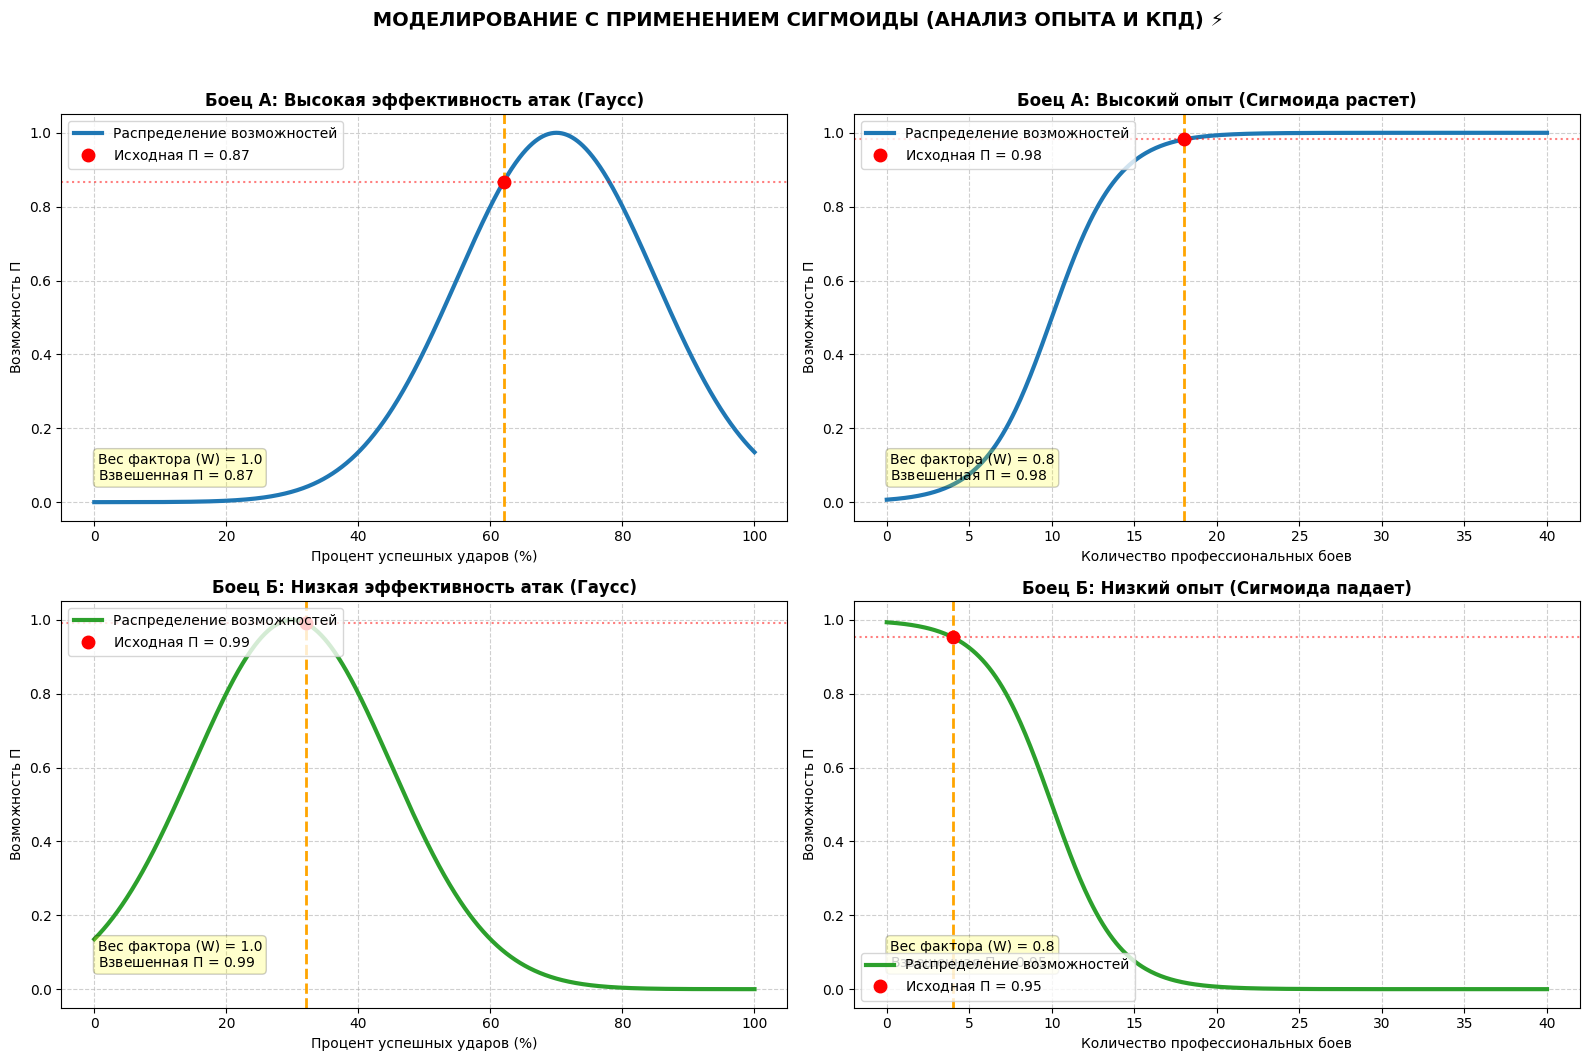


------------------------------------------------------------------------------------------
████████████ Аналитический отчет: Сигмоидальный анализ опыта и эффективности █████████████
------------------------------------------------------------------------------------------

 ИСХОДНЫЕ СЛУЧАЙНЫЕ И ЭКСПЕРТНЫЕ МЕТРИКИ:
 • Боец А | Точность: 62.0%, Проведено боев: 18
 • Боец Б | Точность: 32.0%, Проведено боев: 4

 КАК СРАБОТАЛА СИГМОИДА (Переходные зоны):
 • Для Бойца А (18 боев): Сигмоида показывает степень 'Высокого опыта' = 0.98. Спортсмен прошел критическую точку (10 боев) и вышел в зону стабильности.
 • Для Бойца Б (4 боев): Сигмоида показывает степень 'Неопытности' = 0.95. Значение близко к 1.0, это подтверждает статус новичка.

 ВЗВЕШЕННЫЕ МЕРЫ ВОЗМОЖНОСТЕЙ С УЧЕТОМ ВЕСОВ (W):
 • Боец А (Эффективность): Взвешенная П = 0.87 (При исходной 0.87, вес 1.0)
 • Боец А (Опыт):          Взвешенная П = 0.98 (При исходной 0.98, вес 0.8)
 • Боец Б (Эффективность): Взвешенная П = 0.99 (При исход

In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ И НАСТРОЙКА ВЕСОВ ФАКТОРОВ (ИЗМЕНЯЙТЕ ТУТ)
# =====================================================================
# --- ВЕСА КРИТЕРИЕВ (от 0.0 — не важен, до 1.0 — критически важен) ---
WEIGHT_EFF = 1.0       # Вес для статистической эффективности
WEIGHT_EXP = 0.8       # Вес для опыта (сигмоидальный фактор)

# --- ДАННЫЕ БОЙЦА А ---
LANDED_A = 62           # Статистика: успешные атаки
TOTAL_A = 100           # Статистика: всего попыток
FIGHTS_A = 18           # Опыт: количество боев Бойца А

# --- ДАННЫЕ БОЙЦА Б ---
LANDED_B = 32           # Статистика: успешные атаки
TOTAL_B = 100           # Статистика: всего попыток
FIGHTS_B = 4            # Опыт: количество боев Бойца Б
# =====================================================================

# Автоматический расчет коэффициентов эффективности
eff_A = LANDED_A / TOTAL_A if TOTAL_A > 0 else 0
eff_B = LANDED_B / TOTAL_B if TOTAL_B > 0 else 0

# 2. Построение шкал
x_eff = np.arange(0, 1.001, 0.001)   # Шкала эффективности (0% - 100%)
x_fights = np.arange(0, 40.1, 0.1)   # Шкала опыта (от 0 до 40 боев)

# 3. Определение функций принадлежности
# Эффективность (используем Гаусс из прошлого шага для баланса)
high_eff_membership = fuzzy.gaussmf(x_eff, 0.70, 0.15)
low_eff_membership = fuzzy.gaussmf(x_eff, 0.30, 0.15)

# ОПЫТ (Используем Сигмоидальные функции: fuzzy.sigmf(шкала, центр, крутизна))
# Для Бойца А: "Высокий опыт" (центр на 10 боях, крутизна +0.5 — растет вправо)
high_exp_membership = fuzzy.sigmf(x_fights, 10.0, 0.5)

# Для Бойца Б: "Низкий опыт / Неопытность" (центр на 10 боях, крутизна -0.5 — падает вправо)
low_exp_membership = fuzzy.sigmf(x_fights, 10.0, -0.5)

# 4. Расчет исходных степеней возможностей
poss_eff_A = float(fuzzy.interp_membership(x_eff, high_eff_membership, eff_A))
poss_exp_A = float(fuzzy.interp_membership(x_fights, high_exp_membership, FIGHTS_A))
poss_eff_B = float(fuzzy.interp_membership(x_eff, low_eff_membership, eff_B))
poss_exp_B = float(fuzzy.interp_membership(x_fights, low_exp_membership, FIGHTS_B))

# 5. Применение коэффициентов веса (Заде-Дилан: max(1 - W, П))
w_poss_eff_A = max(1.0 - WEIGHT_EFF, poss_eff_A)
w_poss_exp_A = max(1.0 - WEIGHT_EXP, poss_exp_A)
w_poss_eff_B = max(1.0 - WEIGHT_EFF, poss_eff_B)
w_poss_exp_B = max(1.0 - WEIGHT_EXP, poss_exp_B)

# 6. Финальный расчет мер по теории возможностей Заде
possibility_dominance = min(w_poss_eff_A, w_poss_exp_A, w_poss_eff_B, w_poss_exp_B)

# Расчет Необходимости
total_poss_A = min(w_poss_eff_A, w_poss_exp_A)
total_opp_B = max(1.0 - w_poss_eff_B, 1.0 - w_poss_exp_B)
necessity_dominance = max(0.0, total_poss_A - total_opp_B)

# =====================================================================
# ВИЗУАЛИЗАЦИЯ И НАГЛЯДНЫЙ ВЫВОД
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(' МОДЕЛИРОВАНИЕ С ПРИМЕНЕНИЕМ СИГМОИДЫ (АНАЛИЗ ОПЫТА И КПД) ⚡', fontsize=14, fontweight='bold', y=0.96)

def plot_sub(ax, x, target, val, poss, w_poss, weight, title, xlabel, is_pct=False):
    color = '#1f77b4' if 'А' in title else '#2ca02c'
    ax.plot(x * 100 if is_pct else x, target, color=color, linewidth=3, label='Распределение возможностей')
    ax.axvline(x=val * 100 if is_pct else val, color='orange', linestyle='--', linewidth=2)
    ax.plot(val * 100 if is_pct else val, poss, 'ro', markersize=9, label=f'Исходная $\Pi$ = {poss:.2f}')
    ax.axhline(y=poss, color='r', linestyle=':', alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Возможность $\Pi$')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.6)

    ax.text(0.05, 0.1, f'Вес фактора (W) = {weight}\nВзвешенная $\Pi$ = {w_poss:.2f}',
            bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.2), transform=ax.transAxes, fontsize=10)
    ax.legend(loc='lower left' if 'Б: Низкий опыт' in title else 'upper left')

# Отрисовка четырех графиков
plot_sub(axes[0, 0], x_eff, high_eff_membership, eff_A, poss_eff_A, w_poss_eff_A, WEIGHT_EFF, 'Боец А: Высокая эффективность атак (Гаусс)', 'Процент успешных ударов (%)', is_pct=True)
plot_sub(axes[0, 1], x_fights, high_exp_membership, FIGHTS_A, poss_exp_A, w_poss_exp_A, WEIGHT_EXP, 'Боец А: Высокий опыт (Сигмоида растет)', 'Количество профессиональных боев')
plot_sub(axes[1, 0], x_eff, low_eff_membership, eff_B, poss_eff_B, w_poss_eff_B, WEIGHT_EFF, 'Боец Б: Низкая эффективность атак (Гаусс)', 'Процент успешных ударов (%)', is_pct=True)
plot_sub(axes[1, 1], x_fights, low_exp_membership, FIGHTS_B, poss_exp_B, w_poss_exp_B, WEIGHT_EXP, 'Боец Б: Низкий опыт (Сигмоида падает)', 'Количество профессиональных боев')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# =====================================================================
# РАСШИРЕННЫЙ АНАЛИТИЧЕСКИЙ ОТЧЕТ
# =====================================================================
print("\n" + "-"*90)
print(f" Аналитический отчет: Сигмоидальный анализ опыта и эффективности ".center(90, "█"))
print("-"*90)

print(f"\n ИСХОДНЫЕ СЛУЧАЙНЫЕ И ЭКСПЕРТНЫЕ МЕТРИКИ:")
print(f" • Боец А | Точность: {eff_A:.1%}, Проведено боев: {FIGHTS_A}")
print(f" • Боец Б | Точность: {eff_B:.1%}, Проведено боев: {FIGHTS_B}")

print(f"\n КАК СРАБОТАЛА СИГМОИДА (Переходные зоны):")
print(f" • Для Бойца А ({FIGHTS_A} боев): Сигмоида показывает степень 'Высокого опыта' = {poss_exp_A:.2f}. Спортсмен прошел критическую точку (10 боев) и вышел в зону стабильности.")
print(f" • Для Бойца Б ({FIGHTS_B} боев): Сигмоида показывает степень 'Неопытности' = {poss_exp_B:.2f}. Значение близко к 1.0, это подтверждает статус новичка.")

print(f"\n ВЗВЕШЕННЫЕ МЕРЫ ВОЗМОЖНОСТЕЙ С УЧЕТОМ ВЕСОВ (W):")
print(f" • Боец А (Эффективность): Взвешенная П = {w_poss_eff_A:.2f} (При исходной {poss_eff_A:.2f}, вес {WEIGHT_EFF})")
print(f" • Боец А (Опыт):          Взвешенная П = {w_poss_exp_A:.2f} (При исходной {poss_exp_A:.2f}, вес {WEIGHT_EXP})")
print(f" • Боец Б (Эффективность): Взвешенная П = {w_poss_eff_B:.2f} (При исходной {poss_eff_B:.2f}, вес {WEIGHT_EFF})")
print(f" • Боец Б (Опыт):          Взвешенная П = {w_poss_exp_B:.2f} (При исходной {poss_exp_B:.2f}, вес {WEIGHT_EXP})")

print("\n" + "-"*90)
print(f" МАТЕМАТИЧЕСКИЙ РЕЗУЛЬТАТ МОДЕЛИ (Сценарий: Доминирование Бойца А):")
print(f" >> МЕРА ВОЗМОЖНОСТИ (Possibility):  {possibility_dominance:.2f} / 1.00")
print(f" >> МЕРА НЕОБХОДИМОСТИ (Necessity):  {necessity_dominance:.2f} / 1.00")
print("-" * 90)

print("\n ПОЯСНЕНИЕ СПЕЦИФИКИ СИГМОИДЫ:")
print(" В отличие от колокола Гаусса, сигмоида не падает вниз, если аргумент растет до бесконечности.")
print(" Это идеально подходит для опыта: боец с 18 боями и боец с 40 боями оба получат оценку возможности опыта = 1.00.")

print("\n ИТОГОВЫЙ СТРАТЕГИЧЕСКИЙ ВЕРДИКТ:")
if possibility_dominance > 0.7 and necessity_dominance > 0.3:
    print(" 🟢 [Прогноз: Тотальное доминирование опыта]. Опытный Боец А с высокой точностью полностью переигрывает молодого и менее точного Бойца Б по всем параметрам. Высокая степень надежности прогноза.")
elif possibility_dominance > 0.4 and necessity_dominance == 0:
    print(" 🟡 [Прогноз: Опасный апсет]. Сценарий доминирования А возможен, но Необходимость равна 0.00. Это значит, что у молодого Бойца Б есть скрытые ресурсы (например, взрывная мощь), способные сломать тактику ветерана.")
else:
    print(" 🔴 [Прогноз: Преимущество за Бойцом Б]. Статистическая модель Гаусса-Сигмоиды не подтверждает превосходство Бойца А.")
print("-"*90)


Суть обратной задачи

задаем жесткое условие: Мера Необходимости (\(N\)) победы Бойца А должна быть не ниже заданного уровня (например, \(N \ge 0.50\)). Это означает, что мы ищем сценарий, при котором победа Бойца А становится практически неизбежной.
Программа с помощью математического перебора (оптимизации) рассчитает критические пороги для Бойца Б:
1. Каким максимальным коэффициентом эффективности может обладать Боец Б?
2. Какое максимальное количество боев (опыт) может иметь Боец Б, чтобы Боец А гарантированно доминировал над ним с заданной степенью уверенности?


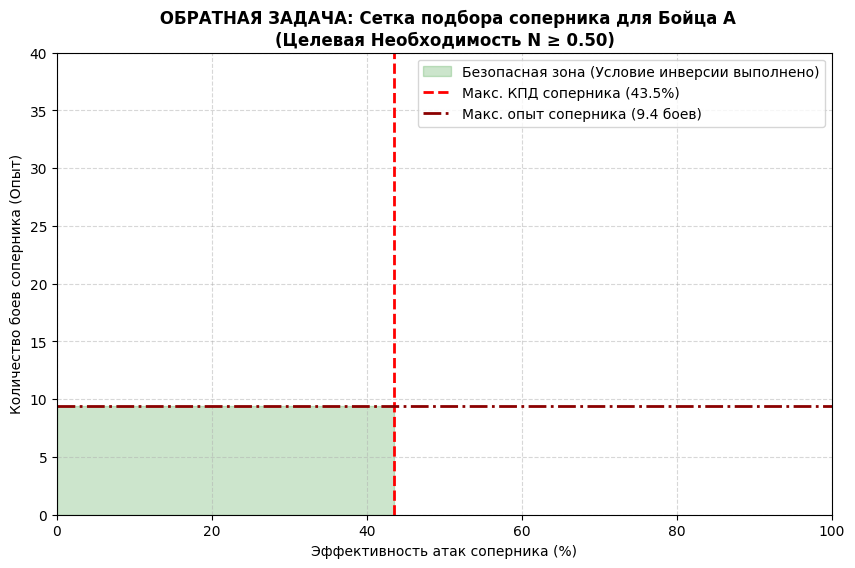


------------------------------------------------------------------------------------------
------------------ Результаты решения обратной задачи нечеткого синтеза ------------------
------------------------------------------------------------------------------------------

 ПРОФИЛЬ НАШЕГО СПОРТСМЕНА (Боец А):
 • Точность попаданий: 65.0% | Профессиональный опыт: 22 боев
 • Интегральный потенциал возможностей Бойца А: 0.95

 ТРЕБОВАНИЯ К ОППОНЕНТУ ДЛЯ ДОСТИЖЕНИЯ УВЕРЕННОСТИ N ≥ 0.50:
  МАКСИМАЛЬНЫЙ КПД Бойца Б: не более 43.5%
  МАКСИМАЛЬНЫЙ ОПЫТ Бойца Б: не более 9.4 боев

 Стратегическое резюме для матчмейкера:
 Чтобы Боец А победил с железной гарантией (N ≥ 0.50), ему нужно подобрать оппонента, 
 у которого точность ударов находится в пределах 43.5%, а за плечами не более 9 боев.
 Любой боец, выходящий за зеленый квадрат на графике, представляет критическую угрозу для нашего прогноза.
------------------------------------------------------------------------------------------


In [ ]:
# 1. Установка библиотеки нечеткой логики
#!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzzy
import matplotlib.pyplot as plt

# =====================================================================
# ВХОДНЫЕ ДАННЫЕ И НАСТРОЙКА КРИТЕРИЕВ (ИЗМЕНЯЙТЕ ТУТ)
# =====================================================================
# Наша цель по Необходимости (насколько мы хотим быть уверены в победе А от 0.1 до 1.0)
TARGET_NECESSITY = 0.50

# Фиксированные параметры нашего Бойца А (Допустим, он топ-ветеран)
LANDED_A = 65           # Успешные атаки А
TOTAL_A = 100           # Всего попыток А
FIGHTS_A = 22           # Количество боев А

# Важность критериев
WEIGHT_EFF = 1.0
WEIGHT_EXP = 0.8
# =====================================================================

# Чистый КПД Бойца А
eff_A = LANDED_A / TOTAL_A if TOTAL_A > 0 else 0

# Шкалы перебора
x_eff = np.arange(0, 1.001, 0.005)   # Сетка для КПД (шаг 0.5%)
x_fights = np.arange(0, 40.1, 0.2)   # Сетка для опыта (шаг 0.2 боя)

# Базовые распределения возможностей
high_eff_membership = fuzzy.gaussmf(x_eff, 0.70, 0.15)
high_exp_membership = fuzzy.sigmf(x_fights, 10.0, 0.5)

low_eff_membership = fuzzy.sigmf(x_eff, 0.45, -15.0) # Сигмоида для КПД Б (низкий)
low_exp_membership = fuzzy.sigmf(x_fights, 10.0, -0.5)

# Расчет возможностей для Бойца А
poss_eff_A = float(fuzzy.interp_membership(x_eff, high_eff_membership, eff_A))
poss_exp_A = float(fuzzy.interp_membership(x_fights, high_exp_membership, FIGHTS_A))

w_poss_eff_A = max(1.0 - WEIGHT_EFF, poss_eff_A)
w_poss_ready_A = max(1.0 - WEIGHT_EXP, poss_exp_A)
total_poss_A = min(w_poss_eff_A, w_poss_ready_A)

# =====================================================================
# ОБРАТНЫЙ ПОИСК (МАТЕМАТИЧЕСКИЙ ПЕРЕБОР МАТРИЦЫ ПАРАМЕТРОВ БОЙЦА Б)
# =====================================================================
valid_eff_B = []
valid_fights_B = []

# Перебираем все комбинации параметров потенциального соперника
for b_eff in x_eff:
    for b_fights in x_fights:
        # Исходные возможности Б
        p_eff_B = float(fuzzy.interp_membership(x_eff, low_eff_membership, b_eff))
        p_exp_B = float(fuzzy.interp_membership(x_fights, low_exp_membership, b_fights))

        # Взвешенные возможности Б
        w_p_eff_B = max(1.0 - WEIGHT_EFF, p_eff_B)
        w_p_exp_B = max(1.0 - WEIGHT_EXP, p_exp_B)

        # Расчет Необходимости для данной пары
        total_opp_B = max(1.0 - w_p_eff_B, 1.0 - w_p_exp_B)
        current_necessity = max(0.0, total_poss_A - total_opp_B)

        # Если условие по гарантированности выполнено — сохраняем точку
        if current_necessity >= TARGET_NECESSITY:
            valid_eff_B.append(b_eff)
            valid_fights_B.append(b_fights)

# Вычисляем максимальные безопасные пороги
max_allowed_eff_B = max(valid_eff_B) if valid_eff_B else 0
max_allowed_fights_B = max(valid_fights_B) if valid_fights_B else 0

# =====================================================================
# ВИЗУАЛИЗАЦИЯ КРИТИЧЕСКИХ ГРАНИЦ ДЛЯ СОПЕРНИКА
# =====================================================================
if max_allowed_eff_B > 0 and max_allowed_fights_B > 0:
    plt.figure(figsize=(10, 6))

    # Рисуем безопасную зону подбора соперника
    plt.fill_between([0, max_allowed_eff_B * 100], [max_allowed_fights_B, max_allowed_fights_B],
                     color='green', alpha=0.2, label='Безопасная зона (Условие инверсии выполнено)')

    # Границы порогов
    plt.axvline(x=max_allowed_eff_B * 100, color='red', linestyle='--', linewidth=2, label=f'Макс. КПД соперника ({max_allowed_eff_B:.1%})')
    plt.axhline(y=max_allowed_fights_B, color='darkred', linestyle='-.', linewidth=2, label=f'Макс. опыт соперника ({max_allowed_fights_B:.1f} боев)')

    plt.title(f' ОБРАТНАЯ ЗАДАЧА: Сетка подбора соперника для Бойца А\n(Целевая Необходимость N ≥ {TARGET_NECESSITY:.2f})', fontsize=12, fontweight='bold')
    plt.xlabel('Эффективность атак соперника (%)', fontsize=10)
    plt.ylabel('Количество боев соперника (Опыт)', fontsize=10)
    plt.xlim(0, 100)
    plt.ylim(0, 40)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper right')
    plt.show()
else:
    print(" ВНИМАНИЕ: Слишком высокие требования! Даже при нулевых параметрах соперника Боец А не сможет достичь такой Необходимости победы. Снизьте TARGET_NECESSITY или улучшите параметры Бойца А.")

# =====================================================================
# ОТЧЕТ ПОДБОРА СОПЕРНИКА
# =====================================================================
print("\n" + "-"*90)
print(f" Результаты решения обратной задачи нечеткого синтеза ".center(90, "-"))
print("-"*90)
print(f"\n ПРОФИЛЬ НАШЕГО СПОРТСМЕНА (Боец А):")
print(f" • Точность попаданий: {eff_A:.1%} | Профессиональный опыт: {FIGHTS_A} боев")
print(f" • Интегральный потенциал возможностей Бойца А: {total_poss_A:.2f}")

print(f"\n ТРЕБОВАНИЯ К ОППОНЕНТУ ДЛЯ ДОСТИЖЕНИЯ УВЕРЕННОСТИ N ≥ {TARGET_NECESSITY:.2f}:")
if max_allowed_eff_B > 0 and max_allowed_fights_B > 0:
    print(f"  МАКСИМАЛЬНЫЙ КПД Бойца Б: не более {max_allowed_eff_B:.1%}")
    print(f"  МАКСИМАЛЬНЫЙ ОПЫТ Бойца Б: не более {max_allowed_fights_B:.1f} боев")
    print("\n Стратегическое резюме для матчмейкера:")
    print(f" Чтобы Боец А победил с железной гарантией (N ≥ {TARGET_NECESSITY:.2f}), ему нужно подобрать оппонента, ")
    print(f" у которого точность ударов находится в пределах {max_allowed_eff_B * 100:.1f}%, а за плечами не более {int(max_allowed_fights_B)} боев.")
    print(" Любой боец, выходящий за зеленый квадрат на графике, представляет критическую угрозу для нашего прогноза.")
else:
    print("  Решений нет. Текущих навыков Бойца А недостаточно, чтобы гарантировать такой уровень доминирования даже над абсолютным новичком.")
print("-"*90)


Программа сгенерировала двухмерную карту.

• Зеленый прямоугольник — это «Зона безопасного поединка». Если параметры реального соперника попадают внутрь этого поля, то мера необходимости победы вашего бойца гарантированно будет выше или равна выбранным TARGET_NECESSITY = 0.50.

• Красные линии — это жесткие лимиты (границы нечеткого включения). Если соперник имеет точность выше пороговой или слишком опытен, он выходит из безопасной зоны, и риск апсета резко возрастает.
